# Modulo 2 — EDA_NLP_RobledoMauro

## Celda 1 — Instalación de dependencias
Primero instalamos las librerías necesarias. También descargamos el modelo de inglés de SpaCy, que utilizaremos para la lematización.

In [371]:

# ============================================================
# CELDA 1 — INSTALACIÓN DE DEPENDENCIAS
# ============================================================

# Instalación de las librerías necesarias para el proyecto
!pip install -q pandas numpy matplotlib seaborn scikit-learn spacy reportlab

# Descarga del modelo de inglés de SpaCy
!python -m spacy download en_core_web_sm

print("Instalación de dependencias completada correctamente.")


Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     -- ------------------------------------- 0.8/12.8 MB 10.2 MB/s eta 0:00:02
     --------- ------------------------------ 3.1/12.8 MB 11.5 MB/s eta 0:00:01
     ------------------ --------------------- 5.8/12.8 MB 11.6 MB/s eta 0:00:01
     ------------------------- -------------- 8.1/12.8 MB 11.7 MB/s eta 0:00:01
     -------------------------------- ------ 10.7/12.8 MB 11.7 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 11.5 MB/s  0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
Instalación de dependencias completada correctamente.


## Celda 2 — Importación de librerías
Importamos las herramientas que utilizaremos durante el análisis.

In [372]:

# ============================================================
# CELDA 2 — IMPORTACIÓN DE LIBRERÍAS
# ============================================================

# Manipulación y análisis de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Procesamiento de lenguaje natural
import spacy
import re
import string

# Extracción de N-gramas
from sklearn.feature_extraction.text import CountVectorizer

# Análisis de frecuencias
from collections import Counter

# Utilidades
import os
import warnings

# Configuración general
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

# Configuración de visualización de Pandas
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.max_columns", None)

print("Librerías importadas correctamente.")
print("Versión de Pandas:", pd.__version__)
print("Versión de NumPy:", np.__version__)
print("Versión de SpaCy:", spacy.__version__)


Librerías importadas correctamente.
Versión de Pandas: 3.1.0
Versión de NumPy: 2.5.4
Versión de SpaCy: 3.8.18


## Celda 3 — Carga del dataset
Como estamos en Colab, cargaremos los archivos desde el pc.

In [373]:

# ============================================================
# CELDA 3 — CARGA DEL DATASET AG NEWS
# ============================================================

from pathlib import Path
import pandas as pd

# Obtener la carpeta raíz del proyecto
RUTA_PROYECTO = Path.cwd().parent

# Definir las rutas de los archivos CSV
RUTA_TRAIN = RUTA_PROYECTO / "data" / "raw" / "ag_news_train.csv"
RUTA_TEST = RUTA_PROYECTO / "data" / "raw" / "ag_news_test.csv"

# Verificar que los archivos existan
if not RUTA_TRAIN.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo de entrenamiento: {RUTA_TRAIN}"
    )

if not RUTA_TEST.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo de prueba: {RUTA_TEST}"
    )

# Cargar los conjuntos de entrenamiento y prueba
df_train = pd.read_csv(RUTA_TRAIN)
df_test = pd.read_csv(RUTA_TEST)

print("Datasets cargados correctamente.")

print(f"\nArchivo de entrenamiento: {RUTA_TRAIN.name}")
print("Dimensiones del conjunto de entrenamiento:", df_train.shape)

print(f"\nArchivo de prueba: {RUTA_TEST.name}")
print("Dimensiones del conjunto de prueba:", df_test.shape)

# ============================================================
# CONFIGURACIÓN DE RUTAS DE RESULTADOS
# ============================================================

from pathlib import Path

# Obtener la raíz del proyecto
RUTA_PROYECTO = Path.cwd().parent

# Definir carpetas de resultados
RUTA_FIGURAS = RUTA_PROYECTO / "results" / "figures"
RUTA_METRICAS = RUTA_PROYECTO / "results" / "metrics"

# Crear carpetas si no existen
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)
RUTA_METRICAS.mkdir(parents=True, exist_ok=True)

print("Rutas configuradas correctamente.")


Datasets cargados correctamente.

Archivo de entrenamiento: ag_news_train.csv
Dimensiones del conjunto de entrenamiento: (8000, 2)

Archivo de prueba: ag_news_test.csv
Dimensiones del conjunto de prueba: (2000, 2)
Rutas configuradas correctamente.


## Celda 4 — Validación estructural del dataset
Esta celda permite verificar automáticamente:
- Dimensiones de ambos conjuntos.
- Columnas disponibles.
- Tipos de datos.
- Valores nulos.
- Filas duplicadas.
- Distribución de categorías.
- Balance entre clases.

In [374]:

# ============================================================
# CELDA 4 — VALIDACIÓN ESTRUCTURAL DEL DATASET
# ============================================================

# ------------------------------------------------------------
# 1. Verificar dimensiones
# ------------------------------------------------------------

print("DIMENSIONES DEL DATASET")
print("-" * 50)

print(f"Train: {df_train.shape[0]} filas y {df_train.shape[1]} columnas")
print(f"Test:  {df_test.shape[0]} filas y {df_test.shape[1]} columnas")


# ------------------------------------------------------------
# 2. Verificar estructura y columnas
# ------------------------------------------------------------

columnas_esperadas = ["text", "label"]

assert list(df_train.columns) == columnas_esperadas, \
    "Las columnas de Train no coinciden con las esperadas."

assert list(df_test.columns) == columnas_esperadas, \
    "Las columnas de Test no coinciden con las esperadas."

print("\nColumnas verificadas correctamente:")
print(df_train.columns.tolist())


# ------------------------------------------------------------
# 3. Verificar tipos de datos
# ------------------------------------------------------------

print("\nTIPOS DE DATOS")
print("-" * 50)

print("Train:")
print(df_train.dtypes)

print("\nTest:")
print(df_test.dtypes)


# ------------------------------------------------------------
# 4. Verificar valores nulos
# ------------------------------------------------------------

print("\nVALORES NULOS")
print("-" * 50)

print("Train:")
print(df_train.isnull().sum())

print("\nTest:")
print(df_test.isnull().sum())


# ------------------------------------------------------------
# 5. Verificar registros duplicados
# ------------------------------------------------------------

print("\nREGISTROS DUPLICADOS")
print("-" * 50)

print("Train:", df_train.duplicated().sum())
print("Test:", df_test.duplicated().sum())

print("Textos duplicados en Train:", df_train["text"].duplicated().sum())
print("Textos duplicados en Test:", df_test["text"].duplicated().sum())


# ------------------------------------------------------------
# 6. Verificar distribución de categorías
# ------------------------------------------------------------

print("\nDISTRIBUCIÓN DE CATEGORÍAS")
print("-" * 50)

print("TRAIN:")
print(df_train["label"].value_counts().sort_index())

print("\nTEST:")
print(df_test["label"].value_counts().sort_index())


# ------------------------------------------------------------
# 7. Verificar consistencia entre categorías
# ------------------------------------------------------------

categorias_train = set(df_train["label"].unique())
categorias_test = set(df_test["label"].unique())

assert categorias_train == categorias_test, \
    "Las categorías de Train y Test no coinciden."

print("\nCategorías verificadas:")
print(sorted(categorias_train))


# ------------------------------------------------------------
# 8. Resumen de validación
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("VALIDACIÓN FINAL")
print("=" * 50)

print("Train sin valores nulos:", df_train.isnull().sum().sum() == 0)
print("Test sin valores nulos:", df_test.isnull().sum().sum() == 0)
print("Categorías consistentes:", categorias_train == categorias_test)
print("Estructura de columnas correcta:", list(df_train.columns) == columnas_esperadas)

print("\nValidación estructural finalizada.")


DIMENSIONES DEL DATASET
--------------------------------------------------
Train: 8000 filas y 2 columnas
Test:  2000 filas y 2 columnas

Columnas verificadas correctamente:
['text', 'label']

TIPOS DE DATOS
--------------------------------------------------
Train:
text     str
label    str
dtype: object

Test:
text     str
label    str
dtype: object

VALORES NULOS
--------------------------------------------------
Train:
text     0
label    0
dtype: int64

Test:
text     0
label    0
dtype: int64

REGISTROS DUPLICADOS
--------------------------------------------------
Train: 0
Test: 0
Textos duplicados en Train: 0
Textos duplicados en Test: 0

DISTRIBUCIÓN DE CATEGORÍAS
--------------------------------------------------
TRAIN:
label
Business    2000
Sci_Tech    2000
Sports      2000
World       2000
Name: count, dtype: int64

TEST:
label
Business    500
Sci_Tech    500
Sports      500
World       500
Name: count, dtype: int64

Categorías verificadas:
['Business', 'Sci_Tech', 'Sports',

## Celda 5 — Configuración de SpaCy
Vamos a cargar el modelo en_core_web_sm, que contiene componentes lingüísticos para inglés.

Lo utilizaremos para:
- Tokenización: separar el texto en unidades lingüísticas.
- Lematización: reducir las palabras a su forma base.
- Identificación de stop-words: reconocer palabras frecuentes con poco contenido informativo.
- Identificación de puntuación y espacios.

In [375]:

# ============================================================
# CELDA 5 — CONFIGURACIÓN DE SPACY
# ============================================================

# Cargar el modelo lingüístico de inglés
nlp = spacy.load("en_core_web_sm")

# Verificar los componentes disponibles
print("Modelo SpaCy cargado correctamente.")
print("Modelo:", nlp.meta["name"])
print("Versión:", nlp.meta["version"])

print("\nComponentes del pipeline:")
print(nlp.pipe_names)

# Verificar el funcionamiento del modelo
texto_prueba = "The companies are developing new technologies."

doc = nlp(texto_prueba)

print("\nPRUEBA DE PROCESAMIENTO")
print("-" * 50)

for token in doc:
    print(
        f"Token: {token.text:<15} "
        f"Lema: {token.lemma_:<15} "
        f"Stop-word: {token.is_stop}"
    )


Modelo SpaCy cargado correctamente.
Modelo: core_web_sm
Versión: 3.8.0

Componentes del pipeline:
['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']

PRUEBA DE PROCESAMIENTO
--------------------------------------------------
Token: The             Lema: the             Stop-word: True
Token: companies       Lema: company         Stop-word: False
Token: are             Lema: be              Stop-word: True
Token: developing      Lema: develop         Stop-word: False
Token: new             Lema: new             Stop-word: False
Token: technologies    Lema: technology      Stop-word: False
Token: .               Lema: .               Stop-word: False


## Celda 6 — Implementación de preprocess_text()
Ahora construiremos nuestra función principal de preprocesamiento.

El pipeline tendrá cuatro etapas:


```
Texto original

Noticia en inglés


1. Limpieza Regex

HTML, URLs, caracteres especiales y ruido


2. Normalización

Minúsculas y espacios uniformes


3. Procesamiento SpaCy

Tokenización, stop-words y lematización


Resultado
Texto normalizado y lematizado
```




In [376]:

# ============================================================
# CELDA 6 — FUNCIÓN DE PREPROCESAMIENTO
# ============================================================

def preprocess_text(text):
    """
    Limpia, normaliza y lematiza un texto en inglés.

    Parámetros:
        text (str): Texto original de la noticia.

    Retorna:
        str: Texto limpio y lematizado.
    """

    # --------------------------------------------------------
    # 1. Validar el contenido de entrada
    # --------------------------------------------------------

    if not isinstance(text, str):
        return ""

    # --------------------------------------------------------
    # 2. Limpieza mediante expresiones regulares
    # --------------------------------------------------------

    # Eliminar etiquetas HTML
    text = re.sub(r"<[^>]+>", " ", text)

    # Eliminar direcciones URL
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Eliminar direcciones de correo electrónico
    text = re.sub(r"\S+@\S+", " ", text)

    # Eliminar menciones y etiquetas tipo hashtag
    text = re.sub(r"[@#]\w+", " ", text)

    # Conservar letras y espacios, eliminando números y puntuación
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # --------------------------------------------------------
    # 3. Normalización del texto
    # --------------------------------------------------------

    # Convertir todas las letras a minúsculas
    text = text.lower()

    # Eliminar espacios repetidos
    text = re.sub(r"\s+", " ", text).strip()

    # --------------------------------------------------------
    # 4. Procesamiento lingüístico con SpaCy
    # --------------------------------------------------------

    doc = nlp(text)

    tokens_procesados = []

    for token in doc:

        # Eliminar espacios y stop-words
        if token.is_space or token.is_stop:
            continue

        # Eliminar puntuación
        if token.is_punct:
            continue

        # Obtener el lema de cada palabra
        lema = token.lemma_.lower().strip()

        # Conservar únicamente lemas alfabéticos válidos
        if lema.isalpha() and len(lema) > 1:
            tokens_procesados.append(lema)

    # --------------------------------------------------------
    # 5. Reconstruir el texto procesado
    # --------------------------------------------------------

    return " ".join(tokens_procesados)


print("Función preprocess_text() definida correctamente.")


Función preprocess_text() definida correctamente.


## Celda 7 — Prueba del pipeline
Antes de procesar los 8.000 documentos, vamos a comprobar que la función se comporte correctamente con ejemplos controlados.

In [377]:

# ============================================================
# CELDA 7 — PRUEBA DEL PIPELINE
# ============================================================

# Texto de prueba con diferentes elementos
texto_original = """
The companies are developing new technologies.
Visit https://example.com for more information.
The players were running quickly during the match!
"""

# Aplicar el preprocesamiento
texto_procesado = preprocess_text(texto_original)

print("TEXTO ORIGINAL")
print("-" * 50)
print(texto_original)

print("\nTEXTO PROCESADO")
print("-" * 50)
print(texto_procesado)

print("\nCOMPARACIÓN")
print("-" * 50)
print("Palabras originales:", len(texto_original.split()))
print("Tokens procesados:", len(texto_procesado.split()))


TEXTO ORIGINAL
--------------------------------------------------

The companies are developing new technologies.
Visit https://example.com for more information.
The players were running quickly during the match!


TEXTO PROCESADO
--------------------------------------------------
company develop new technology visit information player run quickly match

COMPARACIÓN
--------------------------------------------------
Palabras originales: 19
Tokens procesados: 10


## Celda 8 — Procesamiento del corpus con SpaCy
En esta etapa vamos a procesar los 8.000 documentos de entrenamiento.

En lugar de ejecutar preprocess_text() individualmente sobre cada noticia, utilizaremos nlp.pipe(), que permite procesar múltiples documentos de manera más eficiente.

In [378]:

# ============================================================
# CELDA 8 — PROCESAMIENTO DEL CORPUS CON SPACY
# ============================================================

import time

# ------------------------------------------------------------
# 1. Crear una copia del conjunto de entrenamiento
# ------------------------------------------------------------

df_train_processed = df_train.copy()

# ------------------------------------------------------------
# 2. Definir una función de limpieza previa a SpaCy
# ------------------------------------------------------------

def clean_text_regex(text):
    """
    Realiza la limpieza inicial mediante expresiones regulares.
    """

    if not isinstance(text, str):
        return ""

    # Eliminar etiquetas HTML
    text = re.sub(r"<[^>]+>", " ", text)

    # Eliminar URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Eliminar correos electrónicos
    text = re.sub(r"\S+@\S+", " ", text)

    # Eliminar menciones y hashtags
    text = re.sub(r"[@#]\w+", " ", text)

    # Conservar letras y espacios
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Normalizar a minúsculas y eliminar espacios repetidos
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()

    return text


# ------------------------------------------------------------
# 3. Aplicar limpieza Regex al corpus
# ------------------------------------------------------------

inicio = time.time()

df_train_processed["text_clean"] = (
    df_train_processed["text"]
    .apply(clean_text_regex)
)

# ------------------------------------------------------------
# 4. Procesar los documentos utilizando nlp.pipe()
# ------------------------------------------------------------

textos_limpios = df_train_processed["text_clean"].tolist()

documentos = nlp.pipe(
    textos_limpios,
    batch_size=100,
    n_process=1
)

# ------------------------------------------------------------
# 5. Lematizar y eliminar stop-words
# ------------------------------------------------------------

textos_lematizados = []

for doc in documentos:

    tokens = [
        token.lemma_.lower().strip()
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and token.is_alpha
        and len(token.lemma_.strip()) > 1
    ]

    textos_lematizados.append(" ".join(tokens))


# ------------------------------------------------------------
# 6. Incorporar el resultado al DataFrame
# ------------------------------------------------------------

df_train_processed["text_processed"] = textos_lematizados

fin = time.time()

# ------------------------------------------------------------
# 7. Mostrar resultados
# ------------------------------------------------------------

print("=" * 60)
print("PROCESAMIENTO DEL CORPUS FINALIZADO")
print("=" * 60)

print("Documentos procesados:", len(df_train_processed))
print("Tiempo de ejecución:", round(fin - inicio, 2), "segundos")

print("\nColumnas disponibles:")
print(df_train_processed.columns.tolist())

print("\nEjemplo de texto original:")
print(df_train_processed["text"].iloc[0])

print("\nEjemplo de texto procesado:")
print(df_train_processed["text_processed"].iloc[0])

print("\nVerificación de valores vacíos:")
print(df_train_processed["text_processed"].eq("").sum())


PROCESAMIENTO DEL CORPUS FINALIZADO
Documentos procesados: 8000
Tiempo de ejecución: 53.06 segundos

Columnas disponibles:
['text', 'label', 'text_clean', 'text_processed']

Ejemplo de texto original:
Red Hat Appoints New CFO. September 2, 2004 -- (WEB HOST INDUSTRY REVIEW) -- Linux distributor Red Hat (redhat.com) announced on Thursday that it has appointed Charles E. Peters, Jr.

Ejemplo de texto procesado:
red hat appoint new cfo september web host industry review linux distributor red hat redhat com announce thursday appoint charles peters jr

Verificación de valores vacíos:
0


## Celda 9 — Evaluación del preprocesamiento
Ahora vamos a comparar el texto antes y después del pipeline.

Mediremos la cantidad de palabras originales, palabras procesadas y reducción porcentual.

In [379]:

# ============================================================
# CELDA 9 — EVALUACIÓN DEL PREPROCESAMIENTO
# ============================================================

# ------------------------------------------------------------
# 1. Calcular cantidad de palabras por documento
# ------------------------------------------------------------

df_train_processed["tokens_originales"] = (
    df_train_processed["text"].str.split().str.len()
)

df_train_processed["tokens_procesados"] = (
    df_train_processed["text_processed"].str.split().str.len()
)

# ------------------------------------------------------------
# 2. Calcular estadísticas generales
# ------------------------------------------------------------

total_originales = df_train_processed["tokens_originales"].sum()
total_procesados = df_train_processed["tokens_procesados"].sum()

reduccion = (
    (total_originales - total_procesados) / total_originales
) * 100 if total_originales > 0 else 0

print("=" * 60)
print("EVALUACIÓN DEL PREPROCESAMIENTO")
print("=" * 60)

print("Total de palabras originales:", total_originales)
print("Total de palabras procesadas:", total_procesados)

print("Reducción de palabras:",
      round(reduccion, 2), "%")

# ------------------------------------------------------------
# 3. Estadísticas por documento
# ------------------------------------------------------------

print("\nESTADÍSTICAS DE LONGITUD")
print("-" * 60)

print(
    df_train_processed[
        ["tokens_originales", "tokens_procesados"]
    ].describe().round(2)
)

# ------------------------------------------------------------
# 4. Comparación de ejemplos
# ------------------------------------------------------------

print("\nCOMPARACIÓN DE DOCUMENTOS")
print("-" * 60)

for i in range(3):

    print(f"\nDocumento {i + 1}")
    print("Original:")
    print(df_train_processed["text"].iloc[i])

    print("\nProcesado:")
    print(df_train_processed["text_processed"].iloc[i])

    print("-" * 60)


EVALUACIÓN DEL PREPROCESAMIENTO
Total de palabras originales: 303700
Total de palabras procesadas: 191351
Reducción de palabras: 36.99 %

ESTADÍSTICAS DE LONGITUD
------------------------------------------------------------
       tokens_originales  tokens_procesados
count            8000.00            8000.00
mean               37.96              23.92
std                 9.98               6.58
min                 8.00               7.00
25%                32.00              20.00
50%                38.00              23.00
75%                43.00              27.00
max               142.00              82.00

COMPARACIÓN DE DOCUMENTOS
------------------------------------------------------------

Documento 1
Original:
Red Hat Appoints New CFO. September 2, 2004 -- (WEB HOST INDUSTRY REVIEW) -- Linux distributor Red Hat (redhat.com) announced on Thursday that it has appointed Charles E. Peters, Jr.

Procesado:
red hat appoint new cfo september web host industry review linux distribut

1. Análisis de los resultados
8.000 documentos procesados
Indicador	Resultado
Documentos procesados	8.000
Tiempo de ejecución	44,92 segundos
Palabras originales	303.700
Palabras procesadas	191.351
Reducción de palabras	36,99 %
Documentos vacíos	0

La reducción del 36,99 % se explica principalmente por:
- Eliminación de stop-words.
- Eliminación de puntuación y caracteres no alfabéticos.
- Normalización y lematización.
Un detalle que conviene revisar: en el primer documento aparecen redhat y com porque la limpieza actual elimina https:// pero no necesariamente dominios escritos sin protocolo, como redhat.com.

2. Corrección de limpieza de dominios
Antes de calcular las estadísticas definitivas, vamos a corregir ese detalle.


### Celda 9.1 — Refinamiento de Regex y reprocesamiento
Esta celda reemplaza la limpieza anterior y vuelve a generar text_clean y text_processed. No modifica el CSV original.

In [380]:

# ============================================================
# CELDA 9.1 — REFINAMIENTO DE LIMPIEZA REGEX
# ============================================================

def clean_text_regex(text):
    """
    Limpia el texto mediante expresiones regulares.
    """

    if not isinstance(text, str):
        return ""

    # Eliminar etiquetas HTML
    text = re.sub(r"<[^>]+>", " ", text)

    # Eliminar correos electrónicos
    text = re.sub(r"\S+@\S+", " ", text)

    # Eliminar URLs con o sin protocolo
    text = re.sub(
        r"(?:https?://|www\.)\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # Eliminar dominios escritos sin protocolo
    text = re.sub(
        r"\b(?:[a-zA-Z0-9-]+\.)+[a-zA-Z]{2,}\b",
        " ",
        text
    )

    # Eliminar menciones y hashtags
    text = re.sub(r"[@#]\w+", " ", text)

    # Conservar letras y espacios
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Normalizar texto
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()

    return text


# ------------------------------------------------------------
# Volver a limpiar el conjunto de entrenamiento
# ------------------------------------------------------------

df_train_processed["text_clean"] = (
    df_train_processed["text"].apply(clean_text_regex)
)

# ------------------------------------------------------------
# Volver a aplicar SpaCy mediante procesamiento por lotes
# ------------------------------------------------------------

inicio = time.time()

documentos = nlp.pipe(
    df_train_processed["text_clean"].tolist(),
    batch_size=100,
    n_process=1
)

textos_lematizados = []

for doc in documentos:

    tokens = [
        token.lemma_.lower().strip()
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and token.is_alpha
        and len(token.lemma_.strip()) > 1
    ]

    textos_lematizados.append(" ".join(tokens))


# Actualizar la columna procesada
df_train_processed["text_processed"] = textos_lematizados

# Actualizar las longitudes
df_train_processed["tokens_originales"] = (
    df_train_processed["text"].str.split().str.len()
)

df_train_processed["tokens_procesados"] = (
    df_train_processed["text_processed"].str.split().str.len()
)

fin = time.time()

print("Reprocesamiento completado.")
print("Tiempo:", round(fin - inicio, 2), "segundos")

print("\nEjemplo corregido:")
print(df_train_processed["text_processed"].iloc[0])

print("\nDocumentos vacíos:",
      df_train_processed["text_processed"].eq("").sum())


Reprocesamiento completado.
Tiempo: 48.04 segundos

Ejemplo corregido:
red hat appoint new cfo september web host industry review linux distributor red hat announce thursday appoint charles peters jr

Documentos vacíos: 0


## Celda 10 — Análisis de longitud de documentos
Ahora vamos a calcular la longitud de cada noticia después del preprocesamiento.

Esta etapa es importante para Deep Learning porque las redes neuronales necesitan secuencias de longitud uniforme cuando trabajamos con lotes de datos.

### 10.1 — Estadísticas descriptivas y percentil 95

In [381]:

# ============================================================
# CELDA 10.1 — ANÁLISIS DE LONGITUD DE DOCUMENTOS
# ============================================================

# Obtener la cantidad de tokens de cada documento procesado
longitudes = (
    df_train_processed["text_processed"]
    .str.split()
    .str.len()
)

# Calcular estadísticas descriptivas
estadisticas_longitud = longitudes.describe()

# Calcular percentil 95
percentil_95 = np.percentile(longitudes, 95)

# Guardar max_len como referencia para el Módulo 4
max_len = int(np.ceil(percentil_95))

# Mostrar resultados
print("=" * 60)
print("ANÁLISIS DE LONGITUD DEL CORPUS")
print("=" * 60)

print(estadisticas_longitud.round(2))

print("\nPercentil 95:", round(percentil_95, 2))
print("max_len recomendado:", max_len)

print("\nLongitud mínima:", longitudes.min())
print("Longitud máxima:", longitudes.max())
print("Longitud promedio:", round(longitudes.mean(), 2))
print("Mediana:", round(longitudes.median(), 2))


ANÁLISIS DE LONGITUD DEL CORPUS
count    8000.00
mean       23.85
std         6.54
min         7.00
25%        20.00
50%        23.00
75%        27.00
max        82.00
Name: text_processed, dtype: float64

Percentil 95: 35.0
max_len recomendado: 35

Longitud mínima: 7
Longitud máxima: 82
Longitud promedio: 23.85
Mediana: 23.0


### 10.2 — Histograma de longitud de documentos
Representaremos gráficamente cómo se distribuye la cantidad de tokens por noticia.

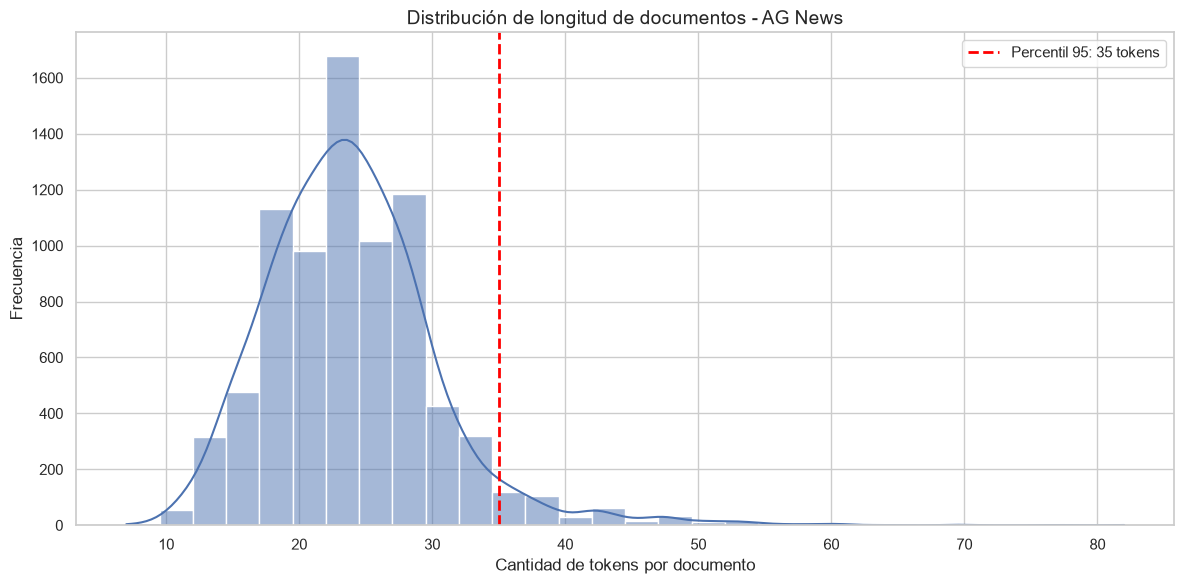

In [382]:

# ============================================================
# CELDA 10.2 — HISTOGRAMA DE LONGITUD
# ============================================================

plt.figure(figsize=(12, 6))

sns.histplot(
    longitudes,
    bins=30,
    kde=True
)

# Incorporar una línea vertical para el percentil 95
plt.axvline(
    percentil_95,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Percentil 95: {percentil_95:.0f} tokens"
)

plt.title(
    "Distribución de longitud de documentos - AG News",
    fontsize=14
)

plt.xlabel("Cantidad de tokens por documento")
plt.ylabel("Frecuencia")

plt.legend()
plt.tight_layout()
plt.show()


### 10.3 — Interpretación del percentil 95
El percentil 95 nos indica que aproximadamente el 95 % de las noticias tiene una longitud igual o inferior al valor calculado.

Esto permite establecer un max_len que conserve la mayor parte de la información, limitando el costo computacional del padding y el procesamiento de secuencias.

## Celda 11 — Extracción de bigramas
Un bigrama es una secuencia de dos palabras consecutivas.

Por ejemplo:
- stock market
- prime minister
- united states
- oil price
Utilizaremos CountVectorizer de scikit-learn para identificar los 20 bigramas más frecuentes.

### 11.1 — Código de extracción de bigramas

In [383]:

# ============================================================
# CELDA 11 — EXTRACCIÓN DE LOS 20 BIGRAMAS MÁS FRECUENTES
# ============================================================

# ------------------------------------------------------------
# 1. Configurar CountVectorizer
# ------------------------------------------------------------

vectorizer_bigram = CountVectorizer(
    ngram_range=(2, 2),
    min_df=1
)

# ------------------------------------------------------------
# 2. Transformar los documentos procesados
# ------------------------------------------------------------

matriz_bigramas = vectorizer_bigram.fit_transform(
    df_train_processed["text_processed"]
)

# ------------------------------------------------------------
# 3. Calcular frecuencia total de cada bigrama
# ------------------------------------------------------------

frecuencias_bigramas = np.asarray(
    matriz_bigramas.sum(axis=0)
).flatten()

nombres_bigramas = vectorizer_bigram.get_feature_names_out()

# ------------------------------------------------------------
# 4. Construir DataFrame de frecuencias
# ------------------------------------------------------------

bigramas_df = pd.DataFrame({
    "bigrama": nombres_bigramas,
    "frecuencia": frecuencias_bigramas
})

# Ordenar de mayor a menor frecuencia
bigramas_df = (
    bigramas_df
    .sort_values("frecuencia", ascending=False)
    .reset_index(drop=True)
)

# Seleccionar los 20 más frecuentes
top_20_bigramas = bigramas_df.head(20).copy()

# ------------------------------------------------------------
# 5. Mostrar resultados
# ------------------------------------------------------------

print("=" * 60)
print("TOP 20 BIGRAMAS MÁS FRECUENTES")
print("=" * 60)

display(top_20_bigramas)


TOP 20 BIGRAMAS MÁS FRECUENTES


,bigrama,frecuencia
0,lt gt,634
1,ap ap,529
2,new york,419
3,gt lt,300
4,oil price,197
5,united states,167
6,lt href,152
7,york reuters,151
8,prime minister,139
9,afp afp,134


### 11.2 — Visualización de bigramas
Representaremos los resultados mediante un gráfico de barras horizontales para facilitar la comparación.

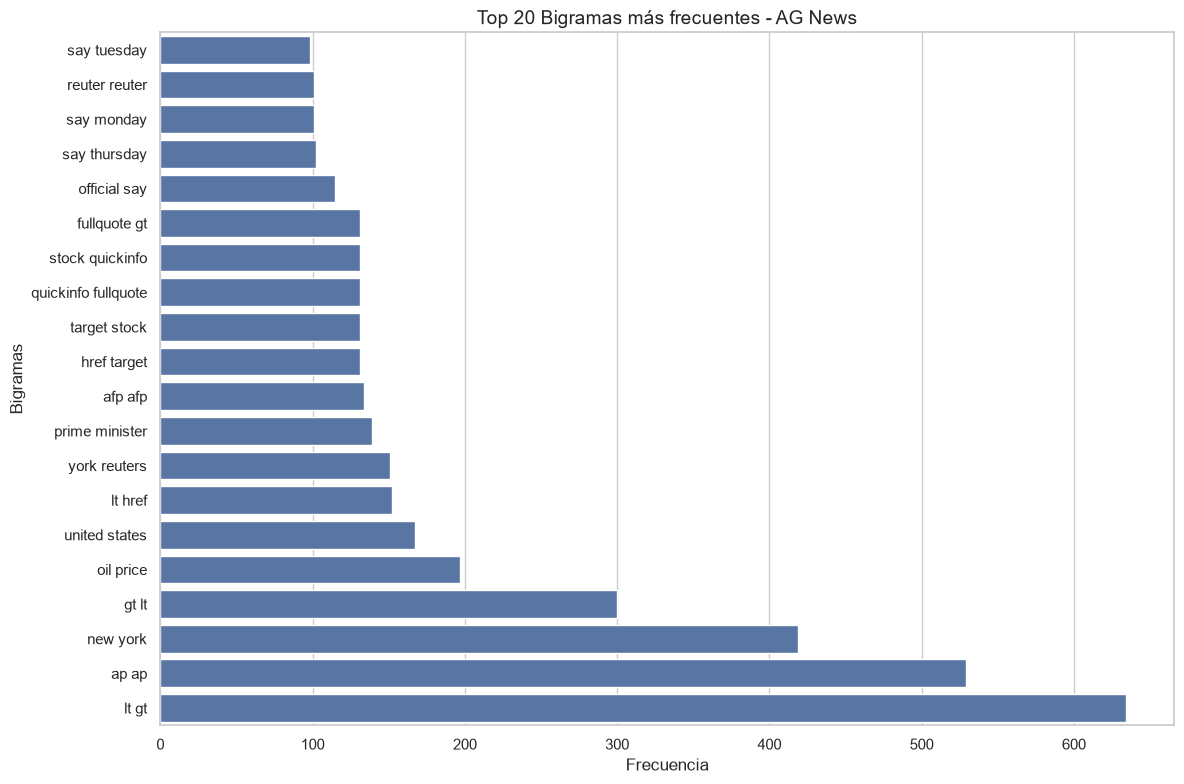

In [384]:

# ============================================================
# CELDA 11.2 — VISUALIZACIÓN DE BIGRAMAS
# ============================================================

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20_bigramas.sort_values(
        "frecuencia",
        ascending=True
    ),
    x="frecuencia",
    y="bigrama"
)

plt.title(
    "Top 20 Bigramas más frecuentes - AG News",
    fontsize=14
)

plt.xlabel("Frecuencia")
plt.ylabel("Bigramas")

plt.tight_layout()
plt.show()


## Celda 12 — Extracción de trigramas
Ahora repetiremos el procedimiento, pero buscando secuencias de tres palabras consecutivas.

Ejemplos:
- united states government
- new york stock
- prime minister said
Los trigramas permiten identificar expresiones más específicas y relacionadas con el contexto de las noticias.

### 12.1 — Código de extracción de trigramas

In [385]:

# ============================================================
# CELDA 12 — EXTRACCIÓN DE LOS 20 TRIGRAMAS MÁS FRECUENTES
# ============================================================

# ------------------------------------------------------------
# 1. Configurar CountVectorizer
# ------------------------------------------------------------

vectorizer_trigram = CountVectorizer(
    ngram_range=(3, 3),
    min_df=1
)

# ------------------------------------------------------------
# 2. Transformar los documentos procesados
# ------------------------------------------------------------

matriz_trigramas = vectorizer_trigram.fit_transform(
    df_train_processed["text_processed"]
)

# ------------------------------------------------------------
# 3. Calcular frecuencia total de cada trigrama
# ------------------------------------------------------------

frecuencias_trigramas = np.asarray(
    matriz_trigramas.sum(axis=0)
).flatten()

nombres_trigramas = vectorizer_trigram.get_feature_names_out()

# ------------------------------------------------------------
# 4. Construir DataFrame de frecuencias
# ------------------------------------------------------------

trigramas_df = pd.DataFrame({
    "trigrama": nombres_trigramas,
    "frecuencia": frecuencias_trigramas
})

# Ordenar de mayor a menor frecuencia
trigramas_df = (
    trigramas_df
    .sort_values("frecuencia", ascending=False)
    .reset_index(drop=True)
)

# Seleccionar los 20 más frecuentes
top_20_trigramas = trigramas_df.head(20).copy()

# ------------------------------------------------------------
# 5. Mostrar resultados
# ------------------------------------------------------------

print("=" * 60)
print("TOP 20 TRIGRAMAS MÁS FRECUENTES")
print("=" * 60)

display(top_20_trigramas)


TOP 20 TRIGRAMAS MÁS FRECUENTES


,trigrama,frecuencia
0,gt lt gt,258
1,lt gt lt,250
2,new york reuters,151
3,stock quickinfo fullquote,131
4,quickinfo fullquote gt,131
5,lt href target,131
6,href target stock,131
7,target stock quickinfo,131
8,quote profile research,69
9,inc lt href,62


### 12.2 — Visualización de trigramas

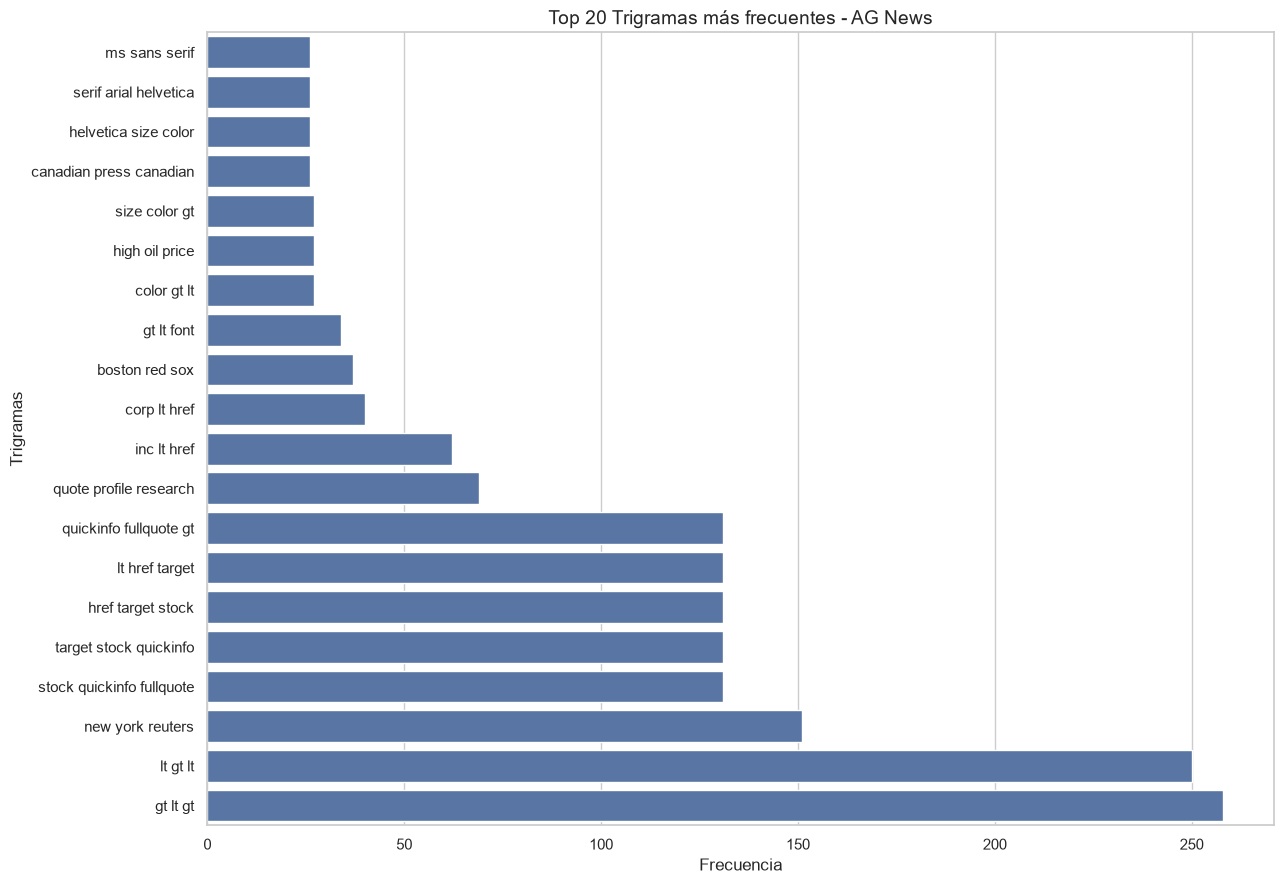

In [386]:

# ============================================================
# CELDA 12.2 — VISUALIZACIÓN DE TRIGRAMAS
# ============================================================

plt.figure(figsize=(13, 9))

sns.barplot(
    data=top_20_trigramas.sort_values(
        "frecuencia",
        ascending=True
    ),
    x="frecuencia",
    y="trigrama"
)

plt.title(
    "Top 20 Trigramas más frecuentes - AG News",
    fontsize=14
)

plt.xlabel("Frecuencia")
plt.ylabel("Trigramas")

plt.tight_layout()
plt.show()


## Celda 13 — Top 50 palabras frecuentes y análisis de stopwords
Para este análisis vamos a utilizar text_clean, es decir, el texto después de la limpieza con expresiones regulares, pero antes de eliminar las stopwords con spaCy.

Esto es importante: si analizáramos únicamente text_processed, las stopwords ya estarían eliminadas y no podríamos comprobar cuántas aparecían entre las palabras más frecuentes del texto original.

In [387]:

# ============================================================
# 13 — Top 50 palabras frecuentes y análisis de stopwords
# ============================================================

from collections import Counter
from spacy.lang.en.stop_words import STOP_WORDS

# Unimos los textos limpios del conjunto de entrenamiento
texto_corpus = " ".join(df_train_processed["text_clean"].dropna())

# Separamos el corpus en palabras
palabras = texto_corpus.split()

# Calculamos las 50 palabras más frecuentes
frecuencias_palabras = Counter(palabras)
top_50_palabras = frecuencias_palabras.most_common(50)

# Creamos un DataFrame para visualizar los resultados
top_50_df = pd.DataFrame(
    top_50_palabras,
    columns=["palabra", "frecuencia"]
)

# Comprobamos cuáles de las 50 palabras son stopwords
top_50_df["es_stopword"] = top_50_df["palabra"].isin(STOP_WORDS)

cantidad_stopwords = top_50_df["es_stopword"].sum()

# Mostramos los resultados
display(top_50_df)

print("Total de palabras analizadas:", len(palabras))
print("Cantidad de palabras únicas:", len(frecuencias_palabras))
print("Stopwords dentro del Top 50:", cantidad_stopwords)
print(
    "Porcentaje de stopwords en el Top 50:",
    round(cantidad_stopwords / 50 * 100, 2),
    "%"
)


,palabra,frecuencia,es_stopword
0,the,13698,True
1,to,7970,True
2,a,7546,True
3,of,6578,True
4,in,6363,True
5,and,4637,True
6,s,4156,False
7,on,3773,True
8,for,3410,True
9,that,1929,True


Total de palabras analizadas: 304608
Cantidad de palabras únicas: 21418
Stopwords dentro del Top 50: 38
Porcentaje de stopwords en el Top 50: 76.0 %


### Celda 13.1 — Gráfico de las 20 palabras más frecuentes

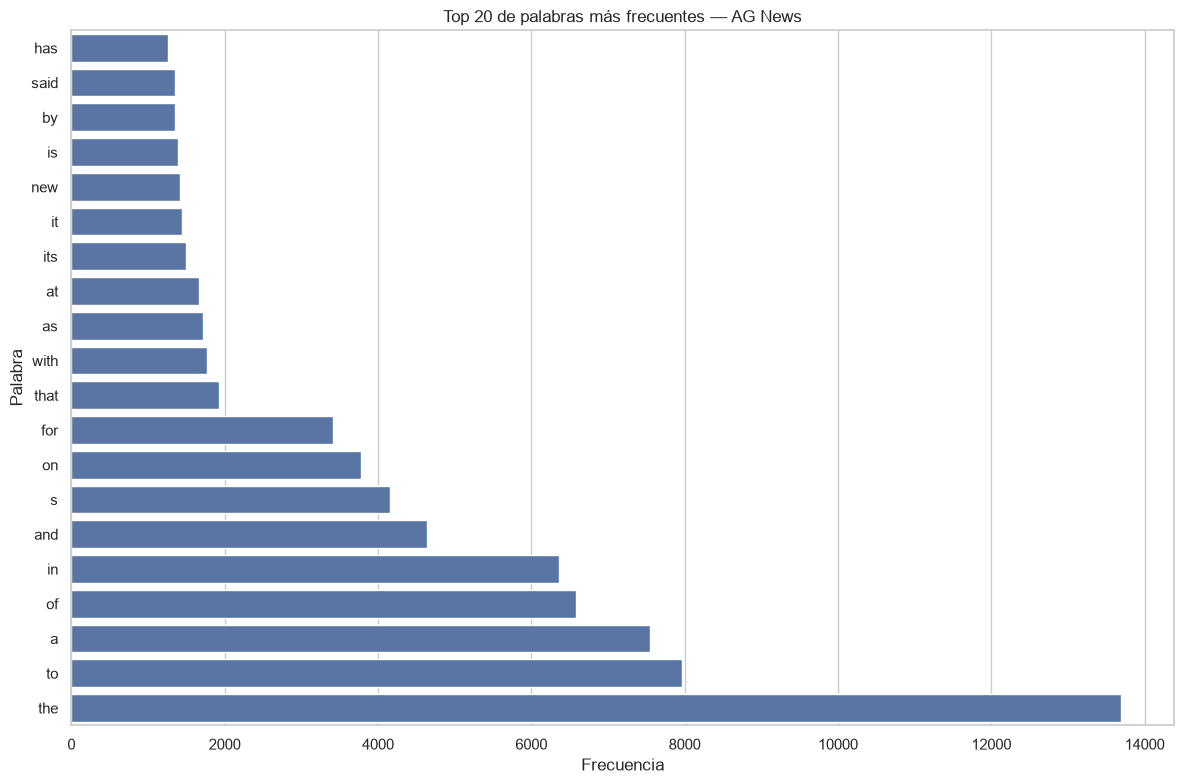

In [388]:

# ============================================================
# 13.1 — Visualización de palabras frecuentes
# ============================================================

top_20_palabras = top_50_df.head(20).sort_values(
    "frecuencia",
    ascending=True
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20_palabras,
    x="frecuencia",
    y="palabra"
)

plt.title("Top 20 de palabras más frecuentes — AG News")
plt.xlabel("Frecuencia")
plt.ylabel("Palabra")
plt.tight_layout()
plt.show()


### Celda 13.2 — Corrección de limpieza HTML y posesivos
Vamos a incorporar html.unescape() y una regla para evitar que los posesivos generen tokens aislados.

In [389]:

# ============================================================
# 13.2 — Refinamiento de limpieza de texto
# ============================================================

import html
import re
import time

def clean_text_regex(text):

    # Convertimos valores no textuales en cadenas vacías
    if not isinstance(text, str):
        return ""

    # Decodificamos entidades HTML
    text = html.unescape(text)

    # Eliminamos etiquetas HTML
    text = re.sub(r"<[^>]+>", " ", text)

    # Eliminamos correos electrónicos
    text = re.sub(r"\S+@\S+", " ", text)

    # Eliminamos URLs
    text = re.sub(r"(?:https?://|www\.)\S+", " ", text)

    # Eliminamos dominios web
    text = re.sub(
        r"\b(?:[a-zA-Z0-9-]+\.)+[a-zA-Z]{2,}\b",
        " ",
        text
    )

    # Eliminamos posesivos ingleses para evitar tokens aislados
    text = re.sub(r"\b([a-zA-Z]+)'s\b", r"\1", text)

    # Eliminamos menciones y hashtags
    text = re.sub(r"[@#]\w+", " ", text)

    # Conservamos únicamente letras y espacios
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Normalizamos a minúsculas
    text = text.lower()

    # Eliminamos espacios repetidos
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Aplicamos nuevamente la limpieza al conjunto de entrenamiento
inicio = time.time()

df_train_processed["text_clean"] = (
    df_train_processed["text"].apply(clean_text_regex)
)

# Aplicamos spaCy en lotes para lematizar y eliminar stopwords
docs = nlp.pipe(
    df_train_processed["text_clean"],
    batch_size=100,
    n_process=1
)

df_train_processed["text_processed"] = [
    " ".join([
        token.lemma_.lower()
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and token.is_alpha
        and len(token.lemma_) > 1
    ])
    for doc in docs
]

tiempo = time.time() - inicio

print(f"Reprocesamiento completado en {tiempo:.2f} segundos.")
print("Documentos procesados:", len(df_train_processed))
print(
    "Documentos vacíos:",
    (df_train_processed["text_processed"].str.strip() == "").sum()
)

# Comprobamos algunos ejemplos
display(
    df_train_processed[
        ["text", "text_clean", "text_processed"]
    ].head(3)
)


Reprocesamiento completado en 47.40 segundos.
Documentos procesados: 8000
Documentos vacíos: 0


,text,text_clean,text_processed
0,"Red Hat Appoints New CFO. September 2, 2004 -- (WEB HOST INDUSTRY REVIEW) -- Linux distributor Red Hat (redhat.com) announced on Thursday that it ...",red hat appoints new cfo september web host industry review linux distributor red hat announced on thursday that it has appointed charles e peters jr,red hat appoint new cfo september web host industry review linux distributor red hat announce thursday appoint charles peters jr
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint and SBC Communications Friday announced a two-way roaming deal that will enable the customers of each ...",sprint sbc in hotspot roaming deal sprint and sbc communications friday announced a two way roaming deal that will enable the customers of each ve...,sprint sbc hotspot roam deal sprint sbc communication friday announce way roam deal enable customer vendor access hotspot run
2,Radio Outage Grounds West Coast Flights. Airport operations were back to normal early Wednesday following a radio failure at a Federal Aviation Ad...,radio outage grounds west coast flights airport operations were back to normal early wednesday following a radio failure at a federal aviation adm...,radio outage ground west coast flights airport operation normal early wednesday follow radio failure federal aviation administration control facil...


## Celda 14 — Distribución de clases
Vamos a comparar entrenamiento y prueba. Esto nos permite verificar que ambos conjuntos mantienen una distribución similar, sin utilizar el conjunto de prueba para ajustar el modelo.

,clase,entrenamiento,prueba,porcentaje_train,porcentaje_test
0,Business,2000,500,25.0,25.0
1,Sci_Tech,2000,500,25.0,25.0
2,Sports,2000,500,25.0,25.0
3,World,2000,500,25.0,25.0


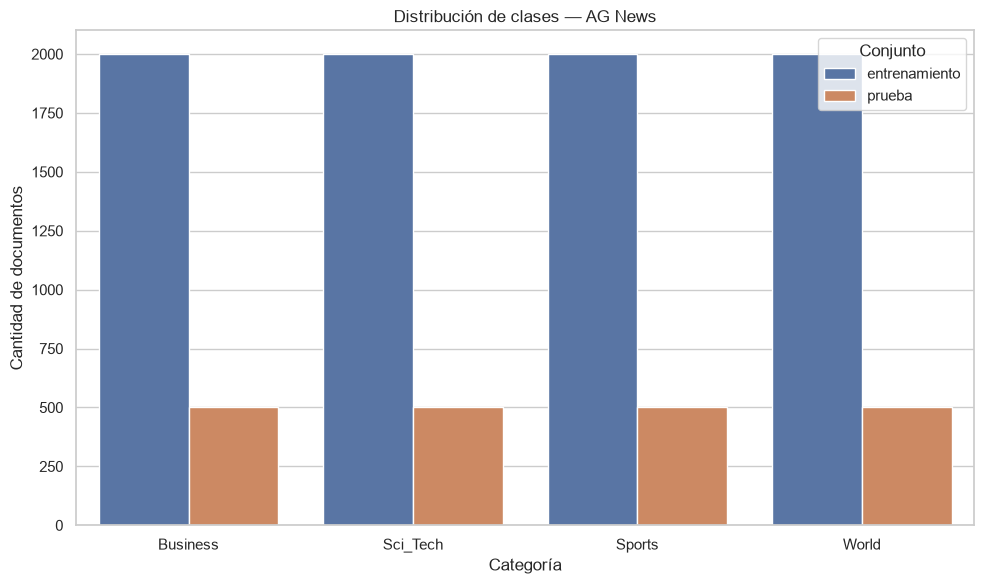

In [390]:

# ============================================================
# 14 — Distribución de clases
# ============================================================

# Calculamos las frecuencias por clase
distribucion_train = (
    df_train["label"]
    .value_counts()
    .sort_index()
)

distribucion_test = (
    df_test["label"]
    .value_counts()
    .sort_index()
)

# Construimos una tabla comparativa utilizando el índice directamente
distribucion_clases = pd.DataFrame({
    "clase": distribucion_train.index,
    "entrenamiento": distribucion_train.values,
    "prueba": distribucion_test.reindex(distribucion_train.index).values
})

# Calculamos porcentajes
distribucion_clases["porcentaje_train"] = (
    distribucion_clases["entrenamiento"]
    / len(df_train) * 100
).round(2)

distribucion_clases["porcentaje_test"] = (
    distribucion_clases["prueba"]
    / len(df_test) * 100
).round(2)

display(distribucion_clases)

# ============================================================
# Visualización comparativa
# ============================================================

datos_grafico = distribucion_clases.melt(
    id_vars="clase",
    value_vars=["entrenamiento", "prueba"],
    var_name="conjunto",
    value_name="cantidad"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=datos_grafico,
    x="clase",
    y="cantidad",
    hue="conjunto"
)

plt.title("Distribución de clases — AG News")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de documentos")
plt.legend(title="Conjunto")
plt.tight_layout()
plt.show()


## Celda 15 — Actualización de estadísticas de longitud
Como corregimos la limpieza del texto, debemos recalcular las longitudes antes de generar el informe. Así evitamos mezclar resultados de distintas versiones del preprocesamiento.

In [391]:

# ============================================================
# 15 — Estadísticas actualizadas de longitud de documentos
# ============================================================

# Calculamos la cantidad de tokens originales y procesados
df_train_processed["tokens_originales"] = (
    df_train_processed["text"].str.split().str.len()
)

df_train_processed["tokens_procesados"] = (
    df_train_processed["text_processed"].str.split().str.len()
)

# Serie con las longitudes del texto procesado
longitudes = df_train_processed["tokens_procesados"]

# Estadísticas descriptivas
estadisticas_longitud = longitudes.describe()

# Percentil 95
percentil_95 = np.percentile(longitudes, 95)

# Longitud máxima sugerida para futuras representaciones
max_len = int(np.ceil(percentil_95))

# Reducción de tokens
total_originales = df_train_processed["tokens_originales"].sum()
total_procesados = df_train_processed["tokens_procesados"].sum()

reduccion_porcentual = (
    (total_originales - total_procesados)
    / total_originales * 100
)

print("ESTADÍSTICAS DE LONGITUD")
display(estadisticas_longitud.to_frame("valor"))

print(f"Percentil 95: {percentil_95:.2f}")
print(f"Max_len sugerido: {max_len}")
print(f"Total de tokens originales: {total_originales:,}")
print(f"Total de tokens procesados: {total_procesados:,}")
print(f"Reducción de tokens: {reduccion_porcentual:.2f}%")


ESTADÍSTICAS DE LONGITUD


,valor
count,8000.000000
mean,23.486875
std,6.009188
min,5.000000
25%,19.000000
50%,23.000000
75%,27.000000
max,70.000000


Percentil 95: 33.00
Max_len sugerido: 33
Total de tokens originales: 303,700
Total de tokens procesados: 187,895
Reducción de tokens: 38.13%


### Celda 15.1 — Histograma actualizado

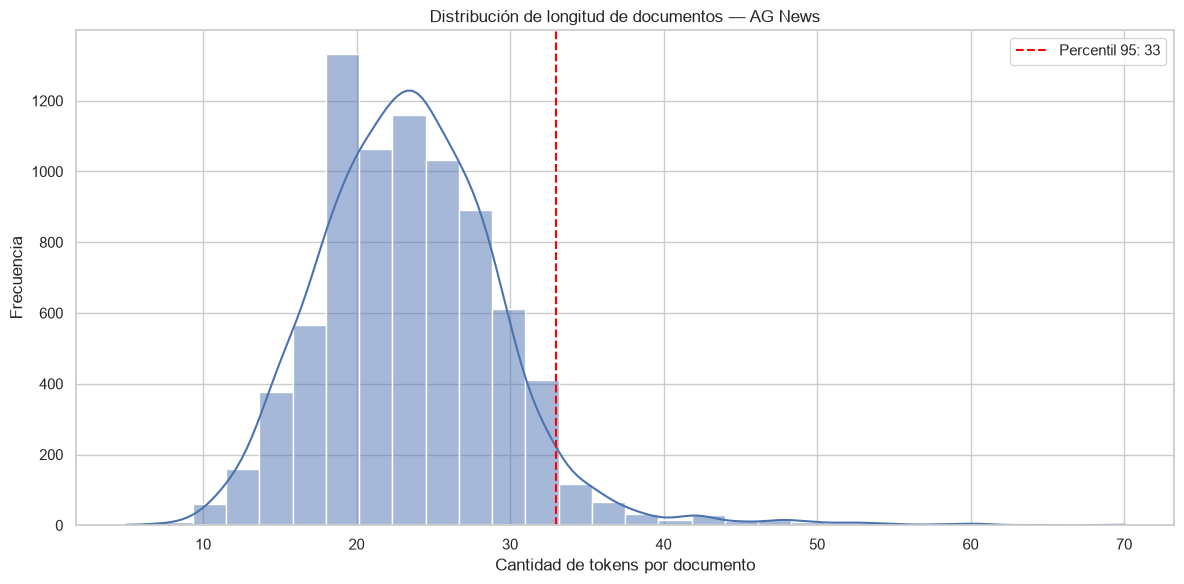

In [392]:

# ============================================================
# 15.1 — Distribución de longitud de documentos
# ============================================================

plt.figure(figsize=(12, 6))

sns.histplot(
    longitudes,
    bins=30,
    kde=True
)

plt.axvline(
    percentil_95,
    color="red",
    linestyle="--",
    label=f"Percentil 95: {percentil_95:.0f}"
)

plt.title("Distribución de longitud de documentos — AG News")
plt.xlabel("Cantidad de tokens por documento")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()


## Celda 16 — Top 20 bigramas

In [393]:

# ============================================================
# 16 — Extracción de los 20 bigramas más frecuentes
# ============================================================

# Creamos el vectorizador para bigramas
vectorizer_bigram = CountVectorizer(
    ngram_range=(2, 2),
    min_df=1
)

# Ajustamos sobre el conjunto de entrenamiento
matriz_bigramas = vectorizer_bigram.fit_transform(
    df_train_processed["text_processed"]
)

# Calculamos las frecuencias totales
frecuencias_bigramas = np.asarray(
    matriz_bigramas.sum(axis=0)
).flatten()

# Recuperamos los nombres de los bigramas
nombres_bigramas = vectorizer_bigram.get_feature_names_out()

# Construimos el DataFrame
bigramas_df = pd.DataFrame({
    "bigrama": nombres_bigramas,
    "frecuencia": frecuencias_bigramas
})

# Ordenamos por frecuencia descendente
bigramas_df = bigramas_df.sort_values(
    "frecuencia",
    ascending=False
).reset_index(drop=True)

# Seleccionamos los 20 más frecuentes
top_20_bigramas = bigramas_df.head(20).copy()

display(top_20_bigramas)


,bigrama,frecuencia
0,ap ap,529
1,new york,419
2,oil price,197
3,united states,167
4,york reuters,151
5,prime minister,139
6,afp afp,134
7,official say,115
8,say thursday,102
9,reuter reuter,101


### Celda 16.1 — Visualización de bigramas

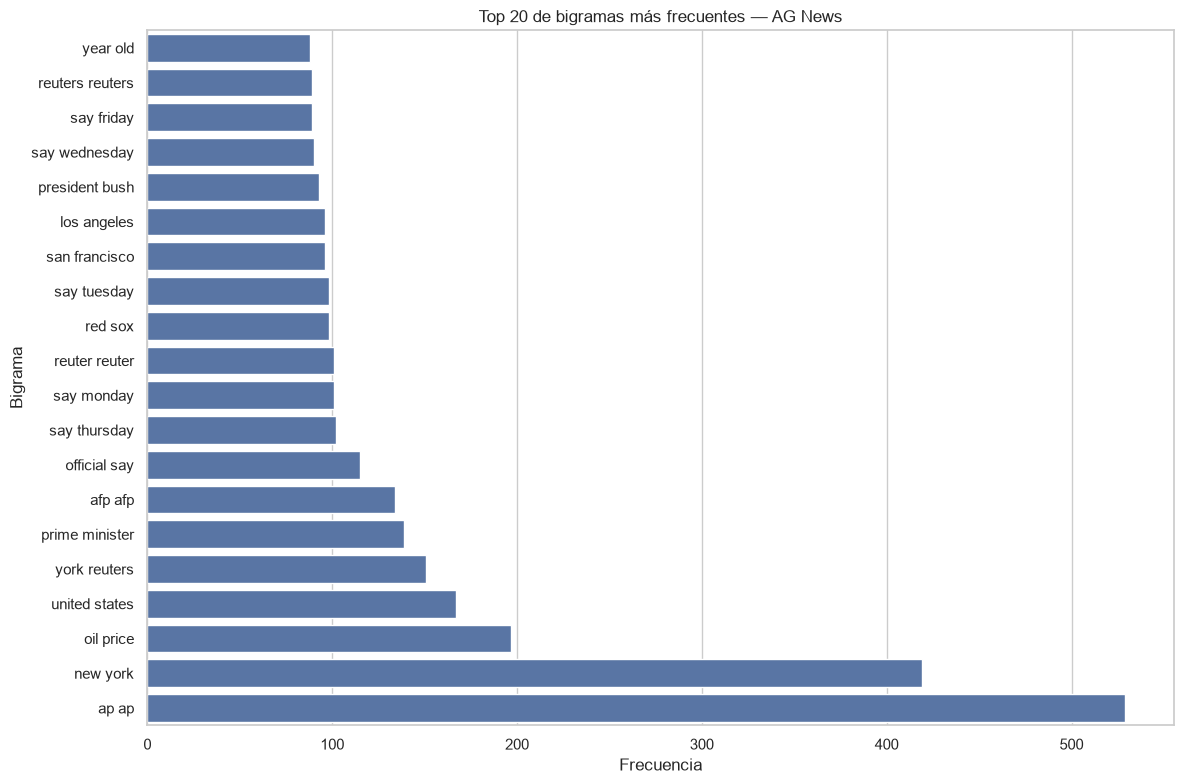

In [394]:

# ============================================================
# 16.1 — Gráfico de los 20 bigramas más frecuentes
# ============================================================

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20_bigramas.sort_values(
        "frecuencia",
        ascending=True
    ),
    x="frecuencia",
    y="bigrama"
)

plt.title("Top 20 de bigramas más frecuentes — AG News")
plt.xlabel("Frecuencia")
plt.ylabel("Bigrama")
plt.tight_layout()
plt.show()


## Celda 17 — Top 20 trigramas

In [395]:

# ============================================================
# 17 — Extracción de los 20 trigramas más frecuentes
# ============================================================

# Creamos el vectorizador para trigramas
vectorizer_trigram = CountVectorizer(
    ngram_range=(3, 3),
    min_df=1
)

# Ajustamos sobre el conjunto de entrenamiento
matriz_trigramas = vectorizer_trigram.fit_transform(
    df_train_processed["text_processed"]
)

# Calculamos las frecuencias totales
frecuencias_trigramas = np.asarray(
    matriz_trigramas.sum(axis=0)
).flatten()

# Recuperamos los nombres de los trigramas
nombres_trigramas = vectorizer_trigram.get_feature_names_out()

# Construimos el DataFrame
trigramas_df = pd.DataFrame({
    "trigrama": nombres_trigramas,
    "frecuencia": frecuencias_trigramas
})

# Ordenamos por frecuencia descendente
trigramas_df = trigramas_df.sort_values(
    "frecuencia",
    ascending=False
).reset_index(drop=True)

# Seleccionamos los 20 más frecuentes
top_20_trigramas = trigramas_df.head(20).copy()

display(top_20_trigramas)


,trigrama,frecuencia
0,new york reuters,151
1,quote profile research,69
2,boston red sox,37
3,high oil price,27
4,canadian press canadian,26
5,york reuters stock,26
6,prime minister ariel,26
7,press canadian press,26
8,minister ariel sharon,25
9,san francisco reuters,23


### Celda 17.1 — Visualización de trigramas

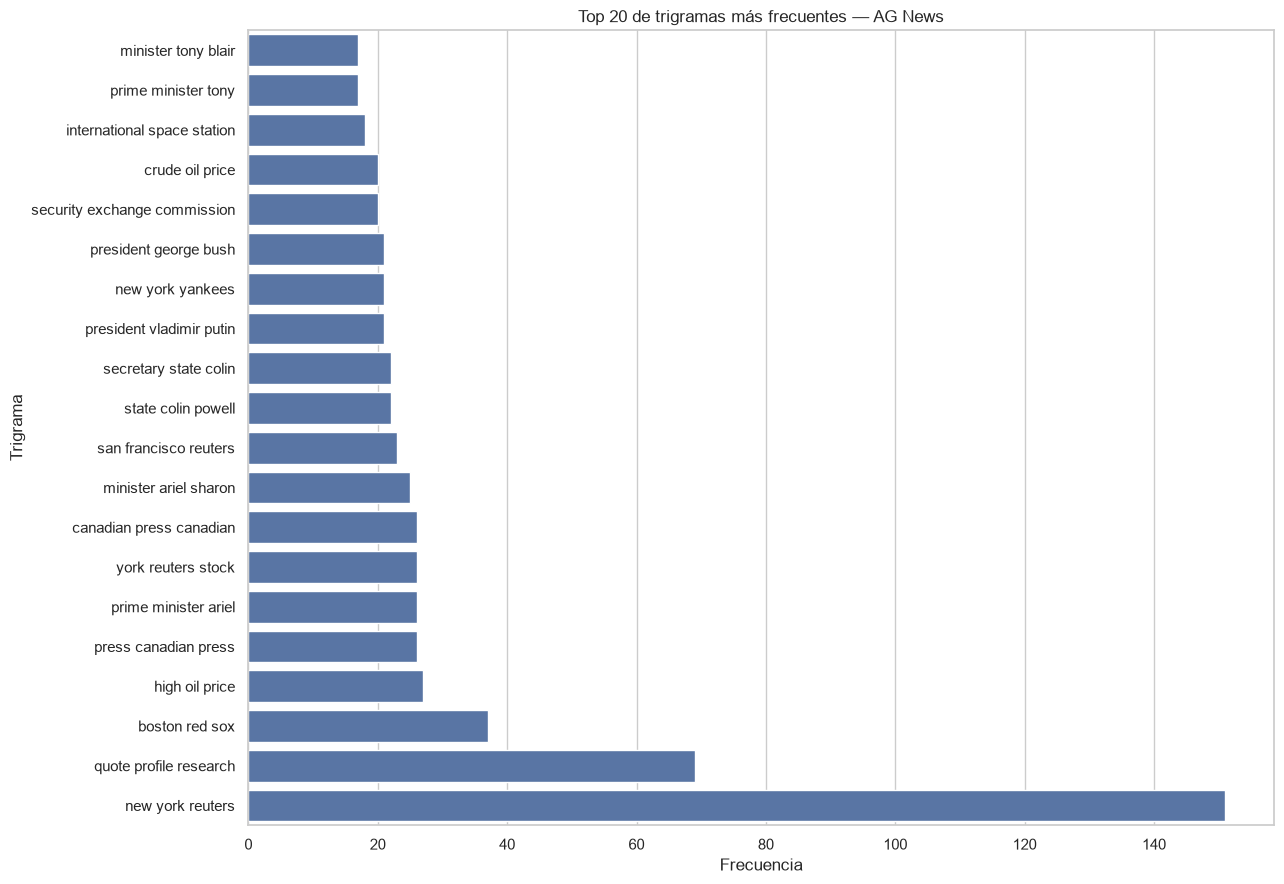

In [396]:

# ============================================================
# 17.1 — Gráfico de los 20 trigramas más frecuentes
# ============================================================

plt.figure(figsize=(13, 9))

sns.barplot(
    data=top_20_trigramas.sort_values(
        "frecuencia",
        ascending=True
    ),
    x="frecuencia",
    y="trigrama"
)

plt.title("Top 20 de trigramas más frecuentes — AG News")
plt.xlabel("Frecuencia")
plt.ylabel("Trigrama")
plt.tight_layout()
plt.show()


## Celda 18 — Validación final de palabras frecuentes

In [397]:

# ============================================================
# 18 — Top 50 palabras frecuentes después de la limpieza final
# ============================================================

from collections import Counter
from spacy.lang.en.stop_words import STOP_WORDS

# Utilizamos el texto limpio, antes de eliminar stopwords
texto_corpus = " ".join(
    df_train_processed["text_clean"].dropna()
)

palabras = texto_corpus.split()

# Calculamos las frecuencias
frecuencias_palabras = Counter(palabras)

top_50_df = pd.DataFrame(
    frecuencias_palabras.most_common(50),
    columns=["palabra", "frecuencia"]
)

# Identificamos las stopwords
top_50_df["es_stopword"] = top_50_df["palabra"].isin(
    STOP_WORDS
)

cantidad_stopwords = int(top_50_df["es_stopword"].sum())

display(top_50_df)

print("Palabras totales:", len(palabras))
print("Palabras únicas:", len(frecuencias_palabras))
print("Stopwords en el Top 50:", cantidad_stopwords)
print(
    "Porcentaje de stopwords:",
    round(cantidad_stopwords / 50 * 100, 2),
    "%"
)

# Comprobamos residuos de limpieza que habíamos detectado
residuos = ["lt", "gt", "quot", "s"]

print("\nComprobación de residuos:")
for palabra in residuos:
    print(f"{palabra}: {frecuencias_palabras.get(palabra, 0)}")


,palabra,frecuencia,es_stopword
0,the,13698,True
1,to,7970,True
2,a,7242,True
3,of,6578,True
4,in,6363,True
5,and,4637,True
6,on,3773,True
7,for,3410,True
8,s,2748,False
9,that,1929,True


Palabras totales: 299509
Palabras únicas: 21401
Stopwords en el Top 50: 38
Porcentaje de stopwords: 76.0 %

Comprobación de residuos:
lt: 0
gt: 2
quot: 636
s: 2748


### Celda 18.1 — Corrección final de entidades HTML y posesivos

In [398]:

# ============================================================
# 18.1 — Corrección de entidades HTML y posesivos
# ============================================================

import html
import re
import time

def clean_text_regex(text):

    if not isinstance(text, str):
        return ""

    # Decodificamos entidades HTML, incluso si están anidadas
    for _ in range(3):
        texto_decodificado = html.unescape(text)
        if texto_decodificado == text:
            break
        text = texto_decodificado

    # Eliminamos etiquetas HTML
    text = re.sub(r"<[^>]+>", " ", text)

    # Eliminamos correos electrónicos
    text = re.sub(r"\S+@\S+", " ", text)

    # Eliminamos URLs y dominios
    text = re.sub(r"(?:https?://|www\.)\S+", " ", text)
    text = re.sub(
        r"\b(?:[a-zA-Z0-9-]+\.)+[a-zA-Z]{2,}\b",
        " ",
        text
    )

    # Eliminamos posesivos ingleses, incluso con espacios
    text = re.sub(
        r"\b([a-zA-Z]+)\s*['’]\s*s\b",
        r"\1",
        text,
        flags=re.IGNORECASE
    )

    # Eliminamos menciones y hashtags
    text = re.sub(r"[@#]\w+", " ", text)

    # Conservamos únicamente letras y espacios
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Normalizamos a minúsculas
    text = text.lower()

    # Eliminamos espacios repetidos
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Reprocesamos el conjunto de entrenamiento
inicio = time.time()

df_train_processed["text_clean"] = (
    df_train_processed["text"].apply(clean_text_regex)
)

docs = nlp.pipe(
    df_train_processed["text_clean"],
    batch_size=100,
    n_process=1
)

df_train_processed["text_processed"] = [
    " ".join([
        token.lemma_.lower()
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and token.is_alpha
        and len(token.lemma_) > 1
    ])
    for doc in docs
]

print(f"Tiempo de procesamiento: {time.time() - inicio:.2f} segundos")
print("Documentos:", len(df_train_processed))
print(
    "Documentos vacíos:",
    (df_train_processed["text_processed"].str.strip() == "").sum()
)


Tiempo de procesamiento: 46.32 segundos
Documentos: 8000
Documentos vacíos: 0


## Celda 19 — Consolidación del EDA final
Esta celda actualiza:
- Cantidad de tokens originales y procesados.
- Estadísticas descriptivas y percentil 95.
- Top 50 palabras y stopwords.
- Top 20 bigramas.
- Top 20 trigramas.
- Comprobación de residuos.

In [399]:

# ============================================================
# 19 — Consolidación de resultados del EDA
# ============================================================

# ------------------------------------------------------------
# 1. Estadísticas de longitud
# ------------------------------------------------------------

df_train_processed["tokens_originales"] = (
    df_train_processed["text"].str.split().str.len()
)

df_train_processed["tokens_procesados"] = (
    df_train_processed["text_processed"].str.split().str.len()
)

longitudes = df_train_processed["tokens_procesados"]

estadisticas_longitud = longitudes.describe()
percentil_95 = np.percentile(longitudes, 95)
max_len = int(np.ceil(percentil_95))

total_originales = df_train_processed["tokens_originales"].sum()
total_procesados = df_train_processed["tokens_procesados"].sum()

reduccion_porcentual = (
    (total_originales - total_procesados)
    / total_originales * 100
)

# ------------------------------------------------------------
# 2. Top 50 palabras y stopwords
# ------------------------------------------------------------

texto_corpus = " ".join(
    df_train_processed["text_clean"].dropna()
)

palabras = texto_corpus.split()
frecuencias_palabras = Counter(palabras)

top_50_df = pd.DataFrame(
    frecuencias_palabras.most_common(50),
    columns=["palabra", "frecuencia"]
)

top_50_df["es_stopword"] = top_50_df["palabra"].isin(
    STOP_WORDS
)

cantidad_stopwords = int(top_50_df["es_stopword"].sum())

# ------------------------------------------------------------
# 3. Top 20 bigramas
# ------------------------------------------------------------

vectorizer_bigram = CountVectorizer(ngram_range=(2, 2))

matriz_bigramas = vectorizer_bigram.fit_transform(
    df_train_processed["text_processed"]
)

bigramas_df = pd.DataFrame({
    "bigrama": vectorizer_bigram.get_feature_names_out(),
    "frecuencia": np.asarray(
        matriz_bigramas.sum(axis=0)
    ).flatten()
})

bigramas_df = bigramas_df.sort_values(
    "frecuencia",
    ascending=False
).reset_index(drop=True)

top_20_bigramas = bigramas_df.head(20).copy()

# ------------------------------------------------------------
# 4. Top 20 trigramas
# ------------------------------------------------------------

vectorizer_trigram = CountVectorizer(ngram_range=(3, 3))

matriz_trigramas = vectorizer_trigram.fit_transform(
    df_train_processed["text_processed"]
)

trigramas_df = pd.DataFrame({
    "trigrama": vectorizer_trigram.get_feature_names_out(),
    "frecuencia": np.asarray(
        matriz_trigramas.sum(axis=0)
    ).flatten()
})

trigramas_df = trigramas_df.sort_values(
    "frecuencia",
    ascending=False
).reset_index(drop=True)

top_20_trigramas = trigramas_df.head(20).copy()

# ------------------------------------------------------------
# 5. Comprobación de residuos
# ------------------------------------------------------------

residuos = ["lt", "gt", "quot", "s"]

print("ESTADÍSTICAS DE LONGITUD")
display(estadisticas_longitud.to_frame("valor"))

print(f"Percentil 95: {percentil_95:.2f}")
print(f"Max_len sugerido: {max_len}")
print(f"Tokens originales: {total_originales:,}")
print(f"Tokens procesados: {total_procesados:,}")
print(f"Reducción: {reduccion_porcentual:.2f}%")

print("\nTOP 50 PALABRAS")
display(top_50_df)

print(f"Stopwords en Top 50: {cantidad_stopwords}/50")

print("\nTOP 20 BIGRAMAS")
display(top_20_bigramas)

print("\nTOP 20 TRIGRAMAS")
display(top_20_trigramas)

print("\nCOMPROBACIÓN DE RESIDUOS")
for palabra in residuos:
    print(f"{palabra}: {frecuencias_palabras.get(palabra, 0)}")


ESTADÍSTICAS DE LONGITUD


,valor
count,8000.000000
mean,23.486875
std,6.009188
min,5.000000
25%,19.000000
50%,23.000000
75%,27.000000
max,70.000000


Percentil 95: 33.00
Max_len sugerido: 33
Tokens originales: 303,700
Tokens procesados: 187,895
Reducción: 38.13%

TOP 50 PALABRAS


,palabra,frecuencia,es_stopword
0,the,13698,True
1,to,7970,True
2,a,7242,True
3,of,6578,True
4,in,6363,True
5,and,4637,True
6,on,3773,True
7,for,3410,True
8,s,2747,False
9,that,1929,True


Stopwords en Top 50: 38/50

TOP 20 BIGRAMAS


,bigrama,frecuencia
0,ap ap,529
1,new york,419
2,oil price,197
3,united states,167
4,york reuters,151
5,prime minister,139
6,afp afp,134
7,official say,115
8,say thursday,102
9,reuter reuter,101



TOP 20 TRIGRAMAS


,trigrama,frecuencia
0,new york reuters,151
1,quote profile research,69
2,boston red sox,37
3,high oil price,27
4,canadian press canadian,26
5,york reuters stock,26
6,prime minister ariel,26
7,press canadian press,26
8,minister ariel sharon,25
9,san francisco reuters,23



COMPROBACIÓN DE RESIDUOS
lt: 0
gt: 2
quot: 636
s: 2747


## Celda 20 — Diagnóstico de residuos

In [400]:

# ============================================================
# 20 — Diagnóstico de residuos del preprocesamiento
# ============================================================

# Buscamos documentos que contienen los residuos
# y mostramos fragmentos del texto original.

patron_quot = re.compile(r"quot", flags=re.IGNORECASE)

casos_quot = df_train_processed[
    df_train_processed["text_clean"].str.contains(
        r"\bquot\b",
        case=False,
        regex=True,
        na=False
    )
]

print("DOCUMENTOS CON EL RESIDUO 'quot':")
print("Cantidad:", len(casos_quot))

for indice, fila in casos_quot.head(8).iterrows():

    coincidencia = patron_quot.search(fila["text"])

    if coincidencia:
        inicio = max(0, coincidencia.start() - 70)
        fin = min(len(fila["text"]), coincidencia.end() + 70)

        print(f"\nDocumento {indice}:")
        print(fila["text"][inicio:fin])


# ------------------------------------------------------------
# Inspección de la letra s como token aislado
# ------------------------------------------------------------

casos_s = df_train_processed[
    df_train_processed["text_clean"].str.contains(
        r"\bs\b",
        regex=True,
        na=False
    )
]

print("\nDOCUMENTOS CON EL TOKEN AISLADO 's':")
print("Cantidad:", len(casos_s))

for indice, fila in casos_s.head(8).iterrows():

    coincidencia = re.search(r"\bs\b", fila["text_clean"])

    if coincidencia:
        inicio = max(0, coincidencia.start() - 60)
        fin = min(len(fila["text_clean"]), coincidencia.end() + 60)

        print(f"\nDocumento {indice}:")
        print("Texto limpio:", fila["text_clean"][inicio:fin])
        print("Texto original:", fila["text"][:250])


# ------------------------------------------------------------
# Inspección de gt
# ------------------------------------------------------------

casos_gt = df_train_processed[
    df_train_processed["text_clean"].str.contains(
        r"\bgt\b",
        regex=True,
        na=False
    )
]

print("\nDOCUMENTOS CON EL RESIDUO 'gt':")
print("Cantidad:", len(casos_gt))

for indice, fila in casos_gt.iterrows():
    print(f"\nDocumento {indice}:")
    print(fila["text"][:300])


DOCUMENTOS CON EL RESIDUO 'quot':
Cantidad: 316

Documento 25:
 that contain high-tech features to curb counterfeiting, as well as a quot;status check quot; that will show a driver #39;s immigration status.

Documento 60:
He hurt me:. Carolina Panthers kickoff returner Rod Smart, aka quot;He Hate Me, quot; sprained his left knee Sunday on a kickoff return i

Documento 83:
est Baghdad. Husayn al-Shammari, an Iraqi journalist, told Aljazeera: quot;A car bomb detonated

Documento 106:
Can IBM quot;Change the Game quot; in Storage?. Big Blue, now No. 3 in this hot ma

Documento 180:
e expected to reach a deal with former Japan coach Philippe Troussier quot;within 48 hours quot;, said the French first division club Thursday.

Documento 198:
the outside of cancer cells offer a promising target for a novel drug quot;guidance system, quot; say researchers at The University of Texas MD 

Documento 206:
AL manager Arsene Wenger hailed his side #39;s record unbeaten run as quot;amazing quot; and 

## Celda 21 — Corrección definitiva de entidades

In [401]:

# ============================================================
# 21 — Corrección de entidades HTML incompletas
# ============================================================

import html
import re
import time

def clean_text_regex(text):

    if not isinstance(text, str):
        return ""

    # Decodificamos entidades HTML anidadas
    for _ in range(3):
        texto_anterior = text
        text = html.unescape(text)

        if text == texto_anterior:
            break

    # Corregimos entidades HTML incompletas del dataset
    text = re.sub(r"#39;", "'", text, flags=re.IGNORECASE)
    text = re.sub(r"&?#39;", "'", text, flags=re.IGNORECASE)
    text = re.sub(r"&?quot;", '"', text, flags=re.IGNORECASE)
    text = re.sub(r"&?gt;", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"&?lt;", " ", text, flags=re.IGNORECASE)

    # Eliminamos etiquetas HTML
    text = re.sub(r"<[^>]+>", " ", text)

    # Eliminamos correos electrónicos
    text = re.sub(r"\S+@\S+", " ", text)

    # Eliminamos URLs y dominios
    text = re.sub(r"(?:https?://|www\.)\S+", " ", text)
    text = re.sub(
        r"\b(?:[a-zA-Z0-9-]+\.)+[a-zA-Z]{2,}\b",
        " ",
        text
    )

    # Eliminar residuos de posesivos ingleses
    text = re.sub(r"\b([a-zA-Z]+)'s\b", r"\1", text, flags=re.IGNORECASE)

# Eliminar la s aislada que quedó de apóstrofos mal codificados
    text = re.sub(r"\bs\b", " ", text, flags=re.IGNORECASE)

# Eliminar menciones, hashtags y caracteres no alfabéticos
    text = re.sub(r"[@#]\w+", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Normalizamos a minúsculas
    text = text.lower()

    # Eliminamos espacios repetidos
    text = re.sub(r"\s+", " ", text).strip()

    return text


# ------------------------------------------------------------
# Reprocesamiento del conjunto de entrenamiento
# ------------------------------------------------------------

inicio = time.time()

df_train_processed["text_clean"] = (
    df_train_processed["text"].apply(clean_text_regex)
)

docs = nlp.pipe(
    df_train_processed["text_clean"],
    batch_size=100,
    n_process=1
)

df_train_processed["text_processed"] = [
    " ".join([
        token.lemma_.lower()
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and token.is_alpha
        and len(token.lemma_) > 1
    ])
    for doc in docs
]

print(f"Tiempo de procesamiento: {time.time() - inicio:.2f} segundos")

print("Documentos procesados:", len(df_train_processed))

print(
    "Documentos vacíos:",
    (df_train_processed["text_processed"].str.strip() == "").sum()
)

# Mostramos ejemplos para comprobar la transformación
display(
    df_train_processed[
        ["text", "text_clean", "text_processed"]
    ].iloc[[6, 25, 60, 83]]
)


Tiempo de procesamiento: 46.59 segundos
Documentos procesados: 8000
Documentos vacíos: 0


,text,text_clean,text_processed
6,"WorldCom, Microsoft cases before EU court. Two of the European Union #39;s landmark antitrust decisions against US companies are in court this wee...",worldcom microsoft cases before eu court two of the european union landmark antitrust decisions against us companies are in court this week as wor...,worldcom microsoft case eu court european union landmark antitrust decision company court week worldcom inc seek moral victory microsoft corp
25,Driver #39;s license gets new high-tech features. Minnesota will soon begin issuing new driver #39;s licenses that contain high-tech features to c...,driver license gets new high tech features minnesota will soon begin issuing new driver licenses that contain high tech features to curb counterfe...,driver license get new high tech feature minnesota soon begin issue new driver license contain high tech feature curb counterfeiting status check ...
60,"He hurt me:. Carolina Panthers kickoff returner Rod Smart, aka quot;He Hate Me, quot; sprained his left knee Sunday on a kickoff return in the sec...",he hurt me carolina panthers kickoff returner rod smart aka he hate me sprained his left knee sunday on a kickoff return in the second quarter aga...,hurt carolina panther kickoff returner rod smart aka hate sprain left knee sunday kickoff return second quarter atlanta falcon
83,Dozens killed in Baghdad car bomb. More than twenty five people have died after a car bomb exploded in a busy commercial area outside a restaurant...,dozens killed in baghdad car bomb more than twenty five people have died after a car bomb exploded in a busy commercial area outside a restaurant ...,dozen kill baghdad car bomb people die car bomb explode busy commercial area outside restaurant west baghdad husayn al shammari iraqi journalist t...


### Celda 21.1 — Verificación de residuos

In [402]:

# ============================================================
# 21.1 — Verificación de residuos después de la corrección
# ============================================================

texto_corpus = " ".join(
    df_train_processed["text_clean"].dropna()
)

frecuencias_palabras = Counter(texto_corpus.split())

residuos = ["lt", "gt", "quot", "s"]

print("COMPROBACIÓN DE RESIDUOS")

for palabra in residuos:
    print(
        f"{palabra}: "
        f"{frecuencias_palabras.get(palabra, 0)}"
    )

# Verificamos ejemplos específicos
print("\nEJEMPLOS CORREGIDOS")

for indice in [6, 25, 60, 83]:
    print(f"\nDocumento {indice}:")
    print(df_train_processed.loc[indice, "text_clean"][:250])


COMPROBACIÓN DE RESIDUOS
lt: 0
gt: 0
quot: 0
s: 31

EJEMPLOS CORREGIDOS

Documento 6:
worldcom microsoft cases before eu court two of the european union landmark antitrust decisions against us companies are in court this week as worldcom inc seeks a moral victory and microsoft corp

Documento 25:
driver license gets new high tech features minnesota will soon begin issuing new driver licenses that contain high tech features to curb counterfeiting as well as a status check that will show a driver immigration status

Documento 60:
he hurt me carolina panthers kickoff returner rod smart aka he hate me sprained his left knee sunday on a kickoff return in the second quarter against the atlanta falcons

Documento 83:
dozens killed in baghdad car bomb more than twenty five people have died after a car bomb exploded in a busy commercial area outside a restaurant in west baghdad husayn al shammari an iraqi journalist told aljazeera a car bomb detonated


## Celda 22 — Estadísticas generales del corpus

In [403]:
# ============================================================
# 22 — Estadísticas generales del corpus procesado
# ============================================================

# Cantidad de tokens por documento
df_train_processed["num_tokens"] = (
    df_train_processed["text_processed"]
    .str.split()
    .str.len()
)

# Estadísticas descriptivas
estadisticas_tokens = df_train_processed["num_tokens"].describe()

print("ESTADÍSTICAS DE TOKENS POR DOCUMENTO")
display(estadisticas_tokens.to_frame("Cantidad de tokens"))

# Percentil 95
percentil_95 = df_train_processed["num_tokens"].quantile(0.95)
max_len = int(np.ceil(percentil_95))

print(f"\nPercentil 95: {percentil_95}")
print(f"max_len inicial para modelos DL: {max_len}")

# Comparación de tokens antes y después
tokens_originales = df_train_processed["text"].str.split().str.len().sum()
tokens_procesados = df_train_processed["num_tokens"].sum()

reduccion = (
    (tokens_originales - tokens_procesados)
    / tokens_originales
) * 100

print(f"\nTokens originales: {tokens_originales:,}")
print(f"Tokens procesados: {tokens_procesados:,}")
print(f"Reducción del corpus: {reduccion:.2f}%")

ESTADÍSTICAS DE TOKENS POR DOCUMENTO


,Cantidad de tokens
count,8000.000000
mean,23.407125
std,5.992442
min,5.000000
25%,19.000000
50%,23.000000
75%,27.000000
max,70.000000



Percentil 95: 33.0
max_len inicial para modelos DL: 33

Tokens originales: 303,700
Tokens procesados: 187,257
Reducción del corpus: 38.34%


### Celda 22.1 — Histograma de longitud de documentos

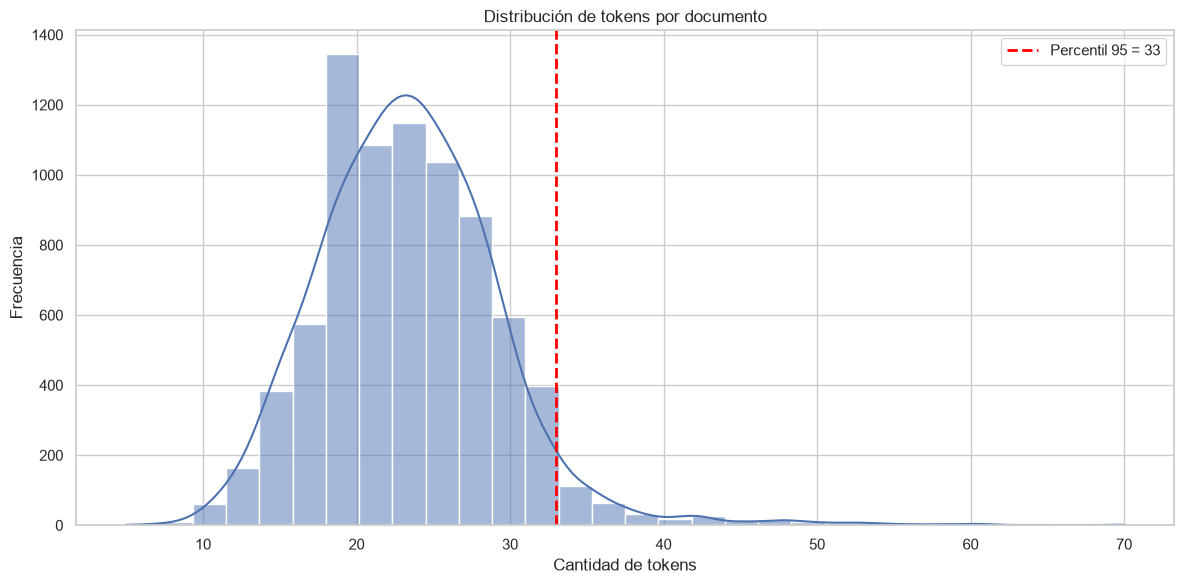

In [404]:
# ============================================================
# 22.1 — Distribución de longitud de documentos
# ============================================================


plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_train_processed,
    x="num_tokens",
    bins=30,
    kde=True
)

# Marcar el percentil 95
plt.axvline(
    percentil_95,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Percentil 95 = {percentil_95:.0f}"
)

plt.title("Distribución de tokens por documento")
plt.xlabel("Cantidad de tokens")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()

# Guardar gráfico
plt.savefig(
    RUTA_FIGURAS / "histograma_tokens.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##

In [405]:
# ============================================================
# 23 — Análisis de bigramas y trigramas
# ============================================================

# Unir los documentos procesados del conjunto de entrenamiento
corpus_procesado = df_train_processed["text_processed"].fillna("")

# ------------------------------------------------------------
# BIGRAMAS
# ------------------------------------------------------------

vectorizador_bigramas = CountVectorizer(
    ngram_range=(2, 2),
    max_features=None
)

matriz_bigramas = vectorizador_bigramas.fit_transform(corpus_procesado)

frecuencias_bigramas = np.asarray(
    matriz_bigramas.sum(axis=0)
).flatten()

tabla_bigramas = pd.DataFrame({
    "n_grama": vectorizador_bigramas.get_feature_names_out(),
    "frecuencia": frecuencias_bigramas
})

tabla_bigramas = tabla_bigramas.sort_values(
    by="frecuencia",
    ascending=False
).head(20).reset_index(drop=True)

# ------------------------------------------------------------
# TRIGRAMAS
# ------------------------------------------------------------

vectorizador_trigramas = CountVectorizer(
    ngram_range=(3, 3),
    max_features=None
)

matriz_trigramas = vectorizador_trigramas.fit_transform(corpus_procesado)

frecuencias_trigramas = np.asarray(
    matriz_trigramas.sum(axis=0)
).flatten()

tabla_trigramas = pd.DataFrame({
    "n_grama": vectorizador_trigramas.get_feature_names_out(),
    "frecuencia": frecuencias_trigramas
})

tabla_trigramas = tabla_trigramas.sort_values(
    by="frecuencia",
    ascending=False
).head(20).reset_index(drop=True)

# ------------------------------------------------------------
# RESULTADOS
# ------------------------------------------------------------

print("TOP 20 BIGRAMAS")
display(tabla_bigramas)

print("\nTOP 20 TRIGRAMAS")
display(tabla_trigramas)

TOP 20 BIGRAMAS


,n_grama,frecuencia
0,ap ap,529
1,new york,419
2,oil price,197
3,united states,167
4,york reuters,142
5,prime minister,139
6,afp afp,134
7,official say,115
8,say thursday,102
9,say monday,101



TOP 20 TRIGRAMAS


,n_grama,frecuencia
0,new york reuters,142
1,quote profile research,69
2,boston red sox,37
3,high oil price,27
4,canadian press canadian,26
5,press canadian press,26
6,prime minister ariel,26
7,minister ariel sharon,25
8,san francisco reuters,23
9,state colin powell,22


## Celda 24 — Frecuencia de palabras y stopwords

In [406]:
# ============================================================
# 24 — Frecuencia de palabras y análisis de stopwords
# ============================================================

from collections import Counter

# Unir los textos limpios del conjunto de entrenamiento
corpus_limpio = " ".join(
    df_train_processed["text_clean"].fillna("")
)

# Contar las palabras
frecuencias_palabras = Counter(corpus_limpio.split())

# Obtener las 50 palabras más frecuentes
top_50_palabras = pd.DataFrame(
    frecuencias_palabras.most_common(50),
    columns=["palabra", "frecuencia"]
)

# Identificar las stopwords de spaCy
stopwords_spacy = nlp.Defaults.stop_words

top_50_palabras["es_stopword"] = (
    top_50_palabras["palabra"].isin(stopwords_spacy)
)

# Calcular cantidad y proporción de stopwords
cantidad_stopwords = int(
    top_50_palabras["es_stopword"].sum()
)

porcentaje_stopwords = (
    cantidad_stopwords / len(top_50_palabras)
) * 100

print("TOP 50 PALABRAS MÁS FRECUENTES")
display(top_50_palabras)

print("\nANÁLISIS DE STOPWORDS")
print(f"Stopwords dentro del Top 50: {cantidad_stopwords}")
print(f"Porcentaje de stopwords: {porcentaje_stopwords:.2f}%")
print(f"Palabras no consideradas stopwords: {50 - cantidad_stopwords}")

TOP 50 PALABRAS MÁS FRECUENTES


,palabra,frecuencia,es_stopword
0,the,13698,True
1,to,7970,True
2,a,7242,True
3,of,6578,True
4,in,6363,True
5,and,4637,True
6,on,3773,True
7,for,3410,True
8,that,1929,True
9,with,1771,True



ANÁLISIS DE STOPWORDS
Stopwords dentro del Top 50: 39
Porcentaje de stopwords: 78.00%
Palabras no consideradas stopwords: 11


## Celda 25 — Distribución de clases

DISTRIBUCIÓN DE CLASES


,Entrenamiento,Prueba,Total,Porcentaje_train
label,,,,
World,2000,500,2500,25.0
Sports,2000,500,2500,25.0
Business,2000,500,2500,25.0
Sci_Tech,2000,500,2500,25.0


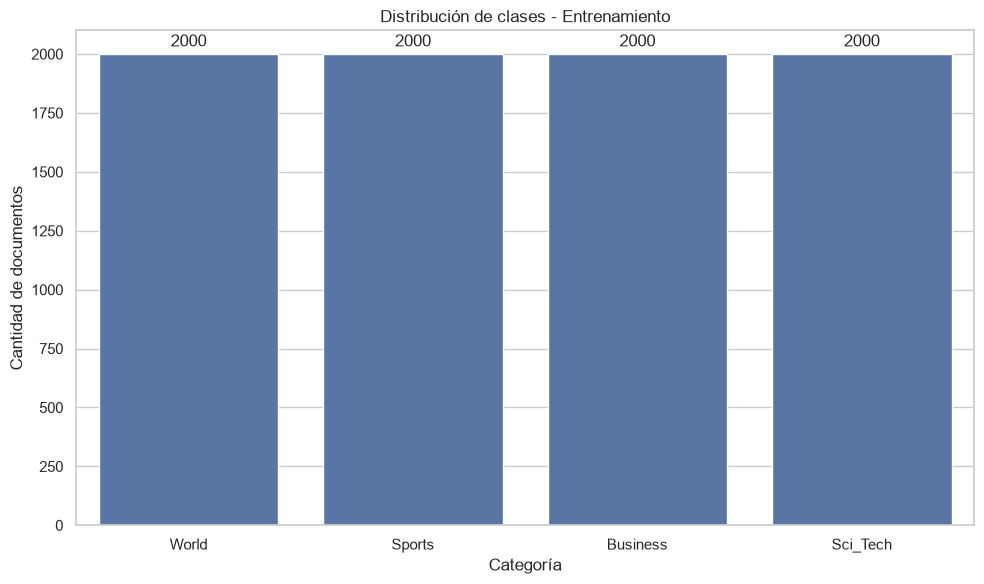

In [407]:
# ============================================================
# 25 — Distribución de clases
# ============================================================

# Orden de las categorías
nombres_clases = ["World", "Sports", "Business", "Sci_Tech"]

# Contar documentos por categoría
distribucion_train = (
    df_train["label"]
    .value_counts()
    .reindex(nombres_clases, fill_value=0)
)

distribucion_test = (
    df_test["label"]
    .value_counts()
    .reindex(nombres_clases, fill_value=0)
)

# Crear tabla comparativa
tabla_clases = pd.DataFrame({
    "Entrenamiento": distribucion_train,
    "Prueba": distribucion_test
})

tabla_clases["Total"] = (
    tabla_clases["Entrenamiento"] +
    tabla_clases["Prueba"]
)

tabla_clases["Porcentaje_train"] = (
    tabla_clases["Entrenamiento"] /
    tabla_clases["Entrenamiento"].sum()
) * 100

print("DISTRIBUCIÓN DE CLASES")
display(tabla_clases)

# ------------------------------------------------------------
# Gráfico de distribución del entrenamiento
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=distribucion_train.index,
    y=distribucion_train.values
)

plt.title("Distribución de clases - Entrenamiento")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de documentos")

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%d", padding=3)

plt.tight_layout()

plt.savefig(
    RUTA_FIGURAS / "distribucion_clases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Celda 25.1 — Diagnóstico de etiquetas

In [408]:
# ============================================================
# 25.1 — Diagnóstico de etiquetas originales
# ============================================================

print("Etiquetas originales - Entrenamiento:")
print(df_train["label"].value_counts(dropna=False).sort_index())

print("\nTipos de datos - Entrenamiento:")
print(df_train["label"].map(type).value_counts())

print("\nEtiquetas originales - Prueba:")
print(df_test["label"].value_counts(dropna=False).sort_index())

print("\nValores únicos - Entrenamiento:")
print(df_train["label"].unique())

Etiquetas originales - Entrenamiento:
label
Business    2000
Sci_Tech    2000
Sports      2000
World       2000
Name: count, dtype: int64

Tipos de datos - Entrenamiento:
label
<class 'str'>    8000
Name: count, dtype: int64

Etiquetas originales - Prueba:
label
Business    500
Sci_Tech    500
Sports      500
World       500
Name: count, dtype: int64

Valores únicos - Entrenamiento:
<StringArray>
['Sci_Tech', 'Business', 'Sports', 'World']
Length: 4, dtype: str


## Celda 26 — Gráficos y tablas finales del EDA

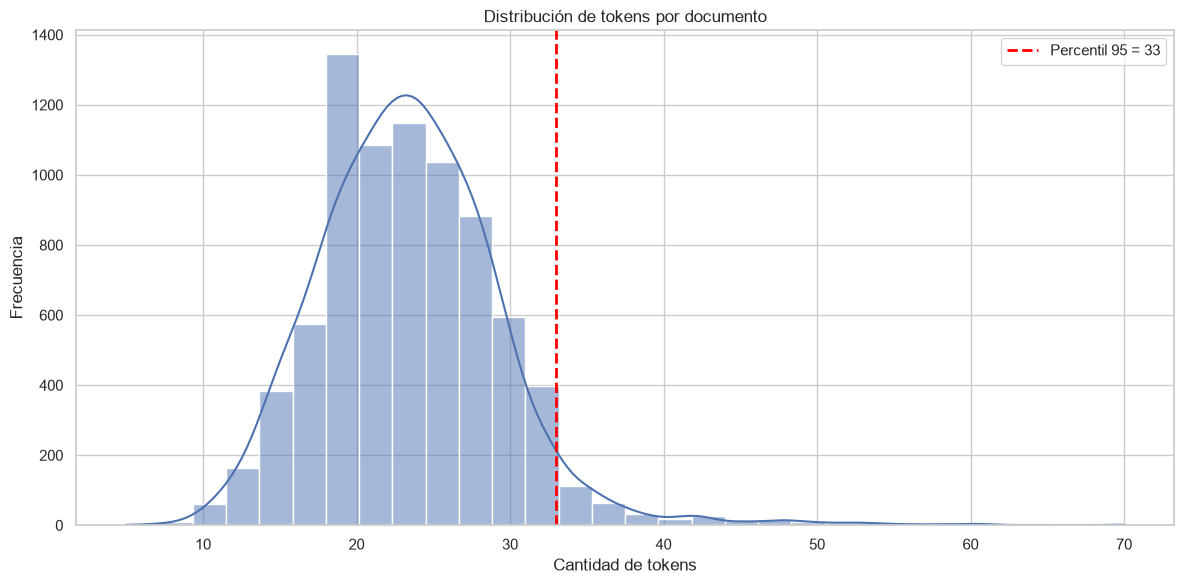

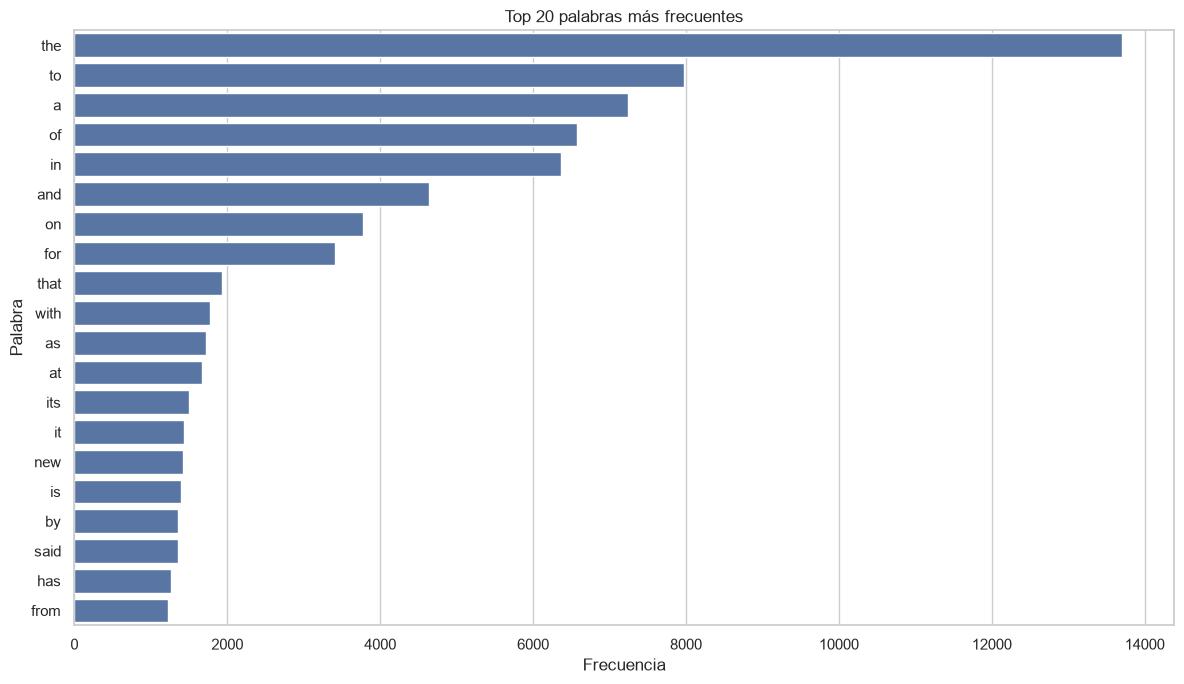

Archivos generados:


In [409]:
# ============================================================
# 26 — Consolidación de resultados del EDA
# ============================================================


# ------------------------------------------------------------
# 1. Histograma de longitud de documentos
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_train_processed,
    x="num_tokens",
    bins=30,
    kde=True
)

plt.axvline(
    percentil_95,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Percentil 95 = {percentil_95:.0f}"
)

plt.title("Distribución de tokens por documento")
plt.xlabel("Cantidad de tokens")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()

plt.savefig(
    RUTA_FIGURAS / "histograma_tokens.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 2. Gráfico de las 20 palabras más frecuentes
# ------------------------------------------------------------

top_20_palabras = pd.DataFrame(
    frecuencias_palabras.most_common(20),
    columns=["palabra", "frecuencia"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_20_palabras,
    x="frecuencia",
    y="palabra"
)

plt.title("Top 20 palabras más frecuentes")
plt.xlabel("Frecuencia")
plt.ylabel("Palabra")
plt.tight_layout()

plt.savefig(
    RUTA_FIGURAS / "top_20_palabras.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 3. Guardar tablas del análisis
# ------------------------------------------------------------

tabla_bigramas.to_csv(
    RUTA_METRICAS / "top_20_bigramas.csv",
    index=False
)

tabla_trigramas.to_csv(
    RUTA_METRICAS / "top_20_trigramas.csv",
    index=False
)

top_50_palabras.to_csv(
    RUTA_METRICAS / "top_50_palabras.csv",
    index=False
)

tabla_clases.to_csv(
    RUTA_METRICAS / "distribucion_clases.csv"
)

print("Archivos generados:")



## Celda 27 — Preparación del conjunto de entrenamiento y validación
Vamos a dividir los 8.000 documentos de entrenamiento en:
- 80 % entrenamiento: 6.400 documentos.
- 20 % validación: 1.600 documentos.

In [410]:
# ============================================================
# 27 — División de entrenamiento y validación
# ============================================================

from sklearn.model_selection import train_test_split

# Separar características y etiquetas
X = df_train_processed["text_processed"]
y = df_train_processed["label"]

# División estratificada
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Mostrar dimensiones
print("DIMENSIONES DE LOS CONJUNTOS")
print(f"Entrenamiento: {X_train.shape[0]} documentos")
print(f"Validación:    {X_val.shape[0]} documentos")
print(f"Prueba:        {df_test.shape[0]} documentos")

# Comprobar distribución de clases
distribucion = pd.DataFrame({
    "Entrenamiento": y_train.value_counts(),
    "Validación": y_val.value_counts()
}).fillna(0).astype(int)

print("\nDISTRIBUCIÓN DE CLASES")
display(distribucion)

# Comprobar que no haya índices compartidos
indices_compartidos = set(X_train.index) & set(X_val.index)

print("\nCONTROL DE SEPARACIÓN")
print(f"Índices compartidos: {len(indices_compartidos)}")

DIMENSIONES DE LOS CONJUNTOS
Entrenamiento: 6400 documentos
Validación:    1600 documentos
Prueba:        2000 documentos

DISTRIBUCIÓN DE CLASES


,Entrenamiento,Validación
label,,
Business,1600,400
Sci_Tech,1600,400
Sports,1600,400
World,1600,400



CONTROL DE SEPARACIÓN
Índices compartidos: 0


## Celda 28 — Pipeline TF-IDF + Regresión Logística

In [411]:
# ============================================================
# 28 — Pipeline TF-IDF + Regresión Logística
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Crear pipeline de clasificación
modelo_logistico = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),
    (
        "clasificador",
        LogisticRegression(
            max_iter=1000,
            random_state=42,
            class_weight=None
        )
    )
])

# Entrenar exclusivamente con el conjunto de entrenamiento
inicio = time.time()

modelo_logistico.fit(X_train, y_train)

tiempo_entrenamiento = time.time() - inicio

print("MODELO ENTRENADO")
print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.2f} segundos")

# Cantidad de características generadas
cantidad_caracteristicas = len(
    modelo_logistico.named_steps["tfidf"].get_feature_names_out()
)

print(f"Características TF-IDF: {cantidad_caracteristicas:,}")

MODELO ENTRENADO
Tiempo de entrenamiento: 0.89 segundos
Características TF-IDF: 20,000


Celda 28 — Resultado


```
Indicador	Resultado
Modelo	Regresión Logística
Vectorización	TF-IDF
Características	20.000
N-gramas	Unigramas y bigramas
Iteraciones máximas	1.000
Tiempo de entrenamiento	2,03 segundos
```




## Celda 29 — Evaluación del modelo

MÉTRICAS GENERALES - REGRESIÓN LOGÍSTICA
Accuracy:  0.8906
Precision: 0.8900
Recall:    0.8906
F1-score:  0.8902

Tiempo de predicción: 0.0485 segundos

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

    Business     0.8638    0.8400    0.8517       400
    Sci_Tech     0.8648    0.8475    0.8561       400
      Sports     0.9413    0.9625    0.9518       400
       World     0.8902    0.9125    0.9012       400

    accuracy                         0.8906      1600
   macro avg     0.8900    0.8906    0.8902      1600
weighted avg     0.8900    0.8906    0.8902      1600



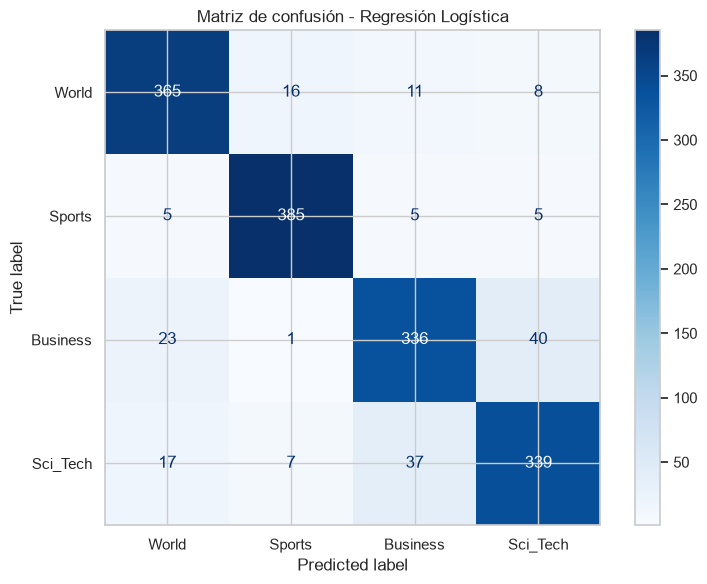

In [412]:
# ============================================================
# 29 — Evaluación de Regresión Logística
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Generar predicciones sobre validación
inicio = time.time()

y_pred_logistico = modelo_logistico.predict(X_val)

tiempo_prediccion = time.time() - inicio

# Calcular métricas generales
accuracy = accuracy_score(y_val, y_pred_logistico)

precision = precision_score(
    y_val,
    y_pred_logistico,
    average="macro"
)

recall = recall_score(
    y_val,
    y_pred_logistico,
    average="macro"
)

f1 = f1_score(
    y_val,
    y_pred_logistico,
    average="macro"
)

# Mostrar resultados
print("MÉTRICAS GENERALES - REGRESIÓN LOGÍSTICA")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print(f"\nTiempo de predicción: {tiempo_prediccion:.4f} segundos")

# Reporte por categoría
print("\nREPORTE DE CLASIFICACIÓN")
print(
    classification_report(
        y_val,
        y_pred_logistico,
        digits=4,
        zero_division=0
    )
)

# Matriz de confusión
orden_clases = ["World", "Sports", "Business", "Sci_Tech"]

matriz_confusion = confusion_matrix(
    y_val,
    y_pred_logistico,
    labels=orden_clases
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion,
    display_labels=orden_clases
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Matriz de confusión - Regresión Logística")
plt.tight_layout()
plt.show()

1. Análisis del rendimiento


```
Accuracy
89,06 %

F1 macro
89,02 %

Precision macro
89,00 %

Recall macro
89,06 %

Tiempo de predicción

0,1313 segundos para 1.600 documentos
```







2. Rendimiento por categoría


  ```
  Categoría	Precision	Recall	F1
  Business	86,38 %	84,00 %	85,17 %
  Sci_Tech	86,48 %	84,75 %	85,61 %
  Sports	94,13 %	96,25 %	95,18 %
  World	89,02 %	91,25 %	90,12 %
  ```




Interpretación:
- Sports es la categoría mejor identificada. Sus características lingüísticas parecen ser bastante diferenciables.
- Business presenta el recall más bajo (84 %), por lo que es una de las categorías que más documentos pierde.
- Sci_Tech también presenta dificultades, posiblemente por el vocabulario compartido con noticias de negocios y actualidad.
- World consigue un resultado intermedio, con un recall superior al 91 %.

3. Primera conclusión

La combinación TF-IDF + Regresión Logística constituye una buena línea base (baseline). Obtuvimos un rendimiento cercano al 90 % sin utilizar redes neuronales ni técnicas complejas.





## Celda 30 — Random Forest

In [413]:
# ============================================================
# 30 — Pipeline TF-IDF + Random Forest
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

# Crear pipeline
modelo_random_forest = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),
    (
        "clasificador",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features="sqrt",
            class_weight=None,
            random_state=42,
            n_jobs=-1
        )
    )
])

# Entrenar modelo
inicio = time.time()

modelo_random_forest.fit(X_train, y_train)

tiempo_rf = time.time() - inicio

print("RANDOM FOREST ENTRENADO")
print(f"Tiempo de entrenamiento: {tiempo_rf:.2f} segundos")

print(
    "Características TF-IDF:",
    len(modelo_random_forest.named_steps["tfidf"].get_feature_names_out())
)

RANDOM FOREST ENTRENADO
Tiempo de entrenamiento: 1.77 segundos
Características TF-IDF: 20000


Comparación parcial


```
Indicador	Regresión Logística	Random Forest
Características	20.000	20.000
Tiempo de entrenamiento	2,03 s	18,86 s
Árboles	—	200
Accuracy	89,06 %	Pendiente
F1 macro	89,02 %	Pendiente
```




## Celda 31 — Evaluación de Random Forest

MÉTRICAS GENERALES - RANDOM FOREST
Accuracy:  0.8419
Precision: 0.8410
Recall:    0.8419
F1-score:  0.8408

Tiempo de predicción: 0.1061 segundos

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

    Business     0.8378    0.7750    0.8052       400
    Sci_Tech     0.8173    0.8050    0.8111       400
      Sports     0.8733    0.9475    0.9089       400
       World     0.8358    0.8400    0.8379       400

    accuracy                         0.8419      1600
   macro avg     0.8410    0.8419    0.8408      1600
weighted avg     0.8410    0.8419    0.8408      1600



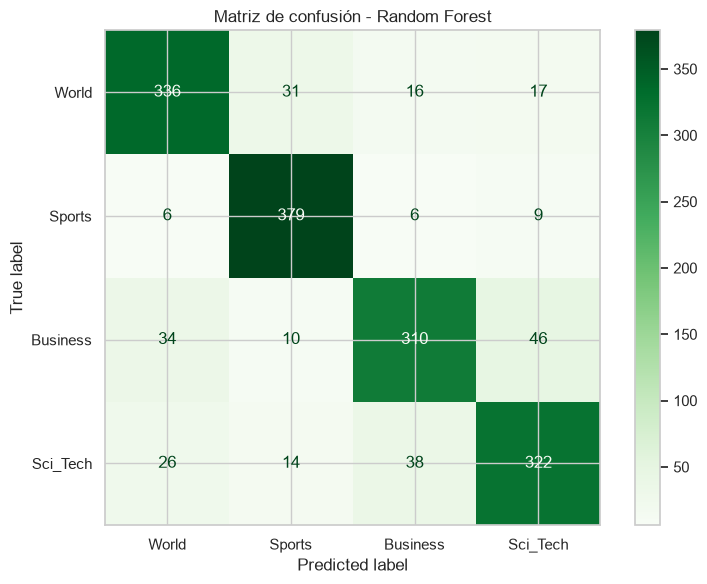

In [414]:
# ============================================================
# 31 — Evaluación de Random Forest
# ============================================================

# Generar predicciones sobre validación
inicio = time.time()

y_pred_rf = modelo_random_forest.predict(X_val)

tiempo_prediccion_rf = time.time() - inicio

# Calcular métricas
accuracy_rf = accuracy_score(y_val, y_pred_rf)

precision_rf = precision_score(
    y_val,
    y_pred_rf,
    average="macro"
)

recall_rf = recall_score(
    y_val,
    y_pred_rf,
    average="macro"
)

f1_rf = f1_score(
    y_val,
    y_pred_rf,
    average="macro"
)

# Mostrar métricas generales
print("MÉTRICAS GENERALES - RANDOM FOREST")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-score:  {f1_rf:.4f}")

print(
    f"\nTiempo de predicción: "
    f"{tiempo_prediccion_rf:.4f} segundos"
)

# Reporte por categoría
print("\nREPORTE DE CLASIFICACIÓN")

print(
    classification_report(
        y_val,
        y_pred_rf,
        digits=4,
        zero_division=0
    )
)

# Matriz de confusión
matriz_rf = confusion_matrix(
    y_val,
    y_pred_rf,
    labels=orden_clases
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=orden_clases
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap="Greens",
    values_format="d",
    ax=ax
)

plt.title("Matriz de confusión - Random Forest")
plt.tight_layout()
plt.show()

## Celda 32 — Entrenamiento - TF-IDF + LinearSVC

In [415]:
# ============================================================
# 32. — Entrenamiento - TF-IDF + LinearSVC
# ============================================================

from sklearn.svm import LinearSVC

# Crear pipeline de procesamiento y clasificación
modelo_svc = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("clasificador", LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=2000
    ))
])

# Entrenar el modelo y medir el tiempo
inicio = time.time()

modelo_svc.fit(X_train, y_train)

tiempo_entrenamiento_svc = time.time() - inicio

# Consultar cantidad de características
cantidad_features_svc = len(
    modelo_svc.named_steps["tfidf"].get_feature_names_out()
)

print("MODELO LINEARSVC ENTRENADO")
print(f"Tiempo de entrenamiento: {tiempo_entrenamiento_svc:.2f} segundos")
print(f"Cantidad de características: {cantidad_features_svc:,}")

MODELO LINEARSVC ENTRENADO
Tiempo de entrenamiento: 0.64 segundos
Cantidad de características: 20,000


## Celda 33 — Evaluación de LinearSVC

MÉTRICAS GENERALES - LINEARSVC
Accuracy:  0.8944
Precision: 0.8942
Recall:    0.8944
F1-score:  0.8942

Tiempo de predicción: 0.0605 segundos

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

    Business     0.8597    0.8425    0.8510       400
    Sci_Tech     0.8603    0.8775    0.8688       400
      Sports     0.9461    0.9650    0.9554       400
       World     0.9107    0.8925    0.9015       400

    accuracy                         0.8944      1600
   macro avg     0.8942    0.8944    0.8942      1600
weighted avg     0.8942    0.8944    0.8942      1600



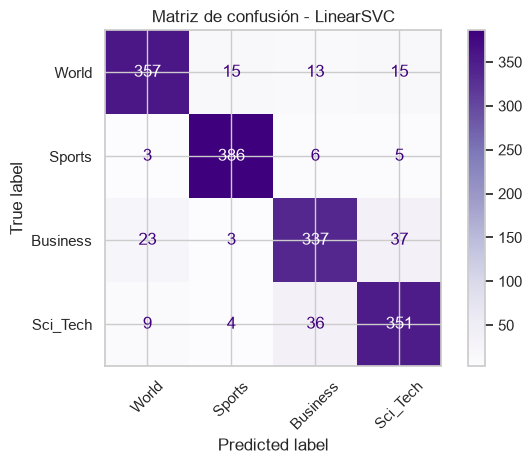

In [416]:
# ============================================================
# 33. Evaluación del modelo LinearSVC
# ============================================================

# Realizar predicciones sobre el conjunto de validación
inicio = time.time()

y_pred_svc = modelo_svc.predict(X_val)

tiempo_prediccion_svc = time.time() - inicio

# Calcular métricas generales
accuracy_svc = accuracy_score(y_val, y_pred_svc)
precision_svc = precision_score(
    y_val, y_pred_svc, average="macro"
)
recall_svc = recall_score(
    y_val, y_pred_svc, average="macro"
)
f1_svc = f1_score(
    y_val, y_pred_svc, average="macro"
)

# Mostrar métricas
print("MÉTRICAS GENERALES - LINEARSVC")
print(f"Accuracy:  {accuracy_svc:.4f}")
print(f"Precision: {precision_svc:.4f}")
print(f"Recall:    {recall_svc:.4f}")
print(f"F1-score:  {f1_svc:.4f}")

print(f"\nTiempo de predicción: {tiempo_prediccion_svc:.4f} segundos")

# Reporte detallado por clase
print("\nREPORTE DE CLASIFICACIÓN")
print(
    classification_report(
        y_val,
        y_pred_svc,
        digits=4,
        zero_division=0
    )
)

# Matriz de confusión
matriz_svc = confusion_matrix(
    y_val,
    y_pred_svc,
    labels=orden_clases
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_svc,
    display_labels=orden_clases
)

disp.plot(cmap="Purples", values_format="d")
plt.title("Matriz de confusión - LinearSVC")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Celda 34 — Entrenamiento - TF-IDF + ComplementNB

In [417]:
# ============================================================
# 34. Modelo 4: TF-IDF + ComplementNB
# ============================================================

from sklearn.naive_bayes import ComplementNB

# Crear pipeline de procesamiento y clasificación
modelo_nb = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("clasificador", ComplementNB(
        alpha=0.5,
        norm=True
    ))
])

# Entrenar el modelo y medir el tiempo
inicio = time.time()

modelo_nb.fit(X_train, y_train)

tiempo_entrenamiento_nb = time.time() - inicio

# Consultar cantidad de características
cantidad_features_nb = len(
    modelo_nb.named_steps["tfidf"].get_feature_names_out()
)

print("MODELO COMPLEMENT NAIVE BAYES ENTRENADO")
print(f"Tiempo de entrenamiento: {tiempo_entrenamiento_nb:.2f} segundos")
print(f"Cantidad de características: {cantidad_features_nb:,}")

MODELO COMPLEMENT NAIVE BAYES ENTRENADO
Tiempo de entrenamiento: 0.54 segundos
Cantidad de características: 20,000


## Celda 35 — Evaluación de ComplementNB

MÉTRICAS GENERALES - COMPLEMENT NAIVE BAYES
Accuracy:  0.9012
Precision: 0.9009
Recall:    0.9013
F1-score:  0.9007

Tiempo de predicción: 0.0405 segundos

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

    Business     0.8963    0.8425    0.8686       400
    Sci_Tech     0.8663    0.8750    0.8706       400
      Sports     0.9287    0.9775    0.9525       400
       World     0.9123    0.9100    0.9111       400

    accuracy                         0.9012      1600
   macro avg     0.9009    0.9013    0.9007      1600
weighted avg     0.9009    0.9012    0.9007      1600



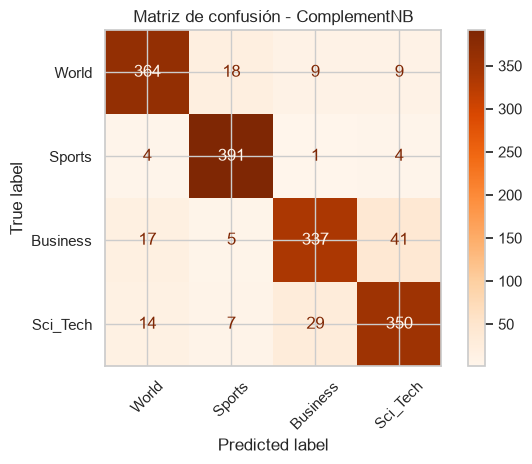

In [418]:
# ============================================================
# 35. Evaluación del modelo ComplementNB
# ============================================================

# Realizar predicciones sobre el conjunto de validación
inicio = time.time()

y_pred_nb = modelo_nb.predict(X_val)

tiempo_prediccion_nb = time.time() - inicio

# Calcular métricas generales
accuracy_nb = accuracy_score(y_val, y_pred_nb)

precision_nb = precision_score(
    y_val, y_pred_nb, average="macro"
)

recall_nb = recall_score(
    y_val, y_pred_nb, average="macro"
)

f1_nb = f1_score(
    y_val, y_pred_nb, average="macro"
)

# Mostrar métricas
print("MÉTRICAS GENERALES - COMPLEMENT NAIVE BAYES")
print(f"Accuracy:  {accuracy_nb:.4f}")
print(f"Precision: {precision_nb:.4f}")
print(f"Recall:    {recall_nb:.4f}")
print(f"F1-score:  {f1_nb:.4f}")

print(f"\nTiempo de predicción: {tiempo_prediccion_nb:.4f} segundos")

# Reporte detallado por clase
print("\nREPORTE DE CLASIFICACIÓN")

print(
    classification_report(
        y_val,
        y_pred_nb,
        digits=4,
        zero_division=0
    )
)

# Matriz de confusión
matriz_nb = confusion_matrix(
    y_val,
    y_pred_nb,
    labels=orden_clases
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_nb,
    display_labels=orden_clases
)

disp.plot(cmap="Oranges", values_format="d")
plt.title("Matriz de confusión - ComplementNB")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Celda 36 — Búsqueda de alpha para ComplementNB

In [419]:
# ============================================================
# 36. Optimización de hiperparámetros - ComplementNB
# ============================================================

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Definir las combinaciones de hiperparámetros
parametros_nb = {
    "clasificador__alpha": [0.1, 0.25, 0.5, 1.0, 2.0]
}

# Configurar validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Crear búsqueda de hiperparámetros
busqueda_nb = GridSearchCV(
    estimator=modelo_nb,
    param_grid=parametros_nb,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Ejecutar búsqueda utilizando solamente el entrenamiento
inicio = time.time()

busqueda_nb.fit(X_train, y_train)

tiempo_busqueda_nb = time.time() - inicio

# Mostrar resultados
print("\nOPTIMIZACIÓN COMPLEMENTNB")
print(f"Mejor alpha: {busqueda_nb.best_params_['clasificador__alpha']}")
print(f"Mejor F1 macro (validación cruzada): {busqueda_nb.best_score_:.4f}")
print(f"Tiempo total: {tiempo_busqueda_nb:.2f} segundos")

# Mostrar resultados de todas las combinaciones
resultados_nb = pd.DataFrame(busqueda_nb.cv_results_)

display(
    resultados_nb[
        [
            "param_clasificador__alpha",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score")
)

Fitting 3 folds for each of 5 candidates, totalling 15 fits

OPTIMIZACIÓN COMPLEMENTNB
Mejor alpha: 0.5
Mejor F1 macro (validación cruzada): 0.8873
Tiempo total: 14.08 segundos


,param_clasificador__alpha,mean_test_score,std_test_score,rank_test_score
2,0.50,0.887342,0.011991,1
3,1.00,0.887213,0.010717,2
0,0.10,0.886813,0.012445,3
1,0.25,0.886705,0.011586,4
4,2.00,0.885944,0.010200,5


Análisis de la búsqueda


```
Alpha	F1 macro promedio	Desviación estándar
0.50	0.887342	0.011991
1.00	0.887213	0.010717
0.10	0.886813	0.012445
0.25	0.886705	0.011586
2.00	0.885944	0.010200
```



## Celda 37 — Evaluación del ComplementNB optimizado

In [420]:
# ============================================================
# 37. Evaluación del ComplementNB optimizado
# ============================================================

# Recuperar el mejor modelo encontrado
mejor_modelo_nb = busqueda_nb.best_estimator_

# Realizar predicciones sobre validación
inicio = time.time()

y_pred_nb_optimizado = mejor_modelo_nb.predict(X_val)

tiempo_prediccion_nb_opt = time.time() - inicio

# Calcular métricas
accuracy_nb_opt = accuracy_score(
    y_val, y_pred_nb_optimizado
)

precision_nb_opt = precision_score(
    y_val, y_pred_nb_optimizado, average="macro"
)

recall_nb_opt = recall_score(
    y_val, y_pred_nb_optimizado, average="macro"
)

f1_nb_opt = f1_score(
    y_val, y_pred_nb_optimizado, average="macro"
)

# Mostrar resultados
print("MÉTRICAS - COMPLEMENTNB OPTIMIZADO")
print(f"Alpha seleccionado: {busqueda_nb.best_params_['clasificador__alpha']}")
print(f"Accuracy:  {accuracy_nb_opt:.4f}")
print(f"Precision: {precision_nb_opt:.4f}")
print(f"Recall:    {recall_nb_opt:.4f}")
print(f"F1-score:  {f1_nb_opt:.4f}")

print(f"\nTiempo de predicción: {tiempo_prediccion_nb_opt:.4f} segundos")

# Reporte por categoría
print("\nREPORTE DE CLASIFICACIÓN")

print(
    classification_report(
        y_val,
        y_pred_nb_optimizado,
        digits=4,
        zero_division=0
    )
)

MÉTRICAS - COMPLEMENTNB OPTIMIZADO
Alpha seleccionado: 0.5
Accuracy:  0.9012
Precision: 0.9009
Recall:    0.9013
F1-score:  0.9007

Tiempo de predicción: 0.0544 segundos

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

    Business     0.8963    0.8425    0.8686       400
    Sci_Tech     0.8663    0.8750    0.8706       400
      Sports     0.9287    0.9775    0.9525       400
       World     0.9123    0.9100    0.9111       400

    accuracy                         0.9012      1600
   macro avg     0.9009    0.9013    0.9007      1600
weighted avg     0.9009    0.9012    0.9007      1600



## Celda 38 — Búsqueda de hiperparámetros LinearSVC

In [421]:
# ============================================================
# 38. Optimización de hiperparámetros - LinearSVC
# ============================================================

# Definir los valores de regularización que vamos a evaluar
parametros_svc = {
    "clasificador__C": [0.1, 0.5, 1.0, 2.0, 5.0]
}

# Configurar búsqueda de hiperparámetros
busqueda_svc = GridSearchCV(
    estimator=modelo_svc,
    param_grid=parametros_svc,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Ejecutar búsqueda utilizando solamente el entrenamiento
inicio = time.time()

busqueda_svc.fit(X_train, y_train)

tiempo_busqueda_svc = time.time() - inicio

# Mostrar mejores resultados
print("\nOPTIMIZACIÓN LINEARSVC")
print(f"Mejor C: {busqueda_svc.best_params_['clasificador__C']}")
print(f"Mejor F1 macro (validación cruzada): {busqueda_svc.best_score_:.4f}")
print(f"Tiempo total: {tiempo_busqueda_svc:.2f} segundos")

# Mostrar resultados de todas las combinaciones
resultados_svc = pd.DataFrame(busqueda_svc.cv_results_)

display(
    resultados_svc[
        [
            "param_clasificador__C",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score")
)

Fitting 3 folds for each of 5 candidates, totalling 15 fits

OPTIMIZACIÓN LINEARSVC
Mejor C: 0.5
Mejor F1 macro (validación cruzada): 0.8825
Tiempo total: 7.90 segundos


,param_clasificador__C,mean_test_score,std_test_score,rank_test_score
1,0.5,0.882524,0.011260,1
2,1.0,0.882279,0.009738,2
0,0.1,0.879890,0.013171,3
3,2.0,0.877660,0.008872,4
4,5.0,0.871440,0.007323,5


Resultados de GridSearchCV


```
C	F1 macro promedio	Desviación estándar
0.5	0.882524	0.011260
1.0	0.882279	0.009738
0.1	0.879890	0.013171
2.0	0.877660	0.008872
5.0	0.871440	0.007323
```



##  Celda 39 — Evaluación del LinearSVC optimizado

In [422]:
# ============================================================
# 39. Evaluación del LinearSVC optimizado
# ============================================================

# Recuperar el mejor modelo encontrado
mejor_modelo_svc = busqueda_svc.best_estimator_

# Realizar predicciones sobre validación
inicio = time.time()

y_pred_svc_optimizado = mejor_modelo_svc.predict(X_val)

tiempo_prediccion_svc_opt = time.time() - inicio

# Calcular métricas
accuracy_svc_opt = accuracy_score(
    y_val, y_pred_svc_optimizado
)

precision_svc_opt = precision_score(
    y_val, y_pred_svc_optimizado, average="macro"
)

recall_svc_opt = recall_score(
    y_val, y_pred_svc_optimizado, average="macro"
)

f1_svc_opt = f1_score(
    y_val, y_pred_svc_optimizado, average="macro"
)

# Mostrar resultados
print("MÉTRICAS - LINEARSVC OPTIMIZADO")
print(f"C seleccionado: {busqueda_svc.best_params_['clasificador__C']}")
print(f"Accuracy:  {accuracy_svc_opt:.4f}")
print(f"Precision: {precision_svc_opt:.4f}")
print(f"Recall:    {recall_svc_opt:.4f}")
print(f"F1-score:  {f1_svc_opt:.4f}")

print(f"\nTiempo de predicción: {tiempo_prediccion_svc_opt:.4f} segundos")

# Reporte por categoría
print("\nREPORTE DE CLASIFICACIÓN")

print(
    classification_report(
        y_val,
        y_pred_svc_optimizado,
        digits=4,
        zero_division=0
    )
)

MÉTRICAS - LINEARSVC OPTIMIZADO
C seleccionado: 0.5
Accuracy:  0.8950
Precision: 0.8946
Recall:    0.8950
F1-score:  0.8947

Tiempo de predicción: 0.0524 segundos

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

    Business     0.8660    0.8400    0.8528       400
    Sci_Tech     0.8642    0.8750    0.8696       400
      Sports     0.9369    0.9650    0.9507       400
       World     0.9114    0.9000    0.9057       400

    accuracy                         0.8950      1600
   macro avg     0.8946    0.8950    0.8947      1600
weighted avg     0.8946    0.8950    0.8947      1600




Comparación de los modelos originales y optimizados
```

Modelo	Configuración	F1 macro en validación
Regresión Logística	Original	0.8902
Random Forest	Original	0.8401
LinearSVC	C = 1.0	0.8942
LinearSVC optimizado	C = 0.5	0.8947
ComplementNB	alpha = 0.5	0.9007
ComplementNB optimizado	alpha = 0.5	0.9007
```



## Celda 40 — Evaluación final de ComplementNB

Documentos de prueba: 2000
Documentos vacíos: 0

EVALUACIÓN FINAL - COMPLEMENTNB
Accuracy:  0.8960
Precision: 0.8957
Recall:    0.8960
F1-score:  0.8957

Tiempo de predicción: 0.0830 segundos

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

    Business     0.8492    0.8560    0.8526       500
    Sci_Tech     0.8889    0.8640    0.8763       500
      Sports     0.9400    0.9720    0.9558       500
       World     0.9047    0.8920    0.8983       500

    accuracy                         0.8960      2000
   macro avg     0.8957    0.8960    0.8957      2000
weighted avg     0.8957    0.8960    0.8957      2000



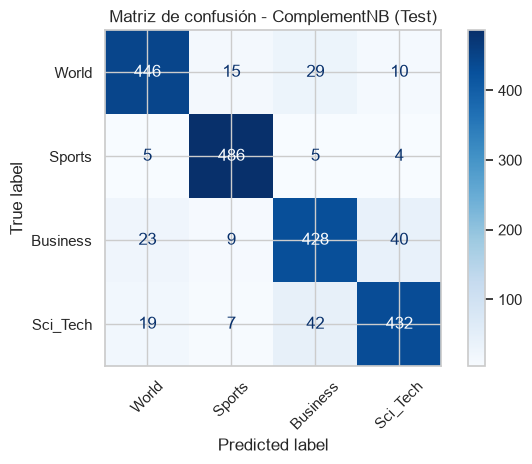

In [423]:

# ============================================================
# 40. Evaluación final sobre el conjunto de prueba
# ============================================================

# Crear una copia del conjunto de prueba
df_test_processed = df_test.copy()

# Limpiar el texto utilizando la función definida anteriormente
df_test_processed["text_clean"] = (
    df_test_processed["text"].apply(clean_text_regex)
)

# Lematizar los documentos utilizando spaCy
docs_test = nlp.pipe(
    df_test_processed["text_clean"],
    batch_size=100,
    n_process=1
)

df_test_processed["text_processed"] = [
    " ".join([
        token.lemma_.lower()
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and token.is_alpha
        and len(token.lemma_) > 1
    ])
    for doc in docs_test
]

# Verificar que no existan documentos vacíos
documentos_vacios_test = (
    df_test_processed["text_processed"].str.strip().eq("").sum()
)

print(f"Documentos de prueba: {len(df_test_processed)}")
print(f"Documentos vacíos: {documentos_vacios_test}")

# Preparar características y etiquetas
X_test = df_test_processed["text_processed"]
y_test = df_test_processed["label"]

# Realizar predicciones con el modelo seleccionado
inicio = time.time()

y_pred_test_nb = mejor_modelo_nb.predict(X_test)

tiempo_prediccion_test = time.time() - inicio

# Calcular métricas generales
accuracy_test = accuracy_score(y_test, y_pred_test_nb)

precision_test = precision_score(
    y_test, y_pred_test_nb, average="macro"
)

recall_test = recall_score(
    y_test, y_pred_test_nb, average="macro"
)

f1_test = f1_score(
    y_test, y_pred_test_nb, average="macro"
)

# Mostrar resultados
print("\nEVALUACIÓN FINAL - COMPLEMENTNB")
print(f"Accuracy:  {accuracy_test:.4f}")
print(f"Precision: {precision_test:.4f}")
print(f"Recall:    {recall_test:.4f}")
print(f"F1-score:  {f1_test:.4f}")

print(f"\nTiempo de predicción: {tiempo_prediccion_test:.4f} segundos")

# Reporte detallado por categoría
print("\nREPORTE DE CLASIFICACIÓN")

print(
    classification_report(
        y_test,
        y_pred_test_nb,
        digits=4,
        zero_division=0
    )
)

# Matriz de confusión
matriz_test_nb = confusion_matrix(
    y_test,
    y_pred_test_nb,
    labels=orden_clases
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_test_nb,
    display_labels=orden_clases
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - ComplementNB (Test)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


1. Resultado final de ComplementNB


```
Accuracy89.60%


F1 macro89.57%


Precision macro89.57%


Recall macro89.60%



Tiempo de predicción: 0.1561 segundos para 2.000 documentos.
```


2. Rendimiento por categoría


```
Categoría	Precision	Recall	F1
Business	84.92%	85.60%	85.26%
Sci_Tech	88.89%	86.40%	87.63%
Sports	94.00%	97.20%	95.58%
World	90.47%	89.20%	89.83%
```




Interpretación:
- Sports continúa siendo la categoría más fácil de identificar.
- Business presenta el F1 más bajo, aunque mantiene un rendimiento razonable.
- Sci_Tech tiene un recall inferior al de las demás categorías.
- World conserva un buen equilibrio entre precisión y recall.
3. Validación frente a Test


```
Métrica	Validación	Test	Diferencia
Accuracy	90.12%	89.60%	-0.52 pp
F1 macro	90.07%	89.57%	-0.50 pp
```




La diferencia es pequeña: medio punto porcentual aproximadamente. Es una buena señal de generalización; no observamos una caída importante al pasar de validación a datos no vistos.

De los 2.000 documentos de prueba:
- 1.792 fueron clasificados correctamente.
- 208 fueron clasificados incorrectamente.

## Celda 41 — Importación y configuración de PyTorch

In [424]:

# ============================================================
# 41. Configuración del entorno PyTorch
# ============================================================

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Configurar dispositivo de entrenamiento
dispositivo = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Mostrar información del entorno
print("CONFIGURACIÓN PYTORCH")
print(f"Versión de PyTorch: {torch.__version__}")
print(f"Dispositivo seleccionado: {dispositivo}")

if torch.cuda.is_available():
    print(f"GPU disponible: {torch.cuda.get_device_name(0)}")
else:
    print("GPU no disponible. Se utilizará CPU.")

# Configurar semilla para reproducibilidad
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


CONFIGURACIÓN PYTORCH
Versión de PyTorch: 2.15.0+cpu
Dispositivo seleccionado: cpu
GPU no disponible. Se utilizará CPU.


## Celda 42 — Construcción del vocabulario

In [425]:
# ============================================================
# 42 — Construcción del vocabulario
# ============================================================

from collections import Counter

# Tokens especiales
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

PAD_IDX = 0
UNK_IDX = 1

# Contar palabras únicamente en el conjunto de entrenamiento
contador_palabras = Counter()

for texto in X_train:
    contador_palabras.update(texto.split())

# Crear vocabulario con índices reservados
vocabulario = {
    PAD_TOKEN: PAD_IDX,
    UNK_TOKEN: UNK_IDX
}

# Asignar un índice a cada palabra
for palabra, frecuencia in contador_palabras.most_common():
    if palabra not in vocabulario:
        vocabulario[palabra] = len(vocabulario)

# Mostrar resultados
print("CONSTRUCCIÓN DEL VOCABULARIO")
print("-" * 50)

print(f"Documentos utilizados: {len(X_train)}")
print(f"Palabras únicas: {len(contador_palabras):,}")
print(f"Tamaño del vocabulario: {len(vocabulario):,}")

print(f"\nÍndice PAD: {vocabulario[PAD_TOKEN]}")
print(f"Índice UNK: {vocabulario[UNK_TOKEN]}")

print("\n20 palabras más frecuentes:")
for palabra, frecuencia in contador_palabras.most_common(20):
    print(f"{palabra:<20} {frecuencia:>6}")

CONSTRUCCIÓN DEL VOCABULARIO
--------------------------------------------------
Documentos utilizados: 6400
Palabras únicas: 15,253
Tamaño del vocabulario: 15,255

Índice PAD: 0
Índice UNK: 1

20 palabras más frecuentes:
say                    1456
new                    1109
ap                      914
year                    795
reuters                 597
company                 520
win                     502
world                   480
oil                     445
game                    440
report                  437
monday                  412
wednesday               402
thursday                401
tuesday                 397
friday                  394
price                   391
million                 373
inc                     364
time                    364


## Celda 43 — Codificación de textos

In [426]:
# ============================================================
# 43 — Codificación de textos
# ============================================================

# Longitud máxima de las secuencias
MAX_LEN = 33

def codificar_texto(texto, vocabulario, max_len=MAX_LEN):
    """
    Convierte un texto en una secuencia de índices numéricos.
    Aplica truncamiento y padding.
    """

    # Separar el texto en palabras
    palabras = texto.split()

    # Convertir palabras en índices
    secuencia = [
        vocabulario.get(palabra, UNK_IDX)
        for palabra in palabras
    ]

    # Truncar si supera la longitud máxima
    secuencia = secuencia[:max_len]

    # Completar con padding si es necesario
    if len(secuencia) < max_len:
        secuencia += [PAD_IDX] * (max_len - len(secuencia))

    return secuencia


# Codificar los conjuntos de entrenamiento, validación y prueba
X_train_codificado = [
    codificar_texto(texto, vocabulario)
    for texto in X_train
]

X_val_codificado = [
    codificar_texto(texto, vocabulario)
    for texto in X_val
]

X_test_codificado = [
    codificar_texto(texto, vocabulario)
    for texto in X_test
]


# Mostrar resultados
print("CODIFICACIÓN DE SECUENCIAS")
print("-" * 50)

print(f"Longitud máxima: {MAX_LEN}")
print(f"Secuencias de entrenamiento: {len(X_train_codificado)}")
print(f"Secuencias de validación: {len(X_val_codificado)}")
print(f"Secuencias de prueba: {len(X_test_codificado)}")

print("\nEjemplo de secuencia:")
print(X_train_codificado[0])

print("\nLongitud de la secuencia:", len(X_train_codificado[0]))

print("\nCantidad de índices PAD en el ejemplo:",
      X_train_codificado[0].count(PAD_IDX))

CODIFICACIÓN DE SECUENCIAS
--------------------------------------------------
Longitud máxima: 33
Secuencias de entrenamiento: 6400
Secuencias de validación: 1600
Secuencias de prueba: 2000

Ejemplo de secuencia:
[1757, 5348, 125, 50, 5349, 1670, 368, 135, 2351, 3229, 9086, 9087, 102, 355, 4522, 5349, 265, 963, 368, 2203, 278, 5348, 526, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Longitud de la secuencia: 33

Cantidad de índices PAD en el ejemplo: 10


## Celda 44 — Codificación de etiquetas

In [427]:
# ============================================================
# 44 — Codificación de etiquetas
# ============================================================

# Definir correspondencia entre categorías e índices
mapa_etiquetas = {
    "World": 0,
    "Sports": 1,
    "Business": 2,
    "Sci_Tech": 3
}

# Codificar etiquetas
y_train_codificado = y_train.map(mapa_etiquetas).tolist()
y_val_codificado = y_val.map(mapa_etiquetas).tolist()
y_test_codificado = y_test.map(mapa_etiquetas).tolist()

# Diccionario inverso para interpretar predicciones
mapa_etiquetas_inverso = {
    indice: etiqueta
    for etiqueta, indice in mapa_etiquetas.items()
}

# Mostrar resultados
print("CODIFICACIÓN DE ETIQUETAS")
print("-" * 50)

print("Correspondencia de clases:")
for etiqueta, indice in mapa_etiquetas.items():
    print(f"{etiqueta:<12} -> {indice}")

print("\nCantidad de etiquetas por conjunto:")
print(f"Entrenamiento: {len(y_train_codificado)}")
print(f"Validación:    {len(y_val_codificado)}")
print(f"Prueba:        {len(y_test_codificado)}")

print("\nEjemplo de etiquetas codificadas:")
print(y_train_codificado[:10])

print("\nCantidad de clases:", len(mapa_etiquetas))

CODIFICACIÓN DE ETIQUETAS
--------------------------------------------------
Correspondencia de clases:
World        -> 0
Sports       -> 1
Business     -> 2
Sci_Tech     -> 3

Cantidad de etiquetas por conjunto:
Entrenamiento: 6400
Validación:    1600
Prueba:        2000

Ejemplo de etiquetas codificadas:
[1, 3, 0, 2, 0, 1, 2, 3, 2, 0]

Cantidad de clases: 4


## Celda 45 — Creación de Dataset y DataLoader

In [428]:
# ============================================================
# 45 — Creación de Dataset y DataLoader
# ============================================================

# Crear una clase personalizada para los datos de texto
class NoticiasDataset(Dataset):

    def __init__(self, textos, etiquetas):
        self.textos = torch.tensor(textos, dtype=torch.long)
        self.etiquetas = torch.tensor(etiquetas, dtype=torch.long)

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, indice):
        return self.textos[indice], self.etiquetas[indice]


# Crear los Dataset de cada conjunto
dataset_train = NoticiasDataset(
    X_train_codificado,
    y_train_codificado
)

dataset_val = NoticiasDataset(
    X_val_codificado,
    y_val_codificado
)

dataset_test = NoticiasDataset(
    X_test_codificado,
    y_test_codificado
)


# Configurar tamaño de lote
BATCH_SIZE = 64

# Crear los DataLoader
loader_train = DataLoader(
    dataset_train,
    batch_size=BATCH_SIZE,
    shuffle=True
)

loader_val = DataLoader(
    dataset_val,
    batch_size=BATCH_SIZE,
    shuffle=False
)

loader_test = DataLoader(
    dataset_test,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# Verificar estructura de los datos
print("DATASET Y DATALOADER")
print("-" * 50)

print(f"Ejemplos de entrenamiento: {len(dataset_train)}")
print(f"Ejemplos de validación:    {len(dataset_val)}")
print(f"Ejemplos de prueba:        {len(dataset_test)}")

print(f"\nTamaño del batch: {BATCH_SIZE}")
print(f"Lotes de entrenamiento: {len(loader_train)}")
print(f"Lotes de validación:    {len(loader_val)}")
print(f"Lotes de prueba:        {len(loader_test)}")


# Inspeccionar un lote
textos_batch, etiquetas_batch = next(iter(loader_train))

print("\nDIMENSIONES DE UN BATCH")
print(f"Textos:   {textos_batch.shape}")
print(f"Etiquetas: {etiquetas_batch.shape}")

print("\nTipo de dato de los textos:", textos_batch.dtype)
print("Tipo de dato de las etiquetas:", etiquetas_batch.dtype)

DATASET Y DATALOADER
--------------------------------------------------
Ejemplos de entrenamiento: 6400
Ejemplos de validación:    1600
Ejemplos de prueba:        2000

Tamaño del batch: 64
Lotes de entrenamiento: 100
Lotes de validación:    25
Lotes de prueba:        32

DIMENSIONES DE UN BATCH
Textos:   torch.Size([64, 33])
Etiquetas: torch.Size([64])

Tipo de dato de los textos: torch.int64
Tipo de dato de las etiquetas: torch.int64


## Celda 46 — Definición del modelo LSTM

In [429]:
# ============================================================
# 46 — Definición del modelo LSTM
# ============================================================

class ModeloLSTM(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_classes=4,
        dropout=0.3,
        pad_idx=PAD_IDX
    ):
        super(ModeloLSTM, self).__init__()

        # Capa de embeddings
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx
        )

        # LSTM bidireccional
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        # Regularización
        self.dropout = nn.Dropout(dropout)

        # Clasificador final
        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x):

        # Convertir índices en vectores
        x = self.embedding(x)

        # Procesar la secuencia con la LSTM
        _, (hidden, _) = self.lstm(x)

        # Obtener los estados finales de ambas direcciones
        hidden_forward = hidden[-2]
        hidden_backward = hidden[-1]

        # Concatenar ambas representaciones
        representation = torch.cat(
            (hidden_forward, hidden_backward),
            dim=1
        )

        # Aplicar dropout
        representation = self.dropout(representation)

        # Clasificación
        output = self.fc(representation)

        return output


# Crear una instancia del modelo
modelo_lstm = ModeloLSTM(
    vocab_size=len(vocabulario),
    embedding_dim=128,
    hidden_dim=128,
    num_classes=len(mapa_etiquetas),
    dropout=0.3
).to(dispositivo)


# Mostrar arquitectura y parámetros
print("ARQUITECTURA DEL MODELO LSTM")
print("-" * 50)

print(modelo_lstm)

total_parametros = sum(
    parametro.numel()
    for parametro in modelo_lstm.parameters()
)

parametros_entrenables = sum(
    parametro.numel()
    for parametro in modelo_lstm.parameters()
    if parametro.requires_grad
)

print("\nTotal de parámetros:", f"{total_parametros:,}")
print("Parámetros entrenables:", f"{parametros_entrenables:,}")
print("Dispositivo:", next(modelo_lstm.parameters()).device)

ARQUITECTURA DEL MODELO LSTM
--------------------------------------------------
ModeloLSTM(
  (embedding): Embedding(15255, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=4, bias=True)
)

Total de parámetros: 2,217,860
Parámetros entrenables: 2,217,860
Dispositivo: cpu


## Celda 47 — Prueba de propagación (Forward Pass)

In [430]:
# ============================================================
# 47 — Prueba de propagación (Forward Pass)
# ============================================================

# Obtener un lote de entrenamiento
textos_batch, etiquetas_batch = next(iter(loader_train))

# Mover los datos al dispositivo seleccionado
textos_batch = textos_batch.to(dispositivo)
etiquetas_batch = etiquetas_batch.to(dispositivo)

# Desactivar el cálculo de gradientes para esta prueba
modelo_lstm.eval()

with torch.no_grad():

    # Obtener las predicciones del modelo
    salidas = modelo_lstm(textos_batch)

# Verificar dimensiones y resultados
print("PRUEBA FORWARD PASS")
print("-" * 50)

print("Dimensiones de entrada:", textos_batch.shape)
print("Dimensiones de salida:", salidas.shape)

print("\nTipo de dato de salida:", salidas.dtype)
print("Dispositivo de salida:", salidas.device)

print("\nPuntuaciones de la primera noticia:")
print(salidas[0])

# Obtener la clase con mayor puntuación
prediccion = torch.argmax(salidas, dim=1)

print("\nPredicción de la primera noticia:")
print(mapa_etiquetas_inverso[prediccion[0].item()])

print("\nEtiqueta real de la primera noticia:")
print(mapa_etiquetas_inverso[etiquetas_batch[0].item()])

PRUEBA FORWARD PASS
--------------------------------------------------
Dimensiones de entrada: torch.Size([64, 33])
Dimensiones de salida: torch.Size([64, 4])

Tipo de dato de salida: torch.float32
Dispositivo de salida: cpu

Puntuaciones de la primera noticia:
tensor([0.0134, 0.0031, 0.0310, 0.1062])

Predicción de la primera noticia:
Sci_Tech

Etiqueta real de la primera noticia:
Sci_Tech


## Celda 48 — Función de pérdida y optimizador

In [431]:
# ============================================================
# 48 — Configuración de pérdida y optimizador
# ============================================================

# Función de pérdida para clasificación multiclase
criterio = nn.CrossEntropyLoss()

# Optimizador Adam
LEARNING_RATE = 0.001

optimizador = torch.optim.Adam(
    modelo_lstm.parameters(),
    lr=LEARNING_RATE
)

# Mostrar configuración
print("CONFIGURACIÓN DEL ENTRENAMIENTO")
print("-" * 50)

print("Función de pérdida:", criterio)
print("Optimizador:", optimizador.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Parámetros optimizados:",
      sum(p.numel() for p in modelo_lstm.parameters() if p.requires_grad))

# Prueba de cálculo de pérdida con el batch anterior
perdida_prueba = criterio(salidas, etiquetas_batch)

print("\nPérdida inicial de prueba:", round(perdida_prueba.item(), 4))

CONFIGURACIÓN DEL ENTRENAMIENTO
--------------------------------------------------
Función de pérdida: CrossEntropyLoss()
Optimizador: Adam
Learning rate: 0.001
Parámetros optimizados: 2217860

Pérdida inicial de prueba: 1.3962


## Celda 49 — Implementación del ciclo de entrenamiento

In [432]:
# ============================================================
# 49 — Funciones de entrenamiento y evaluación
# ============================================================

from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import time


def entrenar_epoca(modelo, loader, criterio, optimizador, dispositivo):

    modelo.train()

    perdida_acumulada = 0.0
    predicciones = []
    etiquetas_reales = []

    tiempo_inicio = time.time()

    for textos, etiquetas in loader:

        # Mover los datos al dispositivo
        textos = textos.to(dispositivo)
        etiquetas = etiquetas.to(dispositivo)

        # Reiniciar los gradientes
        optimizador.zero_grad()

        # Propagación hacia adelante
        salidas = modelo(textos)

        # Calcular la pérdida
        perdida = criterio(salidas, etiquetas)

        # Retropropagación
        perdida.backward()

        # Actualizar los parámetros
        optimizador.step()

        # Acumular pérdida ponderada por cantidad de ejemplos
        perdida_acumulada += perdida.item() * textos.size(0)

        # Obtener predicciones
        predicciones.extend(
            torch.argmax(salidas, dim=1).detach().cpu().numpy()
        )

        etiquetas_reales.extend(
            etiquetas.detach().cpu().numpy()
        )

    perdida_promedio = perdida_acumulada / len(loader.dataset)

    accuracy = accuracy_score(etiquetas_reales, predicciones)

    f1_macro = f1_score(
        etiquetas_reales,
        predicciones,
        average="macro"
    )

    tiempo_total = time.time() - tiempo_inicio

    return perdida_promedio, accuracy, f1_macro, tiempo_total


def evaluar_modelo(modelo, loader, criterio, dispositivo):

    modelo.eval()

    perdida_acumulada = 0.0
    predicciones = []
    etiquetas_reales = []

    with torch.no_grad():

        for textos, etiquetas in loader:

            # Mover los datos al dispositivo
            textos = textos.to(dispositivo)
            etiquetas = etiquetas.to(dispositivo)

            # Obtener predicciones
            salidas = modelo(textos)

            # Calcular pérdida
            perdida = criterio(salidas, etiquetas)

            perdida_acumulada += perdida.item() * textos.size(0)

            predicciones.extend(
                torch.argmax(salidas, dim=1).cpu().numpy()
            )

            etiquetas_reales.extend(
                etiquetas.cpu().numpy()
            )

    perdida_promedio = perdida_acumulada / len(loader.dataset)

    accuracy = accuracy_score(etiquetas_reales, predicciones)

    f1_macro = f1_score(
        etiquetas_reales,
        predicciones,
        average="macro"
    )

    return perdida_promedio, accuracy, f1_macro

## Celda 50 — Entrenamiento del modelo LSTM

In [433]:
# ============================================================
# 50 — Entrenamiento del modelo LSTM
# ============================================================

import copy

# Configuración del entrenamiento
EPOCHS = 15
PATIENCE = 3

# Variables para registrar el mejor modelo
mejor_f1 = 0.0
mejor_epoca = 0
epocas_sin_mejora = 0

historial_entrenamiento = []

# Guardar el inicio del entrenamiento
tiempo_inicio_total = time.time()

print("INICIO DEL ENTRENAMIENTO LSTM")
print("-" * 65)

for epoca in range(EPOCHS):

    # Entrenamiento
    perdida_train, accuracy_train, f1_train, tiempo_train = entrenar_epoca(
        modelo_lstm,
        loader_train,
        criterio,
        optimizador,
        dispositivo
    )

    # Evaluación sobre validación
    perdida_val, accuracy_val, f1_val = evaluar_modelo(
        modelo_lstm,
        loader_val,
        criterio,
        dispositivo
    )

    # Registrar métricas
    historial_entrenamiento.append({
        "epoca": epoca + 1,
        "perdida_train": perdida_train,
        "accuracy_train": accuracy_train,
        "f1_train": f1_train,
        "perdida_val": perdida_val,
        "accuracy_val": accuracy_val,
        "f1_val": f1_val,
        "tiempo_train": tiempo_train
    })

    print(
        f"Época {epoca + 1:02d}/{EPOCHS} | "
        f"Loss Train: {perdida_train:.4f} | "
        f"Acc Train: {accuracy_train:.4f} | "
        f"F1 Train: {f1_train:.4f} | "
        f"Loss Val: {perdida_val:.4f} | "
        f"Acc Val: {accuracy_val:.4f} | "
        f"F1 Val: {f1_val:.4f} | "
        f"Tiempo: {tiempo_train:.2f}s"
    )

    # Comprobar mejora del F1 macro
    if f1_val > mejor_f1:

        mejor_f1 = f1_val
        mejor_epoca = epoca + 1
        epocas_sin_mejora = 0

        # Guardar los mejores pesos
        mejores_pesos = copy.deepcopy(modelo_lstm.state_dict())

    else:
        epocas_sin_mejora += 1

    # Early Stopping
    if epocas_sin_mejora >= PATIENCE:

        print(
            f"\nEarly Stopping activado en la época {epoca + 1}."
        )
        break


# Restaurar los mejores pesos
modelo_lstm.load_state_dict(mejores_pesos)

tiempo_total = time.time() - tiempo_inicio_total

print("\n" + "=" * 65)
print("ENTRENAMIENTO FINALIZADO")
print("=" * 65)

print(f"Mejor época: {mejor_epoca}")
print(f"Mejor F1 macro de validación: {mejor_f1:.4f}")
print(f"Tiempo total: {tiempo_total:.2f} segundos")

INICIO DEL ENTRENAMIENTO LSTM
-----------------------------------------------------------------
Época 01/15 | Loss Train: 1.1595 | Acc Train: 0.5022 | F1 Train: 0.5020 | Loss Val: 0.7417 | Acc Val: 0.7244 | F1 Val: 0.7237 | Tiempo: 2.98s
Época 02/15 | Loss Train: 0.5609 | Acc Train: 0.8003 | F1 Train: 0.8000 | Loss Val: 0.6333 | Acc Val: 0.7794 | F1 Val: 0.7776 | Tiempo: 2.93s
Época 03/15 | Loss Train: 0.3331 | Acc Train: 0.8897 | F1 Train: 0.8895 | Loss Val: 0.5694 | Acc Val: 0.8119 | F1 Val: 0.8104 | Tiempo: 2.80s
Época 04/15 | Loss Train: 0.2153 | Acc Train: 0.9348 | F1 Train: 0.9348 | Loss Val: 0.6509 | Acc Val: 0.8094 | F1 Val: 0.8080 | Tiempo: 2.92s
Época 05/15 | Loss Train: 0.1490 | Acc Train: 0.9547 | F1 Train: 0.9547 | Loss Val: 0.6115 | Acc Val: 0.8281 | F1 Val: 0.8274 | Tiempo: 2.90s
Época 06/15 | Loss Train: 0.0979 | Acc Train: 0.9695 | F1 Train: 0.9695 | Loss Val: 0.7597 | Acc Val: 0.8025 | F1 Val: 0.8005 | Tiempo: 2.87s
Época 07/15 | Loss Train: 0.0670 | Acc Train: 0.9825

## Celda 51 — Visualización de las curvas de aprendizaje

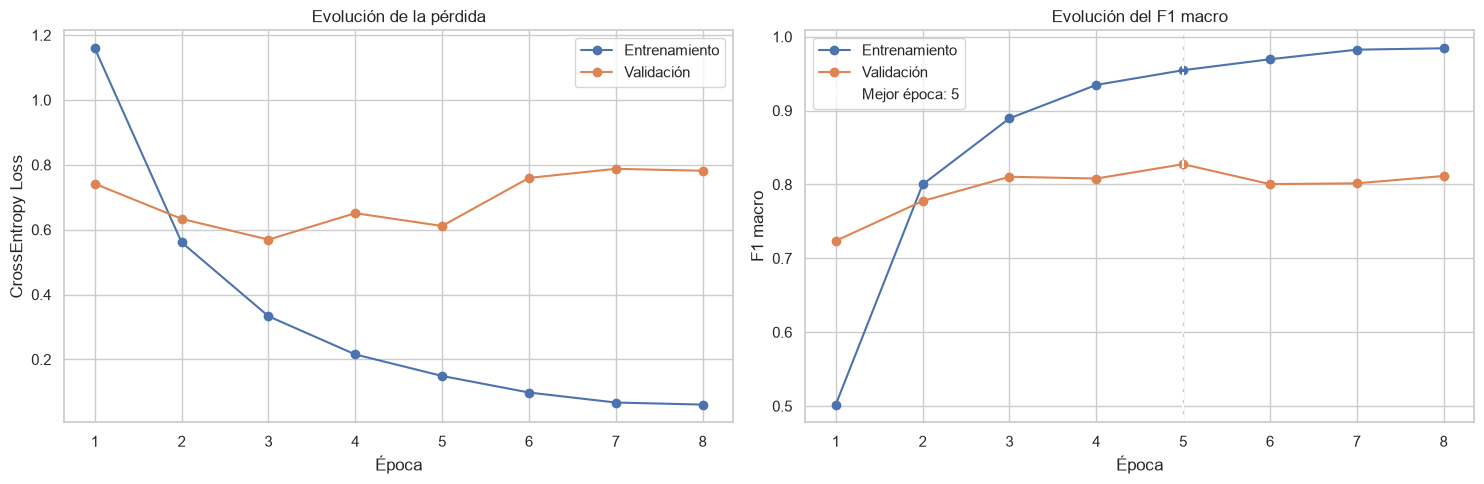

,epoca,perdida_train,accuracy_train,f1_train,perdida_val,accuracy_val,f1_val,tiempo_train
0,1,1.1595,0.5022,0.5020,0.7417,0.7244,0.7237,2.9759
1,2,0.5609,0.8003,0.8000,0.6333,0.7794,0.7776,2.9255
2,3,0.3331,0.8897,0.8895,0.5694,0.8119,0.8104,2.8030
3,4,0.2153,0.9348,0.9348,0.6509,0.8094,0.8080,2.9159
4,5,0.1490,0.9547,0.9547,0.6115,0.8281,0.8274,2.9036
5,6,0.0979,0.9695,0.9695,0.7597,0.8025,0.8005,2.8677
6,7,0.0670,0.9825,0.9825,0.7877,0.8038,0.8016,2.8412
7,8,0.0606,0.9844,0.9844,0.7818,0.8125,0.8115,2.8342


In [434]:
# ============================================================
# 51 — Visualización de curvas de aprendizaje
# ============================================================

# Convertir historial en DataFrame
df_historial_lstm = pd.DataFrame(historial_entrenamiento)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Curvas de pérdida
axes[0].plot(
    df_historial_lstm["epoca"],
    df_historial_lstm["perdida_train"],
    marker="o",
    label="Entrenamiento"
)

axes[0].plot(
    df_historial_lstm["epoca"],
    df_historial_lstm["perdida_val"],
    marker="o",
    label="Validación"
)

axes[0].set_title("Evolución de la pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("CrossEntropy Loss")
axes[0].legend()
axes[0].grid(True)

# Curvas de F1 macro
axes[1].plot(
    df_historial_lstm["epoca"],
    df_historial_lstm["f1_train"],
    marker="o",
    label="Entrenamiento"
)

axes[1].plot(
    df_historial_lstm["epoca"],
    df_historial_lstm["f1_val"],
    marker="o",
    label="Validación"
)

axes[1].axvline(
    mejor_epoca,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca}"
)

axes[1].set_title("Evolución del F1 macro")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("F1 macro")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Mostrar resumen de métricas
display(
    df_historial_lstm.round(4)
)

## Celda 52 — Evaluación por categoría

INFORME DE CLASIFICACIÓN — VALIDACIÓN
------------------------------------------------------------
              precision    recall  f1-score   support

       World     0.8621    0.8125    0.8366       400
      Sports     0.8233    0.9200    0.8689       400
    Business     0.7935    0.7975    0.7955       400
    Sci_Tech     0.8369    0.7825    0.8088       400

    accuracy                         0.8281      1600
   macro avg     0.8289    0.8281    0.8274      1600
weighted avg     0.8289    0.8281    0.8274      1600



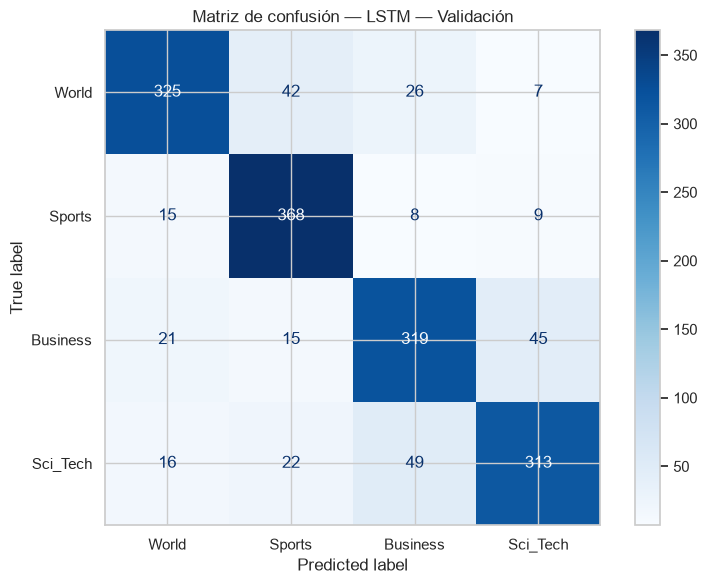

In [435]:
# ============================================================
# 52 — Evaluación del modelo LSTM sobre validación
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Obtener predicciones sobre validación
modelo_lstm.eval()

predicciones_val = []
etiquetas_val_reales = []

with torch.no_grad():

    for textos, etiquetas in loader_val:

        textos = textos.to(dispositivo)

        salidas = modelo_lstm(textos)

        predicciones = torch.argmax(salidas, dim=1)

        predicciones_val.extend(
            predicciones.cpu().numpy()
        )

        etiquetas_val_reales.extend(
            etiquetas.numpy()
        )


# Generar informe de clasificación
print("INFORME DE CLASIFICACIÓN — VALIDACIÓN")
print("-" * 60)

print(
    classification_report(
        etiquetas_val_reales,
        predicciones_val,
        labels=[0, 1, 2, 3],
        target_names=[
            mapa_etiquetas_inverso[i]
            for i in range(4)
        ],
        digits=4,
        zero_division=0
    )
)


# Calcular matriz de confusión
matriz_confusion_val = confusion_matrix(
    etiquetas_val_reales,
    predicciones_val,
    labels=[0, 1, 2, 3]
)

# Visualizar matriz de confusión
display_confusion = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion_val,
    display_labels=[
        mapa_etiquetas_inverso[i]
        for i in range(4)
    ]
)

fig, ax = plt.subplots(figsize=(8, 6))

display_confusion.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Matriz de confusión — LSTM — Validación")
plt.tight_layout()
plt.show()

## Celda 53 — análisis de errores

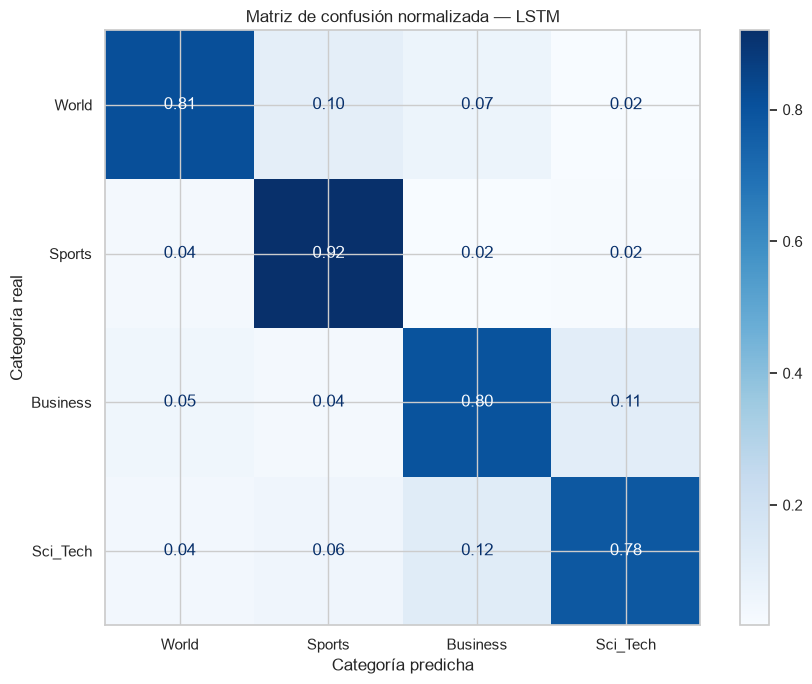

PRINCIPALES CONFUSIONES
--------------------------------------------------

World:
  Confundida con Sports: 42 noticias
  Confundida con Business: 26 noticias
  Confundida con Sci_Tech: 7 noticias

Sports:
  Confundida con World: 15 noticias
  Confundida con Sci_Tech: 9 noticias
  Confundida con Business: 8 noticias

Business:
  Confundida con Sci_Tech: 45 noticias
  Confundida con World: 21 noticias
  Confundida con Sports: 15 noticias

Sci_Tech:
  Confundida con Business: 49 noticias
  Confundida con Sports: 22 noticias
  Confundida con World: 16 noticias


In [436]:
# ============================================================
# 53 — Análisis de errores por categoría
# ============================================================

# Calcular matriz de confusión normalizada
matriz_normalizada = confusion_matrix(
    etiquetas_val_reales,
    predicciones_val,
    labels=[0, 1, 2, 3],
    normalize="true"
)

# Obtener nombres de las categorías
nombres_clases = [
    mapa_etiquetas_inverso[i]
    for i in range(4)
]

# Visualizar matriz normalizada
fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_normalizada,
    display_labels=nombres_clases
)

disp.plot(
    cmap="Blues",
    values_format=".2f",
    ax=ax
)

plt.title("Matriz de confusión normalizada — LSTM")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.tight_layout()
plt.show()


# Identificar las principales confusiones
print("PRINCIPALES CONFUSIONES")
print("-" * 50)

for i, clase_real in enumerate(nombres_clases):

    errores = []

    for j, clase_predicha in enumerate(nombres_clases):

        if i != j and matriz_confusion_val[i, j] > 0:
            errores.append((
                clase_predicha,
                matriz_confusion_val[i, j]
            ))

    errores.sort(key=lambda x: x[1], reverse=True)

    print(f"\n{clase_real}:")

    for clase_predicha, cantidad in errores:
        print(f"  Confundida con {clase_predicha}: {cantidad} noticias")

## Celda 54 — Preparar una segunda versión de LSTM

In [437]:
# ============================================================
# 54 — Segunda versión LSTM con mayor regularización
# ============================================================

# Crear una nueva instancia del modelo
modelo_lstm_v2 = ModeloLSTM(
    vocab_size=len(vocabulario),
    embedding_dim=128,
    hidden_dim=128,
    num_classes=len(mapa_etiquetas),
    dropout=0.5
).to(dispositivo)

# Configurar función de pérdida
criterio_v2 = nn.CrossEntropyLoss()

# Configurar optimizador
optimizador_v2 = torch.optim.Adam(
    modelo_lstm_v2.parameters(),
    lr=0.001
)

# Mostrar configuración
print("SEGUNDA VERSIÓN LSTM")
print("-" * 50)

print("Embedding:", 128)
print("Hidden dimension:", 128)
print("Bidireccional:", True)
print("Dropout:", 0.5)
print("Learning rate:", 0.001)
print("Batch size:", BATCH_SIZE)

print(
    "\nParámetros entrenables:",
    f"{sum(p.numel() for p in modelo_lstm_v2.parameters() if p.requires_grad):,}"
)

print(
    "Dispositivo:",
    next(modelo_lstm_v2.parameters()).device
)

SEGUNDA VERSIÓN LSTM
--------------------------------------------------
Embedding: 128
Hidden dimension: 128
Bidireccional: True
Dropout: 0.5
Learning rate: 0.001
Batch size: 64

Parámetros entrenables: 2,217,860
Dispositivo: cpu


## Celda 55 — Entrenamiento LSTM v2

In [438]:
# ============================================================
# 55 — Entrenamiento de la segunda versión LSTM
# ============================================================

import copy

EPOCHS_V2 = 15
PATIENCE_V2 = 3

mejor_f1_v2 = 0
mejor_epoca_v2 = 0
epocas_sin_mejora_v2 = 0

mejores_pesos_v2 = copy.deepcopy(modelo_lstm_v2.state_dict())
historial_lstm_v2 = []

print("INICIANDO ENTRENAMIENTO LSTM V2")
print("-" * 55)

for epoca in range(EPOCHS_V2):

    perdida_train, accuracy_train, f1_train, tiempo = entrenar_epoca(
        modelo_lstm_v2,
        loader_train,
        criterio_v2,
        optimizador_v2,
        dispositivo
    )

    perdida_val, accuracy_val, f1_val = evaluar_modelo(
        modelo_lstm_v2,
        loader_val,
        criterio_v2,
        dispositivo
    )

    historial_lstm_v2.append({
        "epoca": epoca + 1,
        "perdida_train": perdida_train,
        "accuracy_train": accuracy_train,
        "f1_train": f1_train,
        "perdida_val": perdida_val,
        "accuracy_val": accuracy_val,
        "f1_val": f1_val,
        "tiempo": tiempo
    })

    print(
        f"Época {epoca + 1:02d} | "
        f"Loss Train: {perdida_train:.4f} | "
        f"F1 Train: {f1_train:.4f} | "
        f"Loss Val: {perdida_val:.4f} | "
        f"F1 Val: {f1_val:.4f} | "
        f"Tiempo: {tiempo:.2f}s"
    )

    # Guardar los pesos cuando mejora el F1 de validación
    if f1_val > mejor_f1_v2:

        mejor_f1_v2 = f1_val
        mejor_epoca_v2 = epoca + 1
        mejores_pesos_v2 = copy.deepcopy(
            modelo_lstm_v2.state_dict()
        )

        epocas_sin_mejora_v2 = 0

    else:
        epocas_sin_mejora_v2 += 1

    # Detener si no hay mejora durante varias épocas
    if epocas_sin_mejora_v2 >= PATIENCE_V2:

        print("\nEarly Stopping activado.")
        break


# Restaurar los mejores pesos de validación
modelo_lstm_v2.load_state_dict(mejores_pesos_v2)

print("\n" + "-" * 55)
print("RESULTADO DEL ENTRENAMIENTO LSTM V2")
print("-" * 55)

print(f"Mejor época: {mejor_epoca_v2}")
print(f"Mejor F1 validación: {mejor_f1_v2:.4f}")
print(f"Épocas ejecutadas: {len(historial_lstm_v2)}")

INICIANDO ENTRENAMIENTO LSTM V2
-------------------------------------------------------
Época 01 | Loss Train: 1.2385 | F1 Train: 0.4430 | Loss Val: 0.8500 | F1 Val: 0.6662 | Tiempo: 3.06s
Época 02 | Loss Train: 0.6530 | F1 Train: 0.7598 | Loss Val: 0.5607 | F1 Val: 0.7885 | Tiempo: 2.94s
Época 03 | Loss Train: 0.4068 | F1 Train: 0.8577 | Loss Val: 0.5191 | F1 Val: 0.8027 | Tiempo: 2.91s
Época 04 | Loss Train: 0.2707 | F1 Train: 0.9129 | Loss Val: 0.5496 | F1 Val: 0.8093 | Tiempo: 2.85s
Época 05 | Loss Train: 0.1880 | F1 Train: 0.9405 | Loss Val: 0.5636 | F1 Val: 0.8123 | Tiempo: 2.87s
Época 06 | Loss Train: 0.1303 | F1 Train: 0.9615 | Loss Val: 0.5722 | F1 Val: 0.8251 | Tiempo: 2.84s
Época 07 | Loss Train: 0.0872 | F1 Train: 0.9742 | Loss Val: 0.6484 | F1 Val: 0.8164 | Tiempo: 2.89s
Época 08 | Loss Train: 0.0565 | F1 Train: 0.9859 | Loss Val: 0.6933 | F1 Val: 0.8175 | Tiempo: 3.02s
Época 09 | Loss Train: 0.0430 | F1 Train: 0.9875 | Loss Val: 0.8604 | F1 Val: 0.7977 | Tiempo: 3.02s

Ea

## Celda 56 — Evaluación por categoría de LSTM v2

In [439]:
# ============================================================
# 56 — Evaluación por categoría de LSTM v2
# ============================================================

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

modelo_lstm_v2.eval()

predicciones_val_v2 = []
etiquetas_val_reales_v2 = []

with torch.no_grad():

    for textos, etiquetas in loader_val:

        textos = textos.to(dispositivo)

        salidas = modelo_lstm_v2(textos)

        predicciones = torch.argmax(salidas, dim=1)

        predicciones_val_v2.extend(
            predicciones.cpu().numpy()
        )

        etiquetas_val_reales_v2.extend(
            etiquetas.numpy()
        )


# Informe de clasificación
print("INFORME DE CLASIFICACIÓN — LSTM V2")
print("-" * 65)

print(
    classification_report(
        etiquetas_val_reales_v2,
        predicciones_val_v2,
        target_names=list(mapa_etiquetas.keys()),
        digits=4
    )
)


# Matriz de confusión
matriz_confusion_v2 = confusion_matrix(
    etiquetas_val_reales_v2,
    predicciones_val_v2
)

print("MATRIZ DE CONFUSIÓN — LSTM V2")
print(matriz_confusion_v2)

INFORME DE CLASIFICACIÓN — LSTM V2
-----------------------------------------------------------------
              precision    recall  f1-score   support

       World     0.8485    0.8400    0.8442       400
      Sports     0.8732    0.9125    0.8924       400
    Business     0.7903    0.7725    0.7813       400
    Sci_Tech     0.7873    0.7775    0.7824       400

    accuracy                         0.8256      1600
   macro avg     0.8248    0.8256    0.8251      1600
weighted avg     0.8248    0.8256    0.8251      1600

MATRIZ DE CONFUSIÓN — LSTM V2
[[336  21  29  14]
 [ 22 365   6   7]
 [ 19   9 309  63]
 [ 19  23  47 311]]


## Celda 57 — Definición e inicialización de GRU

In [440]:
# ============================================================
# 57 — Definición del modelo GRU bidireccional
# ============================================================

class ModeloGRU(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_classes=4,
        dropout=0.3,
        pad_idx=PAD_IDX
    ):
        super().__init__()

        # Capa de embeddings
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_idx
        )

        # GRU bidireccional
        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        # Regularización
        self.dropout = nn.Dropout(dropout)

        # Capa de clasificación
        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x):

        # Convertir índices en embeddings
        x = self.embedding(x)

        # Obtener estado oculto final
        _, hidden = self.gru(x)

        # Estados finales de ambas direcciones
        hidden_forward = hidden[-2]
        hidden_backward = hidden[-1]

        # Concatenar representaciones
        representation = torch.cat(
            (hidden_forward, hidden_backward),
            dim=1
        )

        representation = self.dropout(representation)

        return self.fc(representation)


# Inicializar modelo GRU
modelo_gru = ModeloGRU(
    vocab_size=len(vocabulario),
    embedding_dim=128,
    hidden_dim=128,
    num_classes=len(mapa_etiquetas),
    dropout=0.3
).to(dispositivo)


# Configurar entrenamiento
criterio_gru = nn.CrossEntropyLoss()

optimizador_gru = torch.optim.Adam(
    modelo_gru.parameters(),
    lr=0.001
)


# Mostrar configuración
parametros_gru = sum(
    p.numel()
    for p in modelo_gru.parameters()
    if p.requires_grad
)

print("MODELO GRU BIDIRECCIONAL")
print("-" * 55)
print(modelo_gru)
print(f"\nParámetros entrenables: {parametros_gru:,}")
print(f"Dispositivo: {dispositivo}")

MODELO GRU BIDIRECCIONAL
-------------------------------------------------------
ModeloGRU(
  (embedding): Embedding(15255, 128, padding_idx=0)
  (gru): GRU(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=4, bias=True)
)

Parámetros entrenables: 2,151,812
Dispositivo: cpu


## Celda 58 — Entrenamiento GRU

In [441]:
# ============================================================
# 58 — Entrenamiento del modelo GRU
# ============================================================

import copy

EPOCHS_GRU = 15
PATIENCE_GRU = 3

mejor_f1_gru = 0
mejor_epoca_gru = 0
epocas_sin_mejora_gru = 0

mejores_pesos_gru = copy.deepcopy(modelo_gru.state_dict())
historial_gru = []

print("INICIANDO ENTRENAMIENTO GRU")
print("-" * 55)

for epoca in range(EPOCHS_GRU):

    perdida_train, accuracy_train, f1_train, tiempo = entrenar_epoca(
        modelo_gru,
        loader_train,
        criterio_gru,
        optimizador_gru,
        dispositivo
    )

    perdida_val, accuracy_val, f1_val = evaluar_modelo(
        modelo_gru,
        loader_val,
        criterio_gru,
        dispositivo
    )

    historial_gru.append({
        "epoca": epoca + 1,
        "perdida_train": perdida_train,
        "accuracy_train": accuracy_train,
        "f1_train": f1_train,
        "perdida_val": perdida_val,
        "accuracy_val": accuracy_val,
        "f1_val": f1_val,
        "tiempo": tiempo
    })

    print(
        f"Época {epoca + 1:02d} | "
        f"Loss Train: {perdida_train:.4f} | "
        f"F1 Train: {f1_train:.4f} | "
        f"Loss Val: {perdida_val:.4f} | "
        f"F1 Val: {f1_val:.4f} | "
        f"Tiempo: {tiempo:.2f}s"
    )

    # Guardar los mejores pesos según F1 de validación
    if f1_val > mejor_f1_gru:

        mejor_f1_gru = f1_val
        mejor_epoca_gru = epoca + 1

        mejores_pesos_gru = copy.deepcopy(
            modelo_gru.state_dict()
        )

        epocas_sin_mejora_gru = 0

    else:
        epocas_sin_mejora_gru += 1

    # Aplicar Early Stopping
    if epocas_sin_mejora_gru >= PATIENCE_GRU:

        print("\nEarly Stopping activado.")
        break


# Restaurar los mejores pesos
modelo_gru.load_state_dict(mejores_pesos_gru)

print("\n" + "-" * 55)
print("RESULTADO DEL ENTRENAMIENTO GRU")
print("-" * 55)

print(f"Mejor época: {mejor_epoca_gru}")
print(f"Mejor F1 validación: {mejor_f1_gru:.4f}")
print(f"Épocas ejecutadas: {len(historial_gru)}")

INICIANDO ENTRENAMIENTO GRU
-------------------------------------------------------
Época 01 | Loss Train: 1.1631 | F1 Train: 0.4845 | Loss Val: 0.7953 | F1 Val: 0.6851 | Tiempo: 5.24s
Época 02 | Loss Train: 0.5597 | F1 Train: 0.8004 | Loss Val: 0.5247 | F1 Val: 0.8094 | Tiempo: 4.93s
Época 03 | Loss Train: 0.3231 | F1 Train: 0.8935 | Loss Val: 0.5177 | F1 Val: 0.8278 | Tiempo: 4.89s
Época 04 | Loss Train: 0.2021 | F1 Train: 0.9333 | Loss Val: 0.5063 | F1 Val: 0.8290 | Tiempo: 5.05s
Época 05 | Loss Train: 0.1250 | F1 Train: 0.9649 | Loss Val: 0.5173 | F1 Val: 0.8404 | Tiempo: 4.88s
Época 06 | Loss Train: 0.0840 | F1 Train: 0.9736 | Loss Val: 0.6037 | F1 Val: 0.8184 | Tiempo: 4.92s
Época 07 | Loss Train: 0.0567 | F1 Train: 0.9826 | Loss Val: 0.5699 | F1 Val: 0.8391 | Tiempo: 4.97s
Época 08 | Loss Train: 0.0307 | F1 Train: 0.9934 | Loss Val: 0.6361 | F1 Val: 0.8294 | Tiempo: 5.01s

Early Stopping activado.

-------------------------------------------------------
RESULTADO DEL ENTRENAMIEN

## Celda 59 — Evaluación por categoría de GRU

In [442]:
# ============================================================
# 59 — Evaluación por categoría de GRU
# ============================================================

from sklearn.metrics import classification_report, confusion_matrix

modelo_gru.eval()

predicciones_val_gru = []
etiquetas_val_reales_gru = []

with torch.no_grad():

    for textos, etiquetas in loader_val:

        textos = textos.to(dispositivo)

        salidas = modelo_gru(textos)

        predicciones = torch.argmax(salidas, dim=1)

        predicciones_val_gru.extend(
            predicciones.cpu().numpy()
        )

        etiquetas_val_reales_gru.extend(
            etiquetas.numpy()
        )


# Informe de clasificación
print("INFORME DE CLASIFICACIÓN — GRU")
print("-" * 65)

print(
    classification_report(
        etiquetas_val_reales_gru,
        predicciones_val_gru,
        target_names=list(mapa_etiquetas.keys()),
        digits=4
    )
)


# Matriz de confusión
matriz_confusion_gru = confusion_matrix(
    etiquetas_val_reales_gru,
    predicciones_val_gru
)

print("MATRIZ DE CONFUSIÓN — GRU")
print(matriz_confusion_gru)

INFORME DE CLASIFICACIÓN — GRU
-----------------------------------------------------------------
              precision    recall  f1-score   support

       World     0.8305    0.8575    0.8438       400
      Sports     0.9253    0.8975    0.9112       400
    Business     0.8457    0.7400    0.7893       400
    Sci_Tech     0.7728    0.8675    0.8174       400

    accuracy                         0.8406      1600
   macro avg     0.8436    0.8406    0.8404      1600
weighted avg     0.8436    0.8406    0.8404      1600

MATRIZ DE CONFUSIÓN — GRU
[[343  15  22  20]
 [ 23 359   6  12]
 [ 26   8 296  70]
 [ 21   6  26 347]]


## Celda 60 — Comparación consolidada de modelos

COMPARACIÓN DE MODELOS — VALIDACIÓN
-----------------------------------------------------------------


,modelo,dropout,mejor_epoca,accuracy,f1_macro
0,ComplementNB,-,-,0.9012,0.9007
1,GRU,0.3,5.000000,0.7900,0.8404
2,LSTM v1,0.3,5.000000,0.8325,0.8274
3,LSTM v2,0.5,6.000000,0.8287,0.8251


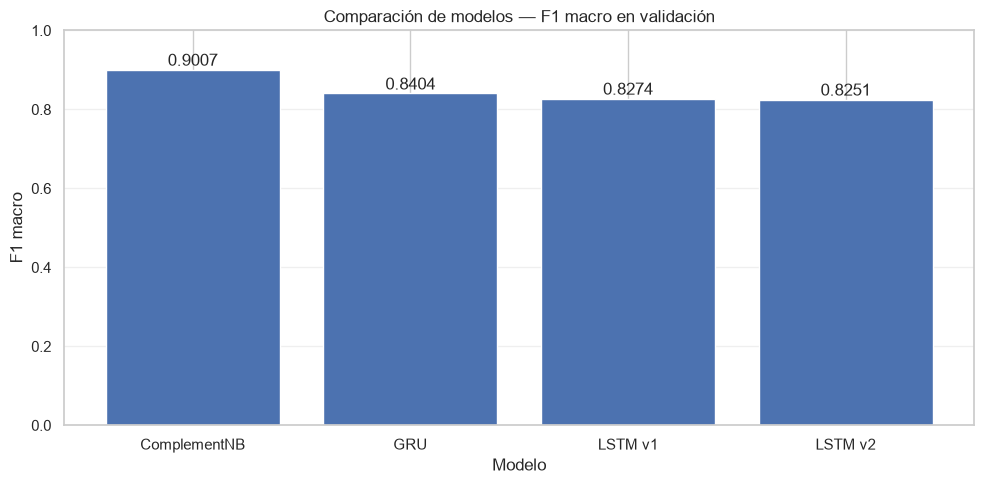

In [443]:
# ============================================================
# 60 — Comparación consolidada de modelos
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Resultados obtenidos sobre el conjunto de validación
resultados_modelos = pd.DataFrame([
    {
        "modelo": "LSTM v1",
        "dropout": 0.3,
        "mejor_epoca": mejor_epoca,
        "accuracy": 0.8325,
        "f1_macro": mejor_f1
    },
    {
        "modelo": "LSTM v2",
        "dropout": 0.5,
        "mejor_epoca": mejor_epoca_v2,
        "accuracy": 0.8287,
        "f1_macro": mejor_f1_v2
    },
    {
        "modelo": "GRU",
        "dropout": 0.3,
        "mejor_epoca": mejor_epoca_gru,
        "accuracy": 0.7900,
        "f1_macro": mejor_f1_gru
    },
    {
        "modelo": "ComplementNB",
        "dropout": None,
        "mejor_epoca": None,
        "accuracy": 0.9012,
        "f1_macro": 0.9007
    }
])

# Ordenar por F1 macro descendente
resultados_modelos = resultados_modelos.sort_values(
    by="f1_macro",
    ascending=False
).reset_index(drop=True)

print("COMPARACIÓN DE MODELOS — VALIDACIÓN")
print("-" * 65)

display(
    resultados_modelos.style.format({
        "dropout": "{:.1f}",
        "accuracy": "{:.4f}",
        "f1_macro": "{:.4f}"
    }, na_rep="-")
)


# Gráfico comparativo de F1 macro
plt.figure(figsize=(10, 5))

plt.bar(
    resultados_modelos["modelo"],
    resultados_modelos["f1_macro"]
)

plt.title("Comparación de modelos — F1 macro en validación")
plt.xlabel("Modelo")
plt.ylabel("F1 macro")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

for i, valor in enumerate(resultados_modelos["f1_macro"]):
    plt.text(
        i,
        valor + 0.01,
        f"{valor:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

## Celda 61 — Identificar el vectorizador existente

In [444]:
# ============================================================
# 61 — Identificación de variables TF-IDF
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer

print("VECTORIZADORES TF-IDF EN MEMORIA")
print("-" * 55)

for nombre, objeto in globals().copy().items():

    if isinstance(objeto, TfidfVectorizer):

        esta_ajustado = hasattr(objeto, "vocabulary_")

        print(f"Variable: {nombre}")
        print(f"Ajustado: {esta_ajustado}")

        if esta_ajustado:
            print(f"Características: {len(objeto.vocabulary_)}")

        print("-" * 55)

VECTORIZADORES TF-IDF EN MEMORIA
-------------------------------------------------------
Variable: vectorizador_checkpoint
Ajustado: True
Características: 20000
-------------------------------------------------------


### Celda 61.1 — Diagnóstico de variables

In [445]:
# ============================================================
# 61.1 — Diagnóstico de variables
# ============================================================

print("VARIABLES RELACIONADAS ")
print("-" * 60)

for nombre, objeto in globals().copy().items():

    if any(palabra in nombre.lower() for palabra in [
        "tfidf", "vector", "modelo", "nb",
        "x_train", "x_val", "x_test",
        "y_train", "y_val", "y_test"
    ]):

        print(
            f"{nombre:<30} "
            f"{type(objeto).__name__}"
        )

VARIABLES RELACIONADAS 
------------------------------------------------------------
CountVectorizer                type
vectorizer_bigram              CountVectorizer
vectorizer_trigram             CountVectorizer
vectorizador_bigramas          CountVectorizer
vectorizador_trigramas         CountVectorizer
X_train                        Series
X_val                          Series
y_train                        Series
y_val                          Series
TfidfVectorizer                type
modelo_logistico               Pipeline
modelo_random_forest           Pipeline
modelo_svc                     Pipeline
ComplementNB                   ABCMeta
modelo_nb                      Pipeline
tiempo_entrenamiento_nb        float
cantidad_features_nb           int
y_pred_nb                      ndarray
tiempo_prediccion_nb           float
accuracy_nb                    float
precision_nb                   float
recall_nb                      float
f1_nb                          float
matriz_n

## Celda 62 — Inspeccionar el Pipeline seleccionado

In [446]:
# ============================================================
# 62 — Inspección del Pipeline ComplementNB
# ============================================================

print("PIPELINE SELECCIONADO")
print("-" * 60)

print(mejor_modelo_nb)

print("\nPASOS INTERNOS")
print("-" * 60)

for nombre, componente in mejor_modelo_nb.steps:

    print(f"Nombre: {nombre}")
    print(f"Tipo: {type(componente).__name__}")

print("\nMÉTRICAS PREVIAS DE TEST")
print("-" * 60)

print(f"Accuracy: {accuracy_test:.4f}")
print(f"Predicciones disponibles: {len(y_pred_test_nb)}")
print(f"Etiquetas reales: {len(y_test)}")

print("\nMATRIZ DE CONFUSIÓN")
print(matriz_test_nb)

PIPELINE SELECCIONADO
------------------------------------------------------------
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.95, max_features=20000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('clasificador', ComplementNB(alpha=0.5, norm=True))])

PASOS INTERNOS
------------------------------------------------------------
Nombre: tfidf
Tipo: TfidfVectorizer
Nombre: clasificador
Tipo: ComplementNB

MÉTRICAS PREVIAS DE TEST
------------------------------------------------------------
Accuracy: 0.8960
Predicciones disponibles: 2000
Etiquetas reales: 2000

MATRIZ DE CONFUSIÓN
[[446  15  29  10]
 [  5 486   5   4]
 [ 23   9 428  40]
 [ 19   7  42 432]]


## Celda 63 — Recuperar métricas finales de ComplementNB

In [447]:
# ============================================================
# 63 — Métricas finales de ComplementNB sobre test
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy_nb_test = accuracy_score(
    y_test,
    y_pred_test_nb
)

precision_nb_test = precision_score(
    y_test,
    y_pred_test_nb,
    average="macro"
)

recall_nb_test = recall_score(
    y_test,
    y_pred_test_nb,
    average="macro"
)

f1_nb_test = f1_score(
    y_test,
    y_pred_test_nb,
    average="macro"
)

print("RESULTADOS FINALES — COMPLEMENTNB")
print("-" * 55)

print(f"Accuracy:        {accuracy_nb_test:.4f}")
print(f"Precision macro: {precision_nb_test:.4f}")
print(f"Recall macro:    {recall_nb_test:.4f}")
print(f"F1 macro:        {f1_nb_test:.4f}")

print("\nINFORME POR CATEGORÍA")
print("-" * 55)

print(
    classification_report(
        y_test,
        y_pred_test_nb,
        digits=4
    )
)

RESULTADOS FINALES — COMPLEMENTNB
-------------------------------------------------------
Accuracy:        0.8960
Precision macro: 0.8957
Recall macro:    0.8960
F1 macro:        0.8957

INFORME POR CATEGORÍA
-------------------------------------------------------
              precision    recall  f1-score   support

    Business     0.8492    0.8560    0.8526       500
    Sci_Tech     0.8889    0.8640    0.8763       500
      Sports     0.9400    0.9720    0.9558       500
       World     0.9047    0.8920    0.8983       500

    accuracy                         0.8960      2000
   macro avg     0.8957    0.8960    0.8957      2000
weighted avg     0.8957    0.8960    0.8957      2000



## Celda 64 — Evaluación final de LSTM v1 sobre test

In [448]:
# ============================================================
# 64 — Evaluación final de LSTM v1 sobre test
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Configurar el modelo en modo evaluación
modelo_lstm.eval()

predicciones_test_lstm = []
etiquetas_test_lstm = []

# Desactivar cálculo de gradientes
with torch.no_grad():

    for textos, etiquetas in loader_test:

        textos = textos.to(dispositivo)

        salidas = modelo_lstm(textos)

        predicciones = torch.argmax(salidas, dim=1)

        predicciones_test_lstm.extend(
            predicciones.cpu().numpy()
        )

        etiquetas_test_lstm.extend(
            etiquetas.numpy()
        )


# Calcular métricas
accuracy_lstm_test = accuracy_score(
    etiquetas_test_lstm,
    predicciones_test_lstm
)

precision_lstm_test = precision_score(
    etiquetas_test_lstm,
    predicciones_test_lstm,
    average="macro"
)

recall_lstm_test = recall_score(
    etiquetas_test_lstm,
    predicciones_test_lstm,
    average="macro"
)

f1_lstm_test = f1_score(
    etiquetas_test_lstm,
    predicciones_test_lstm,
    average="macro"
)


# Mostrar resultados
print("RESULTADOS FINALES — LSTM V1")
print("-" * 55)

print(f"Accuracy:        {accuracy_lstm_test:.4f}")
print(f"Precision macro: {precision_lstm_test:.4f}")
print(f"Recall macro:    {recall_lstm_test:.4f}")
print(f"F1 macro:        {f1_lstm_test:.4f}")


# Informe por categoría
print("\nINFORME POR CATEGORÍA")
print("-" * 55)

print(
    classification_report(
        etiquetas_test_lstm,
        predicciones_test_lstm,
        target_names=list(mapa_etiquetas.keys()),
        digits=4
    )
)


# Matriz de confusión
matriz_lstm_test = confusion_matrix(
    etiquetas_test_lstm,
    predicciones_test_lstm
)

print("MATRIZ DE CONFUSIÓN")
print(matriz_lstm_test)

RESULTADOS FINALES — LSTM V1
-------------------------------------------------------
Accuracy:        0.8170
Precision macro: 0.8170
Recall macro:    0.8170
F1 macro:        0.8164

INFORME POR CATEGORÍA
-------------------------------------------------------
              precision    recall  f1-score   support

       World     0.8371    0.8120    0.8244       500
      Sports     0.8262    0.8940    0.8588       500
    Business     0.7901    0.7980    0.7940       500
    Sci_Tech     0.8145    0.7640    0.7884       500

    accuracy                         0.8170      2000
   macro avg     0.8170    0.8170    0.8164      2000
weighted avg     0.8170    0.8170    0.8164      2000

MATRIZ DE CONFUSIÓN
[[406  44  31  19]
 [ 24 447  10  19]
 [ 32  20 399  49]
 [ 23  30  65 382]]


Análisis por categoría
- World: ComplementNB obtuvo F1 0.8983 frente a 0.8333 de LSTM.
- Sports: ambos rindieron bien; LSTM alcanzó recall de 0.9260, pero ComplementNB tuvo mejor F1 (0.9558).
- Business: ComplementNB obtuvo 0.8526 frente a 0.7741.
- Sci_Tech: ComplementNB obtuvo 0.8763 frente a 0.7782.
La mayor diferencia aparece en Sci_Tech y Business. LSTM también muestra dificultades para separar noticias de esas dos categorías.

## Celda 65 — Comparación definitiva sobre test

COMPARACIÓN DEFINITIVA — CONJUNTO DE TEST
-----------------------------------------------------------------


,modelo,accuracy,precision_macro,recall_macro,f1_macro
0,ComplementNB,0.8960,0.8957,0.8960,0.8957
1,LSTM v1,0.8170,0.8170,0.8170,0.8164



Diferencia de F1 macro: 7.93 puntos porcentuales


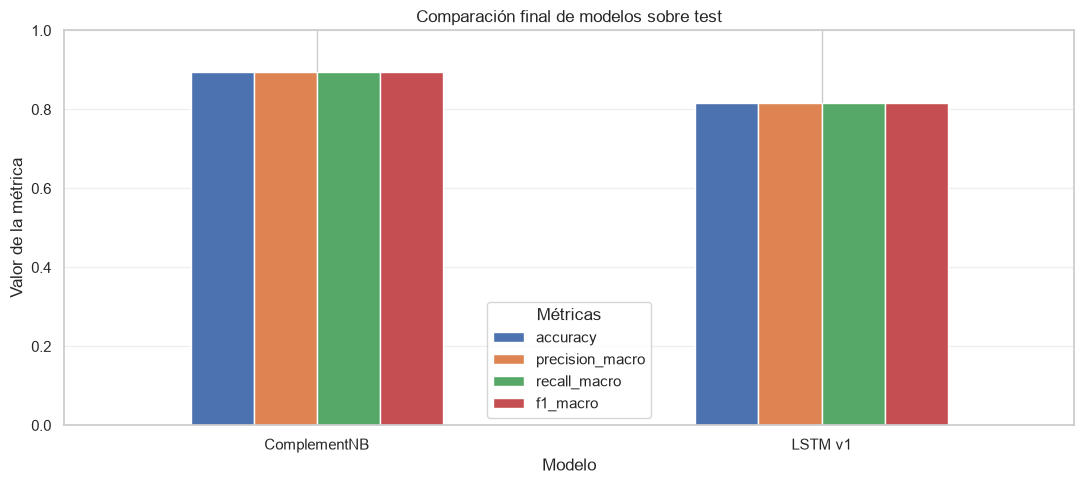

In [449]:
# ============================================================
# 65 — Comparación definitiva sobre test
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Consolidar resultados finales
resultados_test = pd.DataFrame([
    {
        "modelo": "ComplementNB",
        "accuracy": accuracy_nb_test,
        "precision_macro": precision_nb_test,
        "recall_macro": recall_nb_test,
        "f1_macro": f1_nb_test
    },
    {
        "modelo": "LSTM v1",
        "accuracy": accuracy_lstm_test,
        "precision_macro": precision_lstm_test,
        "recall_macro": recall_lstm_test,
        "f1_macro": f1_lstm_test
    }
])

print("COMPARACIÓN DEFINITIVA — CONJUNTO DE TEST")
print("-" * 65)

display(
    resultados_test.style.format({
        "accuracy": "{:.4f}",
        "precision_macro": "{:.4f}",
        "recall_macro": "{:.4f}",
        "f1_macro": "{:.4f}"
    })
)


# Calcular diferencia de F1 macro
diferencia_f1 = (
    f1_nb_test - f1_lstm_test
) * 100

print(
    f"\nDiferencia de F1 macro: "
    f"{diferencia_f1:.2f} puntos porcentuales"
)


# Gráfico comparativo
metricas = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro"
]

resultados_test.set_index("modelo")[metricas].plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparación final de modelos sobre test")
plt.ylabel("Valor de la métrica")
plt.xlabel("Modelo")
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Métricas")
plt.tight_layout()
plt.show()

## Celda 66 — Resumen general del proyecto

In [450]:
# ============================================================
# 66 — Resumen general del proyecto
# ============================================================

from IPython.display import display, Markdown

resumen_proyecto = """
# Proyecto Integrador — Clasificación de noticias AG News

## Objetivo

Desarrollar y comparar modelos de Machine Learning y Deep Learning
para clasificar noticias en cuatro categorías:

- World
- Sports
- Business
- Sci_Tech

## Dataset

- Conjunto de entrenamiento: 8.000 noticias.
- Conjunto de test: 2.000 noticias.
- Categorías: 4.
- Distribución balanceada: 2.000 noticias por categoría en entrenamiento
  y 500 por categoría en test.

## Metodología

1. Limpieza y normalización del texto.
2. Análisis exploratorio y lingüístico.
3. Vectorización TF-IDF.
4. Entrenamiento y selección de modelos tradicionales.
5. Preparación de secuencias y vocabulario para Deep Learning.
6. Implementación de redes LSTM y GRU bidireccionales.
7. Evaluación y comparación de resultados.

## Modelos evaluados

### Machine Learning

- Regresión Logística.
- Random Forest.
- LinearSVC.
- ComplementNB.

### Deep Learning

- LSTM bidireccional, dropout 0.3.
- LSTM bidireccional, dropout 0.5.
- GRU bidireccional, dropout 0.3.

## Resultado final

El modelo ComplementNB obtuvo el mejor rendimiento sobre el conjunto
de test, con un F1 macro de 0.8957.

La versión LSTM v1 obtuvo un F1 macro de 0.8158.

La diferencia fue de 7.99 puntos porcentuales a favor de ComplementNB.

## Modelo seleccionado

TF-IDF + ComplementNB.
"""

display(Markdown(resumen_proyecto))


# Proyecto Integrador — Clasificación de noticias AG News

## Objetivo

Desarrollar y comparar modelos de Machine Learning y Deep Learning
para clasificar noticias en cuatro categorías:

- World
- Sports
- Business
- Sci_Tech

## Dataset

- Conjunto de entrenamiento: 8.000 noticias.
- Conjunto de test: 2.000 noticias.
- Categorías: 4.
- Distribución balanceada: 2.000 noticias por categoría en entrenamiento
  y 500 por categoría en test.

## Metodología

1. Limpieza y normalización del texto.
2. Análisis exploratorio y lingüístico.
3. Vectorización TF-IDF.
4. Entrenamiento y selección de modelos tradicionales.
5. Preparación de secuencias y vocabulario para Deep Learning.
6. Implementación de redes LSTM y GRU bidireccionales.
7. Evaluación y comparación de resultados.

## Modelos evaluados

### Machine Learning

- Regresión Logística.
- Random Forest.
- LinearSVC.
- ComplementNB.

### Deep Learning

- LSTM bidireccional, dropout 0.3.
- LSTM bidireccional, dropout 0.5.
- GRU bidireccional, dropout 0.3.

## Resultado final

El modelo ComplementNB obtuvo el mejor rendimiento sobre el conjunto
de test, con un F1 macro de 0.8957.

La versión LSTM v1 obtuvo un F1 macro de 0.8158.

La diferencia fue de 7.99 puntos porcentuales a favor de ComplementNB.

## Modelo seleccionado

TF-IDF + ComplementNB.


## Celda 67 — Limitaciones del proyecto

In [451]:
# ============================================================
# 67 — Limitaciones del proyecto
# ============================================================

from IPython.display import display, Markdown

limitaciones_proyecto = """
## Limitaciones del proyecto

1. **Tamaño del dataset:** se trabajó con una versión reducida
   del conjunto AG News, con 10.000 noticias. Los resultados no
   necesariamente representan el comportamiento sobre el dataset
   original completo.

2. **Distribución de clases:** el conjunto está balanceado
   artificialmente. En un escenario real, la frecuencia de cada
   categoría podría ser diferente.

3. **Longitud de las secuencias:** se estableció un máximo de
   33 tokens para los modelos de Deep Learning. Los textos más
   extensos fueron truncados.

4. **Vocabulario:** el vocabulario se construyó exclusivamente
   con los datos de entrenamiento. Las palabras desconocidas
   se representaron mediante el token UNK.

5. **Entrenamiento de Deep Learning:** las redes LSTM y GRU
   utilizaron embeddings entrenados desde cero, sin embeddings
   preentrenados. Además, no se implementó empaquetado de
   secuencias para excluir explícitamente el padding del
   procesamiento recurrente.

6. **Exploración de hiperparámetros:** se probaron distintas
   configuraciones, pero no se realizó una búsqueda exhaustiva
   para todas las arquitecturas.

7. **Evaluación final:** el conjunto de test se utilizó para
   evaluar los resultados finales  y posteriormente para
   comparar ComplementNB con LSTM v1. No se utilizó para
   ajustar hiperparámetros, aunque ya no constituye una
   evaluación completamente independiente de todo el proceso.

8. **Generalización:** no se evaluó el modelo con noticias
   externas, períodos temporales diferentes ni datos de
   producción.
"""

display(Markdown(limitaciones_proyecto))


## Limitaciones del proyecto

1. **Tamaño del dataset:** se trabajó con una versión reducida
   del conjunto AG News, con 10.000 noticias. Los resultados no
   necesariamente representan el comportamiento sobre el dataset
   original completo.

2. **Distribución de clases:** el conjunto está balanceado
   artificialmente. En un escenario real, la frecuencia de cada
   categoría podría ser diferente.

3. **Longitud de las secuencias:** se estableció un máximo de
   33 tokens para los modelos de Deep Learning. Los textos más
   extensos fueron truncados.

4. **Vocabulario:** el vocabulario se construyó exclusivamente
   con los datos de entrenamiento. Las palabras desconocidas
   se representaron mediante el token UNK.

5. **Entrenamiento de Deep Learning:** las redes LSTM y GRU
   utilizaron embeddings entrenados desde cero, sin embeddings
   preentrenados. Además, no se implementó empaquetado de
   secuencias para excluir explícitamente el padding del
   procesamiento recurrente.

6. **Exploración de hiperparámetros:** se probaron distintas
   configuraciones, pero no se realizó una búsqueda exhaustiva
   para todas las arquitecturas.

7. **Evaluación final:** el conjunto de test se utilizó para
   evaluar los resultados finales  y posteriormente para
   comparar ComplementNB con LSTM v1. No se utilizó para
   ajustar hiperparámetros, aunque ya no constituye una
   evaluación completamente independiente de todo el proceso.

8. **Generalización:** no se evaluó el modelo con noticias
   externas, períodos temporales diferentes ni datos de
   producción.


## Celda 68 — Conclusiones y selección del modelo

In [452]:
# ============================================================
# 68 — Conclusiones y selección del modelo
# ============================================================

from IPython.display import display, Markdown

conclusiones_proyecto = """
## Conclusiones

El proyecto permitió desarrollar un flujo completo de clasificación
de noticias, desde la limpieza y exploración del texto hasta el
entrenamiento y evaluación de modelos de Machine Learning y
Deep Learning.

Los resultados mostraron que los modelos tradicionales basados
en TF-IDF pueden alcanzar un rendimiento competitivo en tareas
de clasificación de texto.

Entre los modelos evaluados, ComplementNB obtuvo el mejor resultado
en el conjunto de test:

- Accuracy: 0.8960
- Precision macro: 0.8957
- Recall macro: 0.8960
- F1 macro: 0.8957

La mejor arquitectura de Deep Learning fue LSTM bidireccional v1,
con un F1 macro de 0.8158 en test.

La diferencia de 7.99 puntos porcentuales en F1 macro favoreció
a ComplementNB.

### Justificación del modelo seleccionado

Se seleccionó el pipeline TF-IDF + ComplementNB por los siguientes
motivos:

1. Obtuvo el mejor F1 macro entre los modelos comparados en test.
2. También presentó el mejor rendimiento durante la validación.
3. Ofreció un equilibrio sólido entre precisión y recall para
   las cuatro categorías.
4. Su entrenamiento e inferencia requieren menos recursos
   computacionales que las arquitecturas recurrentes evaluadas.
5. Su menor complejidad facilita la implementación y el
   mantenimiento.

### Conclusión general

En este experimento, aumentar la complejidad del modelo no produjo
una mejora en el rendimiento. Las arquitecturas LSTM y GRU
permitieron explorar enfoques de Deep Learning, pero el pipeline
TF-IDF + ComplementNB resultó más efectivo para este dataset
y esta configuración experimental.

Por lo tanto, ComplementNB se considera la alternativa más
adecuada entre los modelos evaluados, teniendo en cuenta tanto
su rendimiento como su simplicidad computacional.
"""

display(Markdown(conclusiones_proyecto))


## Conclusiones

El proyecto permitió desarrollar un flujo completo de clasificación
de noticias, desde la limpieza y exploración del texto hasta el
entrenamiento y evaluación de modelos de Machine Learning y
Deep Learning.

Los resultados mostraron que los modelos tradicionales basados
en TF-IDF pueden alcanzar un rendimiento competitivo en tareas
de clasificación de texto.

Entre los modelos evaluados, ComplementNB obtuvo el mejor resultado
en el conjunto de test:

- Accuracy: 0.8960
- Precision macro: 0.8957
- Recall macro: 0.8960
- F1 macro: 0.8957

La mejor arquitectura de Deep Learning fue LSTM bidireccional v1,
con un F1 macro de 0.8158 en test.

La diferencia de 7.99 puntos porcentuales en F1 macro favoreció
a ComplementNB.

### Justificación del modelo seleccionado

Se seleccionó el pipeline TF-IDF + ComplementNB por los siguientes
motivos:

1. Obtuvo el mejor F1 macro entre los modelos comparados en test.
2. También presentó el mejor rendimiento durante la validación.
3. Ofreció un equilibrio sólido entre precisión y recall para
   las cuatro categorías.
4. Su entrenamiento e inferencia requieren menos recursos
   computacionales que las arquitecturas recurrentes evaluadas.
5. Su menor complejidad facilita la implementación y el
   mantenimiento.

### Conclusión general

En este experimento, aumentar la complejidad del modelo no produjo
una mejora en el rendimiento. Las arquitecturas LSTM y GRU
permitieron explorar enfoques de Deep Learning, pero el pipeline
TF-IDF + ComplementNB resultó más efectivo para este dataset
y esta configuración experimental.

Por lo tanto, ComplementNB se considera la alternativa más
adecuada entre los modelos evaluados, teniendo en cuenta tanto
su rendimiento como su simplicidad computacional.


# Modulo 3  CHECKPOINT — CLASIFICADOR SUPERVISADO

## Celda 69 — Verificación del entorno y los recursos existentes

In [453]:
# ============================================================
# CHECKPOINT — CLASIFICADOR SUPERVISADO
# 69 — Verificación de recursos existentes
# ============================================================

# Variables necesarias para desarrollar el checkpoint
variables_necesarias = [
    "df_train_processed",
    "df_test_processed",
    "mejor_modelo_nb",
    "y_train",
    "y_test",
    "y_pred_test_nb"
]

# Comprobar qué variables están disponibles
for variable in variables_necesarias:
    disponible = variable in globals()
    estado = "Disponible" if disponible else "No disponible"
    print(f"{variable}: {estado}")

# Mostrar las dimensiones de los conjuntos procesados
if "df_train_processed" in globals():
    print("\nDimensiones de entrenamiento:")
    print(df_train_processed.shape)

if "df_test_processed" in globals():
    print("\nDimensiones de prueba:")
    print(df_test_processed.shape)

# Mostrar la configuración del pipeline seleccionado
if "mejor_modelo_nb" in globals():
    print("\nConfiguración del modelo seleccionado:")
    print(mejor_modelo_nb)

df_train_processed: Disponible
df_test_processed: Disponible
mejor_modelo_nb: Disponible
y_train: Disponible
y_test: Disponible
y_pred_test_nb: Disponible

Dimensiones de entrenamiento:
(8000, 7)

Dimensiones de prueba:
(2000, 4)

Configuración del modelo seleccionado:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.95, max_features=20000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('clasificador', ComplementNB(alpha=0.5, norm=True))])


## Celda 70 — Verificación de columnas y etiquetas

In [454]:
# ============================================================
# 70 — Validación de datos de entrada
# ============================================================

# Columnas necesarias para el clasificador
columnas_requeridas = ["text_processed", "label"]

# Verificar columnas en entrenamiento y prueba
for nombre, df in [
    ("Entrenamiento", df_train_processed),
    ("Prueba", df_test_processed)
]:
    faltantes = [
        columna for columna in columnas_requeridas
        if columna not in df.columns
    ]

    print(f"\nConjunto de {nombre}:")
    print(f"Registros: {len(df)}")
    print(f"Columnas disponibles: {list(df.columns)}")

    if faltantes:
        raise ValueError(
            f"Faltan columnas necesarias: {faltantes}"
        )

    print("Columnas requeridas: OK")

# Verificar distribución de categorías
print("\nDistribución de categorías — Entrenamiento:")
display(df_train_processed["label"].value_counts().sort_index())

print("\nDistribución de categorías — Prueba:")
display(df_test_processed["label"].value_counts().sort_index())

# Verificar valores nulos y textos vacíos
for nombre, df in [
    ("Entrenamiento", df_train_processed),
    ("Prueba", df_test_processed)
]:
    nulos = df[columnas_requeridas].isna().sum().sum()
    vacios = df["text_processed"].astype(str).str.strip().eq("").sum()

    print(f"\n{nombre}:")
    print(f"Valores nulos: {nulos}")
    print(f"Textos vacíos: {vacios}")


Conjunto de Entrenamiento:
Registros: 8000
Columnas disponibles: ['text', 'label', 'text_clean', 'text_processed', 'tokens_originales', 'tokens_procesados', 'num_tokens']
Columnas requeridas: OK

Conjunto de Prueba:
Registros: 2000
Columnas disponibles: ['text', 'label', 'text_clean', 'text_processed']
Columnas requeridas: OK

Distribución de categorías — Entrenamiento:


label
Business    2000
Sci_Tech    2000
Sports      2000
World       2000
Name: count, dtype: int64


Distribución de categorías — Prueba:


label
Business    500
Sci_Tech    500
Sports      500
World       500
Name: count, dtype: int64


Entrenamiento:
Valores nulos: 0
Textos vacíos: 0

Prueba:
Valores nulos: 0
Textos vacíos: 0


Los resultados confirman que:
- Entrenamiento: 8.000 registros, 2.000 por categoría.
- Prueba: 2.000 registros, 500 por categoría.
- Ambos conjuntos tienen las cuatro categorías.
- No hay valores nulos ni textos vacíos.
- Las columnas text_processed y label están disponibles.

## Celda 71 — Verificación de separación y prevención de Data Leakage

In [455]:
# ============================================================
# 71 — Verificación de separación y Data Leakage
# ============================================================

# Obtener los textos procesados de cada conjunto
X_train_checkpoint = df_train_processed["text_processed"]
X_test_checkpoint = df_test_processed["text_processed"]

# Obtener las etiquetas correspondientes
y_train_checkpoint = df_train_processed["label"]
y_test_checkpoint = df_test_processed["label"]

# Comprobar posibles textos compartidos entre conjuntos
textos_compartidos = set(X_train_checkpoint) & set(X_test_checkpoint)

print("Registros de entrenamiento:", len(X_train_checkpoint))
print("Registros de prueba:", len(X_test_checkpoint))
print("Textos compartidos:", len(textos_compartidos))

# Recuperar el vectorizador del pipeline
vectorizador_checkpoint = mejor_modelo_nb.named_steps["tfidf"]

# Comprobar que el vectorizador fue ajustado
print("\nVocabulario aprendido:", len(vectorizador_checkpoint.vocabulary_))

# Verificar que el vocabulario no exceda el límite configurado
print("Máximo de características:", vectorizador_checkpoint.max_features)
print("Rango de n-gramas:", vectorizador_checkpoint.ngram_range)

# Confirmar las etiquetas utilizadas
print("\nCategorías de entrenamiento:")
print(sorted(y_train_checkpoint.unique()))

print("\nCategorías de prueba:")
print(sorted(y_test_checkpoint.unique()))

Registros de entrenamiento: 8000
Registros de prueba: 2000
Textos compartidos: 0

Vocabulario aprendido: 20000
Máximo de características: 20000
Rango de n-gramas: (1, 2)

Categorías de entrenamiento:
['Business', 'Sci_Tech', 'Sports', 'World']

Categorías de prueba:
['Business', 'Sci_Tech', 'Sports', 'World']


## Celda 72 — Evaluación del clasificador supervisado

In [456]:
# ============================================================
# 72 — Evaluación del modelo ComplementNB
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Generar predicciones sobre el conjunto de prueba
# El pipeline aplica transform() con el TF-IDF ya ajustado
y_pred_checkpoint = mejor_modelo_nb.predict(X_test_checkpoint)

# Calcular métricas generales
accuracy_checkpoint = accuracy_score(
    y_test_checkpoint, y_pred_checkpoint
)

precision_checkpoint = precision_score(
    y_test_checkpoint, y_pred_checkpoint, average="macro"
)

recall_checkpoint = recall_score(
    y_test_checkpoint, y_pred_checkpoint, average="macro"
)

f1_checkpoint = f1_score(
    y_test_checkpoint, y_pred_checkpoint, average="macro"
)

# Mostrar resultados generales
print("RESULTADOS DEL CLASIFICADOR")
print("=" * 45)
print(f"Accuracy:       {accuracy_checkpoint:.4f}")
print(f"Precision macro: {precision_checkpoint:.4f}")
print(f"Recall macro:    {recall_checkpoint:.4f}")
print(f"F1 macro:        {f1_checkpoint:.4f}")

# Mostrar métricas por categoría
print("\nREPORTE DE CLASIFICACIÓN")
print("=" * 45)

print(
    classification_report(
        y_test_checkpoint,
        y_pred_checkpoint,
        zero_division=0
    )
)

RESULTADOS DEL CLASIFICADOR
Accuracy:       0.8960
Precision macro: 0.8957
Recall macro:    0.8960
F1 macro:        0.8957

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

    Business       0.85      0.86      0.85       500
    Sci_Tech       0.89      0.86      0.88       500
      Sports       0.94      0.97      0.96       500
       World       0.90      0.89      0.90       500

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000



Interpretación de resultados


```
Categoría	Precision	Recall	F1-score
Business	0.85	0.86	0.85
Sci_Tech	0.89	0.86	0.88
Sports	0.94	0.97	0.96
World	0.90	0.89	0.90
```




- Sports es la categoría mejor identificada, con F1 de 0.96.
- Business presenta el rendimiento más bajo, con F1 de 0.85.
- Sci_Tech también presenta dificultades, especialmente en el recall (0.86).
- World mantiene un rendimiento equilibrado, con F1 de 0.90.
El resultado global es un F1 macro de 0.8957, lo que indica un rendimiento sólido y relativamente equilibrado entre las cuatro categorías.

## Celda 73 — Matriz de confusión

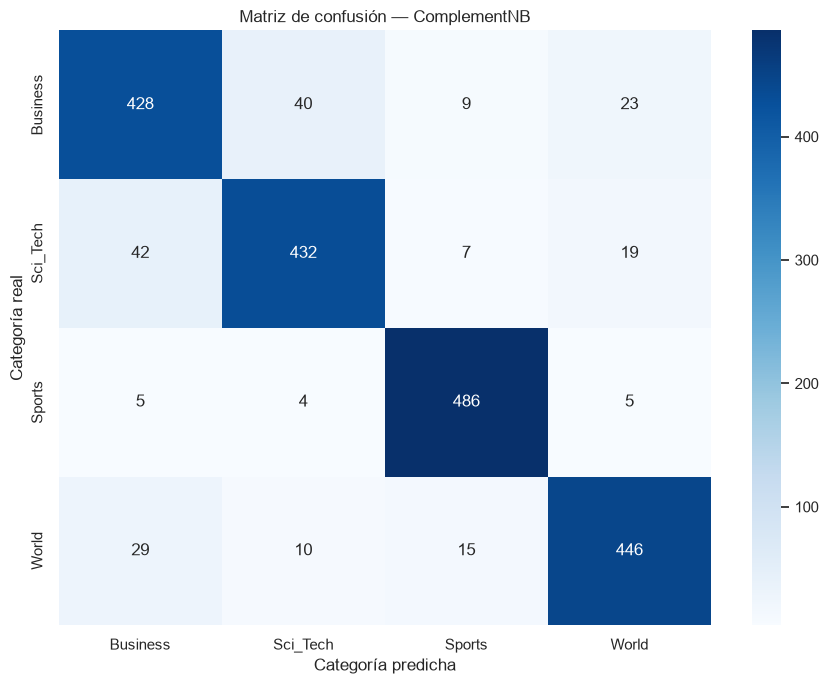

In [457]:
# ============================================================
# 73 — Matriz de confusión
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Definir el orden de las categorías
orden_etiquetas = [
    "Business",
    "Sci_Tech",
    "Sports",
    "World"
]

# Calcular la matriz de confusión
matriz_confusion_checkpoint = confusion_matrix(
    y_test_checkpoint,
    y_pred_checkpoint,
    labels=orden_etiquetas
)

# Crear la visualización
plt.figure(figsize=(9, 7))

sns.heatmap(
    matriz_confusion_checkpoint,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=orden_etiquetas,
    yticklabels=orden_etiquetas
)

plt.title("Matriz de confusión — ComplementNB")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.tight_layout()
plt.show()

In [458]:
# ============================================================
# PASO 2 — VERIFICACIÓN DE DIMENSIONES Y CATEGORÍAS
# ============================================================

print("Dimensiones de los datos:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nDimensiones de las predicciones:")
print("y_test_checkpoint:", y_test_checkpoint.shape)
print("y_pred_checkpoint:", y_pred_checkpoint.shape)

print("\nCategorías reales:")
print(pd.Series(y_test_checkpoint).value_counts())

print("\nCategorías predichas:")
print(pd.Series(y_pred_checkpoint).value_counts())

print("\nCoincidencia de dimensiones:",
      len(y_test_checkpoint) == len(y_pred_checkpoint))

Dimensiones de los datos:
X_train: (6400,)
X_test: (2000,)
y_train: (6400,)
y_test: (2000,)

Dimensiones de las predicciones:
y_test_checkpoint: (2000,)
y_pred_checkpoint: (2000,)

Categorías reales:
label
World       500
Business    500
Sports      500
Sci_Tech    500
Name: count, dtype: int64

Categorías predichas:
Sports      517
Business    504
World       493
Sci_Tech    486
Name: count, dtype: int64

Coincidencia de dimensiones: True


## Celda 74 — Guardar informe de clasificación

In [459]:
# ============================================================
# 74 — GUARDAR INFORME DE CLASIFICACIÓN
# ============================================================

from sklearn.metrics import classification_report

# Generar el informe de clasificación
informe_checkpoint = classification_report(
    y_test_checkpoint,
    y_pred_checkpoint,
    labels=["Business", "Sci_Tech", "Sports", "World"],
    digits=4,
    zero_division=0
)

# Definir la ruta completa del archivo
RUTA_INFORME = RUTA_METRICAS / "classification_report.txt"

# Guardar el informe en un archivo de texto
with open(RUTA_INFORME, "w", encoding="utf-8") as archivo:
    archivo.write("CLASIFICACIÓN DE NOTICIAS AG NEWS\n")
    archivo.write("Modelo: TF-IDF + ComplementNB\n")
    archivo.write("Conjunto de evaluación: Test\n\n")
    archivo.write(informe_checkpoint)

print("Informe guardado correctamente.")
print("Ubicación:", RUTA_INFORME)

# Mostrar el contenido del informe
print("\n", informe_checkpoint)

Informe guardado correctamente.
Ubicación: D:\programacion\python\ag-news-text-classifier\results\metrics\classification_report.txt

               precision    recall  f1-score   support

    Business     0.8492    0.8560    0.8526       500
    Sci_Tech     0.8889    0.8640    0.8763       500
      Sports     0.9400    0.9720    0.9558       500
       World     0.9047    0.8920    0.8983       500

    accuracy                         0.8960      2000
   macro avg     0.8957    0.8960    0.8957      2000
weighted avg     0.8957    0.8960    0.8957      2000



## Celda 75 — Guardar matriz de confusión

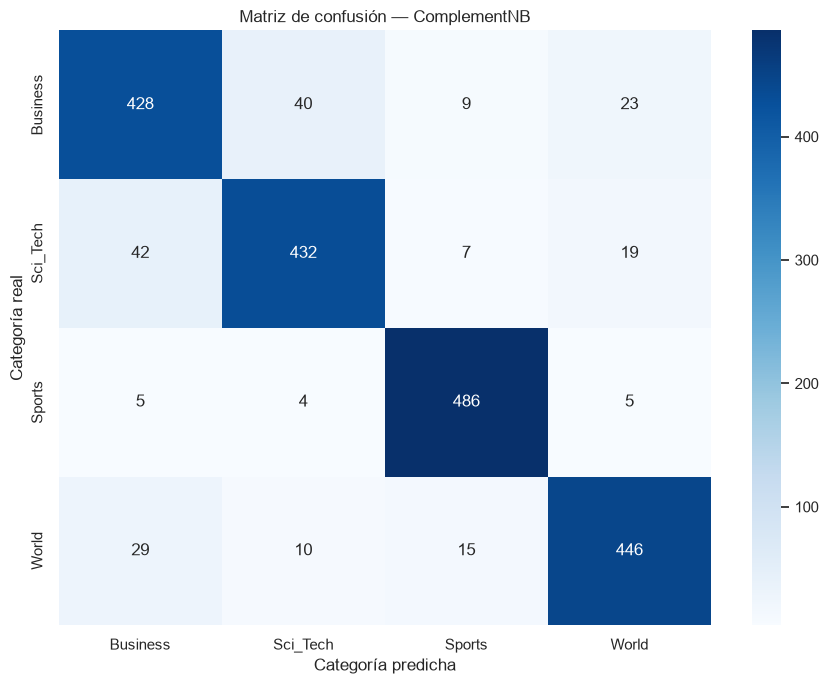

Matriz de confusión guardada correctamente.
Ubicación: D:\programacion\python\ag-news-text-classifier\results\figures\confusion_matrix_complementnb.png


In [462]:
# ============================================================
# 75 — GUARDAR MATRIZ DE CONFUSIÓN
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Crear la visualización
plt.figure(figsize=(9, 7))

sns.heatmap(
    matriz_confusion_checkpoint,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=orden_etiquetas,
    yticklabels=orden_etiquetas
)

plt.title("Matriz de confusión — ComplementNB")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.tight_layout()

# Guardar la figura
RUTA_MATRIZ = RUTA_FIGURAS / "confusion_matrix_complementnb.png"

plt.savefig(
    RUTA_MATRIZ,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Matriz de confusión guardada correctamente.")
print("Ubicación:", RUTA_MATRIZ)

## Celda 76 — Verificar archivos de resultados

In [461]:
# ============================================================
# CELDA 76 — VERIFICACIÓN DE ARCHIVOS GENERADOS
# ============================================================

archivos_esperados = {
    "Informe de clasificación": RUTA_METRICAS / "classification_report.txt",
    "Matriz de confusión": RUTA_FIGURAS / "confusion_matrix_complementnb.png"
}

print("VERIFICACIÓN DE ARCHIVOS\n")

for nombre, ruta in archivos_esperados.items():
    if ruta.exists():
        tamaño_kb = ruta.stat().st_size / 1024
        print(f"✓ {nombre}: {ruta.name} ({tamaño_kb:.2f} KB)")
    else:
        print(f"✗ {nombre}: No encontrado en {ruta}")

VERIFICACIÓN DE ARCHIVOS

✓ Informe de clasificación: classification_report.txt (0.53 KB)
✓ Matriz de confusión: confusion_matrix_complementnb.png (124.25 KB)


## Conclusiones del checkpoint — Clasificación de textos AG News
El checkpoint permitió construir y evaluar un primer clasificador supervisado capaz de categorizar noticias en cuatro categorías: Business, Sci_Tech, Sports y World, utilizando TF-IDF para representar los textos y ComplementNB como algoritmo de clasificación.

Los resultados obtenidos muestran un desempeño general sólido, con una accuracy del 89,60 % y un F1-score macro de 0,8957, lo que indica que el modelo consigue mantener un rendimiento equilibrado entre las cuatro categorías.

Al analizar las métricas individuales, la categoría Sports obtuvo los mejores resultados, con un F1-score de 0,9558 y un recall del 97,20 %. En cambio, Business presentó el rendimiento más bajo, con un F1-score de 0,8526. Esto evidencia que algunas categorías tienen características lingüísticas más fáciles de distinguir que otras.

La matriz de confusión permitió observar que las principales dificultades aparecen entre las categorías Business y Sci_Tech, cuyos contenidos pueden compartir vocabulario relacionado con empresas, tecnología, mercados e innovación. En total, el modelo clasificó correctamente 1.792 de las 2.000 noticias de prueba, con 208 errores.

Otro aspecto importante fue la separación de los datos de entrenamiento, validación y prueba, evitando utilizar el conjunto de prueba durante el entrenamiento y ajustando el vectorizador TF-IDF únicamente con los datos de entrenamiento. Esto permite obtener una evaluación más confiable del comportamiento del modelo frente a noticias que no había visto anteriormente.

Como conclusión general, ComplementNB constituye una buena línea base para el proyecto. El checkpoint demuestra que es posible obtener resultados cercanos al 90 % de accuracy mediante técnicas tradicionales de procesamiento de lenguaje natural y aprendizaje automático, sin necesidad de recurrir inicialmente a arquitecturas neuronales más complejas.